# Calibrated Selective Referral for Skin Lesion AI on HAM10000

## Calibration uncertainty abstention subgroup analysis and compute aware evaluation

**Suggested manuscript title:** Calibrated Selective Referral for Skin Lesion AI on HAM10000

This notebook implements a reviewer-ready Google Colab workflow for a skin-lesion AI study centred on calibrated triage support rather than autonomous diagnosis.

**V3 data-loading fix:** this version mounts Google Drive before creating any `/content/drive` directories, falls back to `/content/gdrive` if Colab reports that `/content/drive` is non-empty, searches for existing extracted HAM10000 data, accepts a manually supplied `dataverse_files.zip`, and can attempt an official Harvard Dataverse API download if no local archive is found. This prevents the previous `FileNotFoundError` caused by assuming `/content/drive/MyDrive/dataverse_files.zip` already exists.

The workflow is aligned with the editor and reviewer revisions:

1. **Data integrity first**: robust extraction, metadata audit, image-path validation, lesion-level train/validation/test splitting, and leakage checks.
2. **Transparent model selection**: validation-only model selection, repeated-seed confirmation, and a secondary clean metadata ablation.
3. **Long-tail classification**: image-only transfer-learning baselines and long-tail loss ablations.
4. **Clinical reliability**: balanced accuracy, macro-F1, per-class recall, melanoma recall, Brier score, NLL, ECE, MCE, reliability diagrams, and calibration confidence intervals.
5. **Selective referral**: max-probability uncertainty, entropy, margin, a validation-chosen referral threshold, risk-coverage curves, melanoma-specific referral counts, and optional MC Dropout.
6. **Subgroup analysis within HAM10000**: subgroup sizes, class distributions, melanoma denominators, uncertainty intervals, and subgroup selective-referral tables for sex, age group, anatomical site, and diagnosis-confirmation type.
7. **Related-domain robustness and stress testing**: optional ISIC 2018 Challenge Task 3 test evaluation if the official test files are downloaded or present in the input archive, explicitly framed as related-domain robustness rather than independent external validation, plus acquisition-style perturbation tests.
8. **Deployment caution**: TFLite export, numerical-equivalence checks, latency, approximate memory, and post-quantization performance reporting without claiming deployment feasibility from export alone.
9. **Publication outputs**: tables, figures, bootstrap confidence intervals, runtime logs, split files, reviewer exports, and a manifest that maps manuscript claims to reproducible files.

**Boundary statement:** HAM10000 does not contain reliable skin-tone or race labels. This notebook therefore performs *internal metadata subgroup analysis* on HAM10000 and treats any skin-tone fairness claim as requiring an external dataset such as Fitzpatrick17k or DDI. The ISIC 2018 Challenge Task 3 test analysis in this notebook is not independent clinical external validation because it is closely related to the HAM10000/ISIC challenge ecosystem; it should be described as a related-domain robustness analysis.


## 0. Run policy and recommended Colab settings

This version is configured for a **CPU-only full publishable run**.

Use Colab with the standard CPU runtime. You may also open it in a GPU runtime, but this notebook explicitly hides all CUDA devices with:

```python
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
```

This is intentional. It prevents the repeated `CUDA_ERROR_INVALID_HANDLE` failures seen in earlier GPU sessions by making TensorFlow use CPU only.

This version is configured for a **fresh full run**, not a smoke test:

- `CONFIG["force_retrain"] = True`
- baseline training is enabled
- model funnel is enabled
- long-tail loss ablation is enabled
- repeated-seed training is enabled
- multimodal ablation is enabled
- calibration, uncertainty, selective referral, subgroup analysis, bootstrap CIs, stress tests, optional related-domain ISIC2018 evaluation, Grad-CAM, and TFLite export are enabled

### Practical CPU warning

A full CPU-only run over all selected backbones, losses, repeated seeds, MC Dropout, and bootstrap intervals can take a long time. This is more stable than the previous GPU path, but much slower. For a quick debugging run, reduce epochs and turn off selected ablations only after the full workflow has been verified.

### Required run order

Run cells from the top. Do not import TensorFlow before the CPU setup cell. If you already ran a TensorFlow/GPU cell in the current Colab runtime, restart the runtime and run this notebook from the first cell.


In [1]:
# --- Colab package setup ---
# Most packages are preinstalled in Colab. Run this cell once if needed.

import sys, subprocess, pkgutil

REQUIRED = [
    "numpy", "pandas", "matplotlib", "sklearn", "tensorflow", "PIL", "joblib"
]

missing = []
for pkg in REQUIRED:
    import_name = "PIL" if pkg == "PIL" else pkg
    if pkgutil.find_loader(import_name) is None:
        missing.append(pkg)

if missing:
    print("Missing packages:", missing)
    install_map = {"PIL": "pillow", "sklearn": "scikit-learn"}
    pip_names = [install_map.get(m, m) for m in missing]
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + pip_names)
else:
    print("Core packages are available.")

Core packages are available.


/tmp/ipykernel_1891/3082795408.py:13: DeprecationWarning: 'pkgutil.find_loader' is deprecated and slated for removal in Python 3.14; use importlib.util.find_spec() instead
  if pkgutil.find_loader(import_name) is None:


In [2]:
# --- FIRST TensorFlow setup cell: CPU-only, full-run version ---
# Run this cell only after a fresh Colab runtime restart.
# Do not import TensorFlow in any earlier cell.
#
# Purpose:
# 1) Force CPU-only TensorFlow execution before TensorFlow is imported.
# 2) Remove the CUDA invalid-handle failure path completely.
# 3) Validate basic TensorFlow CPU kernels before data/model construction.

import os

# Force CPU execution BEFORE importing TensorFlow.
# This is the critical line: it hides CUDA devices from TensorFlow.
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

# Conservative TensorFlow runtime settings.
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_XLA_FLAGS"] = "--tf_xla_auto_jit=0"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ.pop("TF_GPU_ALLOCATOR", None)

import re
import gc
import sys
import json
import math
import time
import zipfile
import random
import shutil
import hashlib
import warnings
import subprocess
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance, ImageOps
import joblib

from IPython.display import display, Markdown

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Keep TensorFlow conservative and deterministic enough for a defensible CPU run.
tf.config.set_soft_device_placement(True)
try:
    tf.config.optimizer.set_jit(False)
except Exception as e:
    print("Could not disable XLA JIT:", e)

# Explicitly verify that TensorFlow sees no GPU.
physical_gpus = tf.config.list_physical_devices("GPU")
logical_gpus = tf.config.list_logical_devices("GPU")
if physical_gpus or logical_gpus:
    raise RuntimeError(
        "CPU-only mode was requested, but TensorFlow can still see GPU devices. "
        "Restart the runtime and make sure this setup cell is run before any TensorFlow import."
    )

def runtime_guard(stage="runtime check"):
    """Validate basic TensorFlow CPU kernels.

    The function name gpu_runtime_guard is retained as an alias for downstream
    compatibility, but in this CPU-only notebook it checks CPU execution.
    """
    try:
        with tf.device("/CPU:0"):
            a = tf.constant([1, 2, 3], dtype=tf.int32)
            b = tf.cast(a, tf.float32)               # tests Cast
            c = tf.equal(a, tf.constant([1, 0, 3]))  # tests Equal
            m = tf.random.uniform((128, 128), dtype=tf.float32)
            mm = tf.linalg.matmul(m, m)              # tests compute
            checksum = (
                float(tf.reduce_sum(mm).numpy())
                + float(tf.reduce_sum(b).numpy())
                + float(tf.reduce_sum(tf.cast(c, tf.float32)).numpy())
            )
        print(f"[{stage}] CPU TensorFlow sanity check passed; checksum={checksum:.3f}")
        return True
    except Exception as e:
        raise RuntimeError(
            f"[{stage}] TensorFlow CPU sanity check failed. Restart the runtime and rerun from the top."
        ) from e

# Backward-compatible alias used by later cells.
gpu_runtime_guard = runtime_guard

runtime_guard("initial CPU setup")

from sklearn.model_selection import GroupShuffleSplit
try:
    from sklearn.model_selection import StratifiedGroupKFold
    HAS_SGK = True
except Exception:
    HAS_SGK = False

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    balanced_accuracy_score, f1_score, recall_score, precision_score,
    classification_report, confusion_matrix, roc_auc_score,
    average_precision_score, log_loss, accuracy_score
)

warnings.filterwarnings("ignore")

print("TensorFlow:", tf.__version__)
print("CPU-only mode active.")
print("Physical GPUs visible to TensorFlow:", tf.config.list_physical_devices("GPU"))
print("Logical GPUs visible to TensorFlow:", tf.config.list_logical_devices("GPU"))
print("Physical CPUs:", tf.config.list_physical_devices("CPU"))


[initial CPU setup] CPU TensorFlow sanity check passed; checksum=520437.094
TensorFlow: 2.20.0
CPU-only mode active.
Physical GPUs visible to TensorFlow: []
Logical GPUs visible to TensorFlow: []
Physical CPUs: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [3]:
# --- Configuration, safe Google Drive mount, and output directories ---
# V4 fix: mount Drive before creating any /content/drive subdirectories. Earlier versions
# created /content/drive/MyDrive/... before drive.mount(), which can trigger Colab's
# "Mountpoint must not already contain files" error.

CONFIG = {
    # Data paths and acquisition
    "mount_google_drive": True,
    "google_drive_mount_points": ["/content/drive", "/content/gdrive"],
    "use_google_drive_for_work_dir": True,
    "google_drive_work_dir_name": "ham10000_trustworthy_ai",
    "local_fallback_work_dir": "/content/ham10000_trustworthy_ai",
    "drive_zip_path": "/content/drive/MyDrive/dataverse_files.zip",  # rewritten after successful Drive mount
    "work_dir": None,  # resolved below, after mount
    "project_name": "trustworthy_skin_lesion_ai_ham10000_cpu_full",
    "download_ham10000_dataverse_if_missing": True,
    "ham10000_dataverse_server": "https://dataverse.harvard.edu",
    "ham10000_dataverse_persistent_id": "doi:10.7910/DVN/DBW86T",
    "ham10000_dataverse_download_filename": "dataverse_files.zip",
    "allow_extracted_ham10000_without_zip": True,
    "compute_data_zip_md5": False,
    "ham10000_recursive_drive_zip_search": True,

    # Reproducibility
    "seed": 42,
    "final_seeds": [42, 2026, 3407],
    "run_final_three_seeds": True,
    "force_retrain": True,
    "main_model_selection_image_only": True,
    "include_multimodal_in_model_selection": False,
    "run_final_selected_seed_confirmation": True,

    # Data split
    "test_size": 0.20,
    "val_size_of_trainval": 0.20,
    "split_by": "lesion_id",
    "label_col": "dx",
    "image_id_col": "image_id",

    # Image/model settings
    "image_size": 224,
    "batch_size": 8,
    "preview_tfdata_batch": False,
    "data_pipeline_backend": "keras_sequence_cpu",
    "force_cpu_training": True,
    "force_gpu_training": False,
    "build_model_on_cpu": True,
    "compile_model_on_cpu": True,
    "run_model_build_preview": False,
    "backbone": "EfficientNetB0",
    "use_metadata": False,
    "dropout_rate": 0.30,

    # Training schedule
    "head_epochs": 8,
    "finetune_epochs": 20,
    "early_stopping_patience": 5,
    "finetune_last_n_layers": 40,
    "head_learning_rate": 1e-3,
    "finetune_learning_rate": 1e-5,

    # Imbalance strategy
    "loss_type": "weighted_ce",
    "focal_gamma": 2.0,
    "class_balanced_beta": 0.9999,

    # Model-comparison / ablation switches: all enabled for a full publishable run
    "run_training": True,
    "run_model_funnel": True,
    "funnel_backbones": ["EfficientNetB0", "MobileNetV2", "ResNet50"],
    "run_long_tail_ablation": True,
    "long_tail_losses": ["weighted_ce", "focal", "class_balanced_ce"],
    "run_multimodal_ablation": True,

    # Evaluation
    "n_bins_ece": 15,
    "bootstrap_reps": 1000,
    "run_bootstrap": True,
    "min_subgroup_n": 30,
    "calibration_bootstrap_reps": 1000,
    "ece_acceptability_note": "No universal clinical ECE threshold is assumed. ECE <= 0.05 is treated only as an exploratory desirable calibration target, not as deployment clearance.",

    # Selective referral operating point selected on validation data only
    "primary_uncertainty_score": "entropy",
    "referral_target_selective_risk": 0.15,
    "referral_minimum_validation_coverage": 0.50,
    "referral_threshold_selection_rule": "maximum validation coverage with selective risk <= target risk; if none, report minimum observed validation risk",

    # Uncertainty
    "run_mc_dropout": True,
    "mc_dropout_passes": 20,
    "mc_dropout_max_n": 500,

    # Related-domain/stress tests
    "download_isic2018_task3_test_if_missing": True,
    "isic2018_download_dir": "/content/ISIC2018",
    "run_isic2018_related_domain_if_found": True,
    # Backward-compatible alias retained for older cells/scripts; manuscript wording should use related-domain robustness, not external validation.
    "run_isic2018_external_if_found": True,
    "near_duplicate_dhash_threshold": 5,
    "run_stress_tests": True,
    "stress_test_max_images": 1000,
    "run_gradcam_example": True,

    # Compression and deployment checks
    "run_tflite_export": True,
    "tflite_profile_max_n": 200,
    "tflite_performance_max_n": None,
    "generate_reviewer_compliance_matrix": True,
}


def _is_real_colab_drive_mount(mount_base: Path) -> bool:
    """Return True only when the mount base appears to be a real mounted filesystem."""
    try:
        return mount_base.exists() and os.path.ismount(str(mount_base)) and (mount_base / "MyDrive").exists()
    except Exception:
        return False


def mount_google_drive_safely(config: dict) -> dict:
    """Mount Google Drive without failing on a polluted /content/drive mountpoint.

    If /content/drive contains locally created files, Colab can refuse to mount there.
    This function then tries /content/gdrive. If Drive cannot be mounted, the notebook
    uses a local /content work directory and the data acquisition cell gives manual options.
    """
    info = {
        "requested": bool(config.get("mount_google_drive", True)),
        "mounted": False,
        "mount_base": None,
        "mydrive": None,
        "errors": [],
    }
    if not info["requested"]:
        info["errors"].append("mount_google_drive is False")
        return info

    try:
        from google.colab import drive as colab_drive
    except Exception as e:
        info["errors"].append(f"google.colab.drive unavailable: {repr(e)}")
        return info

    for mount_str in config.get("google_drive_mount_points", ["/content/drive", "/content/gdrive"]):
        mount_base = Path(mount_str)
        if _is_real_colab_drive_mount(mount_base):
            info.update({"mounted": True, "mount_base": str(mount_base), "mydrive": str(mount_base / "MyDrive")})
            return info
        try:
            mount_base.mkdir(parents=True, exist_ok=True)
            colab_drive.mount(str(mount_base), force_remount=False)
            if (mount_base / "MyDrive").exists():
                info.update({"mounted": True, "mount_base": str(mount_base), "mydrive": str(mount_base / "MyDrive")})
                return info
            info["errors"].append(f"Mounted attempt at {mount_base}, but MyDrive was not found.")
        except Exception as e:
            info["errors"].append(f"{mount_base}: {repr(e)}")

    return info


DRIVE_INFO = mount_google_drive_safely(CONFIG)
MYDRIVE = Path(DRIVE_INFO["mydrive"]) if DRIVE_INFO.get("mounted") else None
CONFIG["drive_mount_info"] = DRIVE_INFO

if MYDRIVE is not None:
    WORK_DIR = MYDRIVE / CONFIG["google_drive_work_dir_name"]
    CONFIG["drive_zip_path"] = str(MYDRIVE / "dataverse_files.zip")
    print("Google Drive mounted at:", DRIVE_INFO["mount_base"])
    print("MyDrive path:", MYDRIVE)
else:
    WORK_DIR = Path(CONFIG["local_fallback_work_dir"])
    print("Google Drive not mounted; using local fallback work directory:", WORK_DIR)
    if DRIVE_INFO.get("errors"):
        print("Drive mount messages:")
        for err in DRIVE_INFO["errors"]:
            print(" -", err)

CONFIG["work_dir"] = str(WORK_DIR)

RAW_DIR = WORK_DIR / "raw"
DATA_DIR = WORK_DIR / "data"
SPLIT_DIR = WORK_DIR / "splits"
MODEL_DIR = WORK_DIR / "models"
FIG_DIR = WORK_DIR / "figures"
RESULT_DIR = WORK_DIR / "results"
CACHE_DIR = WORK_DIR / "cache"

for d in [RAW_DIR, DATA_DIR, SPLIT_DIR, MODEL_DIR, FIG_DIR, RESULT_DIR, CACHE_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Common places checked by the HAM10000 acquisition cell.
common_dirs = [
    str(RAW_DIR),
    "/content/HAM10000",
    "/content/ham10000",
    "/content/data/HAM10000",
    "/content/data/ham10000",
]
if MYDRIVE is not None:
    common_dirs.extend([
        str(MYDRIVE / "HAM10000"),
        str(MYDRIVE / "ham10000"),
        str(MYDRIVE / "dataverse_files"),
        str(MYDRIVE / CONFIG["google_drive_work_dir_name"] / "raw"),
    ])
CONFIG["ham10000_common_data_dirs"] = list(dict.fromkeys(common_dirs))

with open(WORK_DIR / "config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)

# CPU-only full run: mixed precision is disabled.
USE_MIXED_PRECISION = False
tf.keras.backend.clear_session()
tf.keras.mixed_precision.set_global_policy("float32")
print("Mixed precision disabled; policy set to:", tf.keras.mixed_precision.global_policy())
print("CPU-only full run configuration saved to:", WORK_DIR / "config.json")
CONFIG


Mounted at /content/drive
Google Drive mounted at: /content/drive
MyDrive path: /content/drive/MyDrive
Mixed precision disabled; policy set to: <DTypePolicy "float32">
CPU-only full run configuration saved to: /content/drive/MyDrive/ham10000_trustworthy_ai/config.json


{'mount_google_drive': True,
 'google_drive_mount_points': ['/content/drive', '/content/gdrive'],
 'use_google_drive_for_work_dir': True,
 'google_drive_work_dir_name': 'ham10000_trustworthy_ai',
 'local_fallback_work_dir': '/content/ham10000_trustworthy_ai',
 'drive_zip_path': '/content/drive/MyDrive/dataverse_files.zip',
 'work_dir': '/content/drive/MyDrive/ham10000_trustworthy_ai',
 'project_name': 'trustworthy_skin_lesion_ai_ham10000_cpu_full',
 'download_ham10000_dataverse_if_missing': True,
 'ham10000_dataverse_server': 'https://dataverse.harvard.edu',
 'ham10000_dataverse_persistent_id': 'doi:10.7910/DVN/DBW86T',
 'ham10000_dataverse_download_filename': 'dataverse_files.zip',
 'allow_extracted_ham10000_without_zip': True,
 'compute_data_zip_md5': False,
 'ham10000_recursive_drive_zip_search': True,
 'seed': 42,
 'final_seeds': [42, 2026, 3407],
 'run_final_three_seeds': True,
 'force_retrain': True,
 'main_model_selection_image_only': True,
 'include_multimodal_in_model_selectio

In [4]:
# --- Optional official ISIC2018 Task 3 test download ---
# For the reviewer-requested related-domain robustness analysis, use the official
# ISIC 2018 Challenge Task 3 TEST input images and TEST ground truth only.
# These files are not used for training, model selection, temperature fitting,
# threshold selection, or hyperparameter tuning.

from pathlib import Path
import urllib.request
import zipfile

ISIC2018_DIR = Path(CONFIG.get("isic2018_download_dir", "/content/ISIC2018"))
ISIC2018_DIR.mkdir(parents=True, exist_ok=True)

ISIC2018_TASK3_TEST_FILES = {
    "ISIC2018_Task3_Test_Input.zip": "https://isic-archive.s3.amazonaws.com/challenges/2018/ISIC2018_Task3_Test_Input.zip",
    "ISIC2018_Task3_Test_GroundTruth.zip": "https://isic-archive.s3.amazonaws.com/challenges/2018/ISIC2018_Task3_Test_GroundTruth.zip",
}

isic_download_manifest = {
    "analysis_scope": "ISIC2018 Task 3 related-domain robustness",
    "download_dir": str(ISIC2018_DIR),
    "required_files": ISIC2018_TASK3_TEST_FILES,
    "uses_training_split": False,
    "uses_validation_split": False,
    "uses_test_input_and_test_ground_truth_only": True,
    "status": "not_attempted",
}

if CONFIG.get("download_isic2018_task3_test_if_missing", True):
    try:
        for fname, url in ISIC2018_TASK3_TEST_FILES.items():
            out = ISIC2018_DIR / fname
            if not out.exists() or out.stat().st_size == 0:
                print(f"Downloading {fname} to {out} ...")
                urllib.request.urlretrieve(url, out)
            else:
                print(f"Already exists: {out}")

        for fname in ISIC2018_TASK3_TEST_FILES:
            zip_path = ISIC2018_DIR / fname
            extract_dir = ISIC2018_DIR / fname.replace(".zip", "")
            marker = extract_dir / ".extracted"
            extract_dir.mkdir(exist_ok=True)
            if not marker.exists():
                print(f"Extracting {fname} -> {extract_dir}")
                with zipfile.ZipFile(zip_path, "r") as z:
                    z.extractall(extract_dir)
                marker.write_text(datetime.now().isoformat())
            else:
                print(f"Already extracted: {extract_dir}")
        isic_download_manifest["status"] = "available_or_downloaded"
    except Exception as e:
        # Non-fatal: the main HAM10000 analysis can still run. The ISIC section will write a status file.
        isic_download_manifest["status"] = "download_failed_nonfatal"
        isic_download_manifest["error"] = repr(e)
        print("ISIC2018 download failed non-fatally:", repr(e))
        print("You can manually download the two official Task 3 test files and place/extract them under:", ISIC2018_DIR)
else:
    isic_download_manifest["status"] = "disabled_by_config"
    print("ISIC2018 automatic download disabled. Place the official Task 3 test input and ground-truth files under:", ISIC2018_DIR)

with open(RESULT_DIR / "isic2018_download_manifest.json", "w") as f:
    json.dump(isic_download_manifest, f, indent=2)

print("ISIC2018 directory:", ISIC2018_DIR)
print("Download manifest saved:", RESULT_DIR / "isic2018_download_manifest.json")


Extracting ISIC2018_Task3_Test_Input.zip -> /content/ISIC2018/ISIC2018_Task3_Test_Input
Extracting ISIC2018_Task3_Test_GroundTruth.zip -> /content/ISIC2018/ISIC2018_Task3_Test_GroundTruth
ISIC2018 directory: /content/ISIC2018
Download manifest saved: /content/drive/MyDrive/ham10000_trustworthy_ai/results/isic2018_download_manifest.json


In [5]:
# --- CPU full-run configuration audit ---
# This cell fails early if any core switch is not set for the requested CPU-only full retraining run.

assert os.environ.get("CUDA_VISIBLE_DEVICES") == "-1", "CUDA_VISIBLE_DEVICES must be -1 for CPU-only mode."
assert len(tf.config.list_logical_devices("GPU")) == 0, "TensorFlow still sees GPU devices; restart runtime and rerun setup first."
assert CONFIG["force_retrain"] is True, "force_retrain must be True for a fresh full rerun."
assert CONFIG["run_training"] is True, "Baseline training must be enabled."
assert CONFIG["run_model_funnel"] is True, "Model funnel must be enabled."
assert CONFIG["run_long_tail_ablation"] is True, "Long-tail loss ablation must be enabled."
assert CONFIG["run_final_three_seeds"] is True, "Repeated-seed training must be enabled."
assert CONFIG["run_multimodal_ablation"] is True, "Multimodal ablation must be enabled."
assert CONFIG["run_bootstrap"] is True, "Bootstrap confidence intervals must be enabled."
assert CONFIG["run_mc_dropout"] is True, "MC Dropout uncertainty must be enabled."
assert CONFIG["run_stress_tests"] is True, "Stress testing must be enabled."
assert CONFIG["run_tflite_export"] is True, "TFLite export must be enabled."

print("CPU-only full retraining audit passed.")
print("All major training/evaluation switches are enabled.")
print("force_retrain:", CONFIG["force_retrain"])
print("visible GPUs:", tf.config.list_logical_devices("GPU"))


CPU-only full retraining audit passed.
All major training/evaluation switches are enabled.
force_retrain: True
visible GPUs: []


In [6]:
# --- Reproducibility helpers ---

def set_all_seeds(seed: int = 42, deterministic: bool = False):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    try:
        tf.keras.utils.set_random_seed(seed)
        if deterministic:
            tf.config.experimental.enable_op_determinism()
    except Exception as e:
        print("Seed/determinism warning:", e)

set_all_seeds(CONFIG["seed"], deterministic=False)


def file_md5(path, block_size=2**20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while True:
            b = f.read(block_size)
            if not b:
                break
            h.update(b)
    return h.hexdigest()


def run_shell(cmd):
    try:
        return subprocess.check_output(cmd, shell=True, stderr=subprocess.STDOUT, text=True)
    except subprocess.CalledProcessError as e:
        return e.output
    except Exception as e:
        return str(e)


def log_environment():
    env = {
        "timestamp": datetime.now().isoformat(),
        "tensorflow": tf.__version__,
        "python": sys.version,
        "compute_mode": "CPU-only",
        "gpu_devices_visible_to_tensorflow": [str(x) for x in tf.config.list_physical_devices("GPU")],
        "cpu_devices": [str(x) for x in tf.config.list_physical_devices("CPU")],
        "mixed_precision_policy": str(tf.keras.mixed_precision.global_policy()),
    }
    with open(RESULT_DIR / "environment_log.json", "w") as f:
        json.dump(env, f, indent=2)
    return env

env = log_environment()
print(env["timestamp"])
print(env["compute_mode"])
print("GPUs visible to TensorFlow:", env["gpu_devices_visible_to_tensorflow"])

2026-07-07T00:02:57.498801
CPU-only
GPUs visible to TensorFlow: []


## 1. Acquire or locate HAM10000 and unpack the dataset

V4 fixes the data-loading failure shown in the screenshot.

The notebook now supports three valid HAM10000 sources, in this order:

1. Existing extracted HAM10000 metadata and images under the work directory or common Colab/Drive folders.
2. A manually supplied Harvard Dataverse bundle, usually named `dataverse_files.zip`, in MyDrive root, `/content`, the work directory, or the raw directory.
3. An automatic attempt to download the official Harvard Dataverse dataset bundle through the Dataverse API.

The code no longer stops immediately when `/content/drive/MyDrive/dataverse_files.zip` is absent. It records exactly which source was used in `ham10000_acquisition_manifest.json`.

If the official Dataverse API download fails in Colab, manually download the HAM10000 Dataverse bundle from Harvard Dataverse DOI `10.7910/DVN/DBW86T`, upload the resulting zip to your Google Drive root as `dataverse_files.zip`, restart the Colab runtime, and run from the first cell again.


In [7]:
# --- Locate or download HAM10000 data without requiring MyDrive/dataverse_files.zip ---
# This cell fixes the previous FileNotFoundError by searching multiple locations and,
# if needed, attempting the official Harvard Dataverse API bundle download.

from urllib.parse import urlencode
import urllib.request

IMAGE_EXTS = {".jpg", ".jpeg", ".png"}


def ham10000_data_signature(root: Path, max_examples: int = 8) -> dict:
    root = Path(root)
    sig = {
        "root": str(root),
        "exists": root.exists(),
        "image_file_count": 0,
        "metadata_candidate_count": 0,
        "zip_candidate_count": 0,
        "metadata_examples": [],
        "image_examples": [],
        "zip_examples": [],
        "looks_complete": False,
        "looks_staged": False,
    }
    if not root.exists():
        return sig
    try:
        files = [p for p in root.rglob("*") if p.is_file()]
    except Exception as e:
        sig["scan_error"] = repr(e)
        return sig

    image_files = [p for p in files if p.suffix.lower() in IMAGE_EXTS]
    metadata_files = [p for p in files if "ham10000_metadata" in p.name.lower()]
    zip_files = [p for p in files if p.suffix.lower() == ".zip"]

    sig["image_file_count"] = len(image_files)
    sig["metadata_candidate_count"] = len(metadata_files)
    sig["zip_candidate_count"] = len(zip_files)
    sig["metadata_examples"] = [str(p) for p in metadata_files[:max_examples]]
    sig["image_examples"] = [str(p) for p in image_files[:max_examples]]
    sig["zip_examples"] = [str(p) for p in zip_files[:max_examples]]
    sig["looks_complete"] = sig["image_file_count"] >= 9000 and sig["metadata_candidate_count"] >= 1
    # Staged means metadata plus image zip(s), before nested extraction.
    sig["looks_staged"] = sig["metadata_candidate_count"] >= 1 and (
        sig["image_file_count"] >= 9000 or sig["zip_candidate_count"] >= 1
    )
    return sig


def find_existing_ham10000_root(candidate_dirs):
    signatures = []
    for d in candidate_dirs:
        sig = ham10000_data_signature(Path(d))
        signatures.append(sig)
        if sig["looks_complete"] or sig["looks_staged"]:
            return Path(sig["root"]), signatures
    return None, signatures


def candidate_zip_paths() -> list:
    candidates = []
    explicit = CONFIG.get("drive_zip_path")
    if explicit:
        candidates.append(Path(explicit))
    candidates.extend([
        Path("/content/dataverse_files.zip"),
        WORK_DIR / "dataverse_files.zip",
        RAW_DIR / "dataverse_files.zip",
        Path("/content/drive/MyDrive/dataverse_files.zip"),
        Path("/content/gdrive/MyDrive/dataverse_files.zip"),
    ])
    if MYDRIVE is not None:
        candidates.extend([
            MYDRIVE / "dataverse_files.zip",
            MYDRIVE / "HAM10000.zip",
            MYDRIVE / "ham10000.zip",
        ])
        try:
            drive_zip_iter = (
                MYDRIVE.rglob("*.zip")
                if CONFIG.get("ham10000_recursive_drive_zip_search", True)
                else MYDRIVE.glob("*.zip")
            )
            for p in drive_zip_iter:
                name = p.name.lower()
                if "isic2018_task3" in name:
                    continue
                if any(token in name for token in ["dataverse", "dbw86t", "ham10000"]):
                    candidates.append(p)
        except Exception as e:
            print("Could not scan MyDrive zip files:", repr(e))
    # De-duplicate while preserving order.
    out = []
    seen = set()
    for p in candidates:
        key = str(p)
        if key not in seen:
            out.append(p)
            seen.add(key)
    return out


def build_dataverse_download_url() -> str:
    server = CONFIG.get("ham10000_dataverse_server", "https://dataverse.harvard.edu").rstrip("/")
    pid = CONFIG.get("ham10000_dataverse_persistent_id", "doi:10.7910/DVN/DBW86T")
    params = urlencode({"persistentId": pid, "format": "original"})
    return f"{server}/api/access/dataset/:persistentId/?{params}"


def download_file_with_progress(url: str, out_path: Path, chunk_size: int = 2**20) -> Path:
    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    tmp_path = out_path.with_suffix(out_path.suffix + ".part")
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 Colab HAM10000 reproducibility workflow"})
    print("Downloading:", url)
    print("Destination:", out_path)
    with urllib.request.urlopen(req, timeout=60) as response, open(tmp_path, "wb") as f:
        total = int(response.headers.get("Content-Length") or 0)
        downloaded = 0
        last_print = 0
        while True:
            chunk = response.read(chunk_size)
            if not chunk:
                break
            f.write(chunk)
            downloaded += len(chunk)
            if total:
                pct = downloaded / total * 100
                if pct - last_print >= 5 or pct >= 100:
                    print(f"  {downloaded/1e9:.2f}/{total/1e9:.2f} GB ({pct:.1f}%)")
                    last_print = pct
            elif downloaded // (250 * 2**20) > (downloaded - len(chunk)) // (250 * 2**20):
                print(f"  downloaded {downloaded/1e9:.2f} GB")
    tmp_path.replace(out_path)
    return out_path


acquisition_manifest = {
    "timestamp": datetime.now().isoformat(),
    "status": "not_started",
    "drive_info": DRIVE_INFO,
    "candidate_data_dirs": CONFIG.get("ham10000_common_data_dirs", []),
    "candidate_zip_paths": [str(p) for p in candidate_zip_paths()],
    "selected_data_root": None,
    "selected_zip_path": None,
    "download_attempted": False,
    "download_url": None,
    "notes": [],
}

# 1) Prefer already extracted or staged data.
existing_root, scanned_sigs = find_existing_ham10000_root(CONFIG.get("ham10000_common_data_dirs", []))
acquisition_manifest["scanned_data_dir_signatures"] = scanned_sigs

zip_path = None
if existing_root is not None and CONFIG.get("allow_extracted_ham10000_without_zip", True):
    RAW_DIR = Path(existing_root)
    acquisition_manifest["status"] = "using_existing_extracted_or_staged_data"
    acquisition_manifest["selected_data_root"] = str(RAW_DIR)
    print("Using existing HAM10000 data root:", RAW_DIR)
else:
    # 2) Look for a local Dataverse/HAM10000 zip.
    for candidate in candidate_zip_paths():
        if candidate.exists() and candidate.stat().st_size > 0:
            zip_path = candidate
            break

    if zip_path is not None:
        acquisition_manifest["status"] = "using_local_zip"
        acquisition_manifest["selected_zip_path"] = str(zip_path)
        print("Using local HAM10000 zip:", zip_path)
        print("Size GB:", round(zip_path.stat().st_size / 1e9, 3))
        if CONFIG.get("compute_data_zip_md5", False):
            print("MD5:", file_md5(zip_path))
    else:
        # 3) Try the official Harvard Dataverse API bundle download.
        if CONFIG.get("download_ham10000_dataverse_if_missing", True):
            acquisition_manifest["download_attempted"] = True
            download_url = build_dataverse_download_url()
            acquisition_manifest["download_url"] = download_url
            zip_path = RAW_DIR / CONFIG.get("ham10000_dataverse_download_filename", "dataverse_files.zip")
            try:
                print("No existing HAM10000 data root or local dataverse_files.zip was found.")
                print("Attempting official Harvard Dataverse API download. This is a large multi-GB download.")
                download_file_with_progress(download_url, zip_path)
                if not zipfile.is_zipfile(zip_path):
                    preview = zip_path.read_bytes()[:300]
                    raise zipfile.BadZipFile(
                        "Downloaded file is not a valid zip. First bytes: " + repr(preview)
                    )
                acquisition_manifest["status"] = "downloaded_official_dataverse_zip"
                acquisition_manifest["selected_zip_path"] = str(zip_path)
                print("Downloaded valid zip:", zip_path)
                print("Size GB:", round(zip_path.stat().st_size / 1e9, 3))
            except Exception as e:
                acquisition_manifest["status"] = "missing_data_download_failed"
                acquisition_manifest["error"] = repr(e)
                with open(RESULT_DIR / "ham10000_acquisition_manifest.json", "w") as f:
                    json.dump(acquisition_manifest, f, indent=2)
                raise FileNotFoundError(
                    "HAM10000 data were not found locally, and the official Harvard Dataverse API download failed. "
                    "Manual fix: download the HAM10000 Harvard Dataverse bundle for DOI 10.7910/DVN/DBW86T, "
                    "upload it to your Google Drive root as dataverse_files.zip, restart Colab, and rerun from the first cell. "
                    f"Attempted URL: {download_url}. Original error: {repr(e)}"
                ) from e
        else:
            acquisition_manifest["status"] = "missing_data_download_disabled"
            with open(RESULT_DIR / "ham10000_acquisition_manifest.json", "w") as f:
                json.dump(acquisition_manifest, f, indent=2)
            raise FileNotFoundError(
                "HAM10000 data were not found. Place dataverse_files.zip in MyDrive root, /content, WORK_DIR, or RAW_DIR; "
                "or set CONFIG['download_ham10000_dataverse_if_missing']=True."
            )

with open(RESULT_DIR / "ham10000_acquisition_manifest.json", "w") as f:
    json.dump(acquisition_manifest, f, indent=2)

print("HAM10000 acquisition status:", acquisition_manifest["status"])
print("Effective RAW_DIR:", RAW_DIR)
print("Manifest saved:", RESULT_DIR / "ham10000_acquisition_manifest.json")


Using local HAM10000 zip: /content/drive/MyDrive/dataverse_files.zip
Size GB: 3.2
HAM10000 acquisition status: using_local_zip
Effective RAW_DIR: /content/drive/MyDrive/ham10000_trustworthy_ai/raw
Manifest saved: /content/drive/MyDrive/ham10000_trustworthy_ai/results/ham10000_acquisition_manifest.json


In [8]:
# --- Extract selected HAM10000 archive and nested zip files robustly ---
# Handles either:
#   A) zip_path points to a Dataverse bundle / HAM10000 archive, or
#   B) RAW_DIR already contains extracted or staged HAM10000 data.

active_zip_path = Path(zip_path) if "zip_path" in globals() and zip_path is not None else None


def extract_zip_once(zp: Path, out_dir: Path, marker_name: str):
    zp = Path(zp)
    out_dir = Path(out_dir)
    marker = out_dir / marker_name
    sig_before = ham10000_data_signature(out_dir)
    already_has_assets = sig_before.get("looks_staged", False) or sig_before.get("looks_complete", False)

    if already_has_assets and marker.exists():
        print("Archive extraction already completed:", marker)
        return

    if not zp.exists():
        raise FileNotFoundError(f"Selected zip path does not exist: {zp}")
    if not zipfile.is_zipfile(zp):
        raise zipfile.BadZipFile(f"Selected file is not a valid zip: {zp}")

    print("Extracting archive:", zp)
    print("Extracting to:", out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zp, "r") as z:
        z.extractall(out_dir)
    marker.write_text(datetime.now().isoformat())


# If a zip was selected, extract it to RAW_DIR unless RAW_DIR already contains usable staged/complete data.
outer_zip_resolved = None
if active_zip_path is not None:
    outer_zip_resolved = active_zip_path.resolve()
    extract_zip_once(active_zip_path, RAW_DIR, ".extracted_outer_ham10000_archive")
else:
    print("No outer zip selected; assuming RAW_DIR already contains extracted or staged HAM10000 files:", RAW_DIR)


def extract_nested_zips(root: Path, max_rounds: int = 4, skip_paths=None):
    skip_paths = {Path(p).resolve() for p in (skip_paths or []) if p is not None}
    root = Path(root)
    for round_id in range(max_rounds):
        zips = sorted(root.rglob("*.zip"))
        new_count = 0
        for zp in zips:
            try:
                if zp.resolve() in skip_paths:
                    continue
            except Exception:
                pass
            marker = zp.with_suffix(zp.suffix + ".extracted")
            out_dir = zp.with_suffix("")
            if marker.exists():
                continue
            out_dir.mkdir(parents=True, exist_ok=True)
            print(f"Extracting nested zip: {zp.name} -> {out_dir}")
            try:
                with zipfile.ZipFile(zp, "r") as z:
                    z.extractall(out_dir)
                marker.write_text(datetime.now().isoformat())
                new_count += 1
            except zipfile.BadZipFile:
                print("Skipping bad zip or non-zip file with .zip extension:", zp)
        if new_count == 0:
            break


extract_nested_zips(RAW_DIR, skip_paths=[outer_zip_resolved])

final_sig = ham10000_data_signature(RAW_DIR)
with open(RESULT_DIR / "ham10000_post_extraction_signature.json", "w") as f:
    json.dump(final_sig, f, indent=2)

print("Post-extraction HAM10000 signature:")
print(json.dumps({
    "root": final_sig["root"],
    "image_file_count": final_sig["image_file_count"],
    "metadata_candidate_count": final_sig["metadata_candidate_count"],
    "zip_candidate_count": final_sig["zip_candidate_count"],
    "looks_complete": final_sig["looks_complete"],
    "looks_staged": final_sig["looks_staged"],
    "metadata_examples": final_sig["metadata_examples"][:3],
    "image_examples": final_sig["image_examples"][:3],
}, indent=2))

if not final_sig["looks_complete"]:
    raise FileNotFoundError(
        "HAM10000 extraction did not produce both metadata and at least 9000 image files. "
        "Open results/ham10000_acquisition_manifest.json and results/ham10000_post_extraction_signature.json "
        "to see what was found. Expected HAM10000_metadata plus HAM10000_images_part_1/part_2 contents."
    )

print("High-level RAW_DIR structure:")
for p in sorted(RAW_DIR.iterdir()):
    try:
        size_mb = round(p.stat().st_size / 1e6, 2) if p.is_file() else ""
        print("DIR " if p.is_dir() else "FILE", p.name, size_mb, "MB" if p.is_file() else "")
    except Exception as e:
        print("Could not stat:", p, repr(e))


Extracting archive: /content/drive/MyDrive/dataverse_files.zip
Extracting to: /content/drive/MyDrive/ham10000_trustworthy_ai/raw
Extracting nested zip: HAM10000_images_part_1.zip -> /content/drive/MyDrive/ham10000_trustworthy_ai/raw/HAM10000_images_part_1
Extracting nested zip: HAM10000_images_part_2.zip -> /content/drive/MyDrive/ham10000_trustworthy_ai/raw/HAM10000_images_part_2
Extracting nested zip: HAM10000_segmentations_lesion_tschandl.zip -> /content/drive/MyDrive/ham10000_trustworthy_ai/raw/HAM10000_segmentations_lesion_tschandl
Extracting nested zip: ISIC2018_Task3_Test_Images.zip -> /content/drive/MyDrive/ham10000_trustworthy_ai/raw/ISIC2018_Task3_Test_Images
Post-extraction HAM10000 signature:
{
  "root": "/content/drive/MyDrive/ham10000_trustworthy_ai/raw",
  "image_file_count": 23053,
  "metadata_candidate_count": 1,
  "zip_candidate_count": 4,
  "looks_complete": true,
  "looks_staged": true,
  "metadata_examples": [
    "/content/drive/MyDrive/ham10000_trustworthy_ai/raw/

## 2. Locate HAM10000 metadata and images

This cell searches recursively because Dataverse exports are not always extracted into the same folder layout. It accepts metadata files with or without `.csv` extension.

In [9]:
# --- Locate files ---

IMAGE_EXTS = {".jpg", ".jpeg", ".png"}

all_files = list(RAW_DIR.rglob("*"))
image_files = [p for p in all_files if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
print("Image files found:", len(image_files))
print("First image files:", image_files[:5])

# Metadata candidate: usually HAM10000_metadata or HAM10000_metadata.csv
metadata_candidates = []
for p in all_files:
    if not p.is_file():
        continue
    name_low = p.name.lower()
    if "ham10000_metadata" in name_low:
        metadata_candidates.append(p)

print("Metadata candidates:")
for p in metadata_candidates:
    print(" -", p, round(p.stat().st_size/1024, 1), "KB")

if not metadata_candidates:
    raise FileNotFoundError("Could not find HAM10000_metadata in effective RAW_DIR. Check results/ham10000_acquisition_manifest.json and results/ham10000_post_extraction_signature.json. If the Dataverse API failed, manually place dataverse_files.zip in MyDrive root and rerun from the top.")

# Prefer csv-looking candidates, but read extensionless files too.
metadata_path = sorted(metadata_candidates, key=lambda p: (p.suffix.lower() != ".csv", len(str(p))))[0]
print("Using metadata:", metadata_path)

# Build image_id -> path map. HAM10000 image ids are usually ISIC_XXXXXXX.
image_path_map = {}
for p in image_files:
    stem = p.stem
    # If duplicate file stems exist, keep first and log later.
    image_path_map.setdefault(stem, p)

print("Unique image ids:", len(image_path_map))

Image files found: 23053
First image files: [PosixPath('/content/drive/MyDrive/ham10000_trustworthy_ai/raw/HAM10000_images_part_1/ISIC_0024306.jpg'), PosixPath('/content/drive/MyDrive/ham10000_trustworthy_ai/raw/HAM10000_images_part_1/ISIC_0024307.jpg'), PosixPath('/content/drive/MyDrive/ham10000_trustworthy_ai/raw/HAM10000_images_part_1/ISIC_0024308.jpg'), PosixPath('/content/drive/MyDrive/ham10000_trustworthy_ai/raw/HAM10000_images_part_1/ISIC_0024309.jpg'), PosixPath('/content/drive/MyDrive/ham10000_trustworthy_ai/raw/HAM10000_images_part_1/ISIC_0024310.jpg')]
Metadata candidates:
 - /content/drive/MyDrive/ham10000_trustworthy_ai/raw/HAM10000_metadata 674.0 KB
Using metadata: /content/drive/MyDrive/ham10000_trustworthy_ai/raw/HAM10000_metadata
Unique image ids: 23053


In [10]:
# --- Load metadata robustly ---

try:
    meta = pd.read_csv(metadata_path)
except UnicodeDecodeError:
    meta = pd.read_csv(metadata_path, encoding="latin1")

print(meta.shape)
display(meta.head())
print(meta.dtypes)

required_cols = ["lesion_id", "image_id", "dx", "dx_type", "age", "sex", "localization"]
missing_cols = [c for c in required_cols if c not in meta.columns]
if missing_cols:
    raise ValueError(f"Missing required HAM10000 columns: {missing_cols}. Found: {list(meta.columns)}")

# Attach image paths and retain rows with image files.
meta["image_path"] = meta["image_id"].map(lambda x: str(image_path_map.get(str(x), "")))
meta["image_exists"] = meta["image_path"].map(lambda x: bool(x) and Path(x).exists())

print("Rows:", len(meta))
print("Rows with images:", int(meta["image_exists"].sum()))
print("Rows missing images:", int((~meta["image_exists"]).sum()))

if meta["image_exists"].sum() == 0:
    raise RuntimeError("No metadata rows map to extracted image files. Check extraction and image IDs.")

meta = meta.loc[meta["image_exists"]].copy().reset_index(drop=True)
meta["dx"] = meta["dx"].astype(str).str.lower()

# Canonical class order for HAM10000 / ISIC 2018 Task 3
CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {i: c for c, i in CLASS_TO_IDX.items()}

unknown_labels = sorted(set(meta["dx"]) - set(CLASS_NAMES))
if unknown_labels:
    raise ValueError(f"Unexpected labels: {unknown_labels}")

meta["label"] = meta["dx"].map(CLASS_TO_IDX).astype(int)

# Save cleaned metadata.
clean_metadata_path = DATA_DIR / "ham10000_metadata_clean_with_paths.csv"
meta.to_csv(clean_metadata_path, index=False)
print("Saved:", clean_metadata_path)

(10015, 8)


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern


lesion_id        object
image_id         object
dx               object
dx_type          object
age             float64
sex              object
localization     object
dataset          object
dtype: object
Rows: 10015
Rows with images: 10015
Rows missing images: 0
Saved: /content/drive/MyDrive/ham10000_trustworthy_ai/data/ham10000_metadata_clean_with_paths.csv


## 3. Data audit: leakage, class imbalance, metadata completeness

These checks are not cosmetic. They directly justify the paper's methodological credibility. Random image-level splitting is inappropriate because multiple images can share a lesion identifier. Therefore, all final splits below use grouped splitting by `lesion_id`.

In [11]:
# --- Data audit tables ---

def audit_ham10000(df):
    audit = {}
    audit["n_rows"] = len(df)
    audit["n_unique_images"] = df["image_id"].nunique()
    audit["n_unique_lesions"] = df["lesion_id"].nunique()
    audit["duplicate_image_ids"] = int(df["image_id"].duplicated().sum())
    audit["lesions_with_multiple_images"] = int((df.groupby("lesion_id")["image_id"].nunique() > 1).sum())
    audit["max_images_per_lesion"] = int(df.groupby("lesion_id")["image_id"].nunique().max())
    audit["missing_age"] = int(df["age"].isna().sum())
    audit["unknown_sex"] = int(df["sex"].astype(str).str.lower().isin(["unknown", "nan", "none"]).sum())
    return pd.DataFrame([audit]).T.rename(columns={0: "value"})

audit_table = audit_ham10000(meta)
display(audit_table)
audit_table.to_csv(RESULT_DIR / "data_audit_summary.csv")

class_counts = meta["dx"].value_counts().reindex(CLASS_NAMES)
class_props = (class_counts / class_counts.sum()).rename("proportion")
class_table = pd.concat([class_counts.rename("n"), class_props], axis=1)
display(class_table)
class_table.to_csv(RESULT_DIR / "class_distribution.csv")

meta_summary = {
    "sex": meta["sex"].fillna("missing").value_counts(dropna=False),
    "localization": meta["localization"].fillna("missing").value_counts(dropna=False),
    "dx_type": meta["dx_type"].fillna("missing").value_counts(dropna=False),
}
for name, tab in meta_summary.items():
    print("\n", name)
    display(tab.to_frame("n"))
    tab.to_csv(RESULT_DIR / f"metadata_distribution_{name}.csv")

,value
n_rows,10015
n_unique_images,10015
n_unique_lesions,7470
duplicate_image_ids,0
lesions_with_multiple_images,1956
max_images_per_lesion,6
missing_age,57
unknown_sex,57


,n,proportion
dx,,
akiec,327,0.032651
bcc,514,0.051323
bkl,1099,0.109735
df,115,0.011483
mel,1113,0.111133
nv,6705,0.669496
vasc,142,0.014179



 sex


,n
sex,
male,5406
female,4552
unknown,57



 localization


,n
localization,
back,2192
lower extremity,2077
trunk,1404
upper extremity,1118
abdomen,1022
face,745
chest,407
foot,319
unknown,234



 dx_type


,n
dx_type,
histo,5340
follow_up,3704
consensus,902
confocal,69


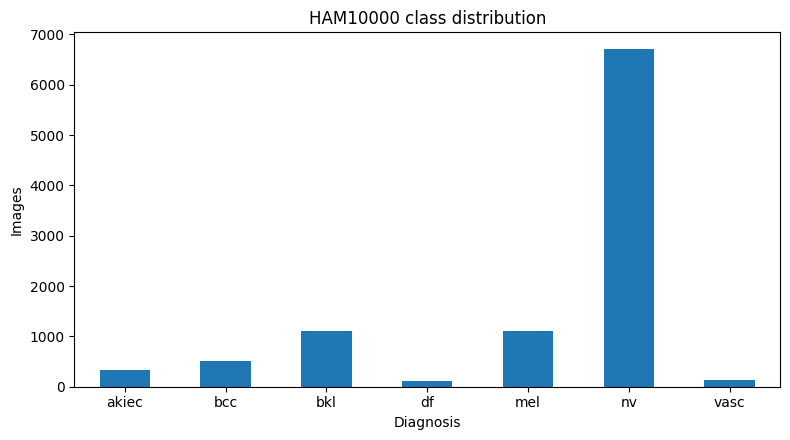

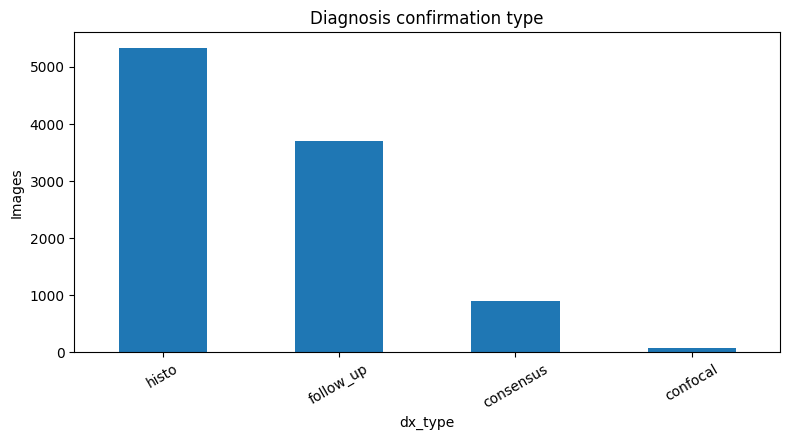

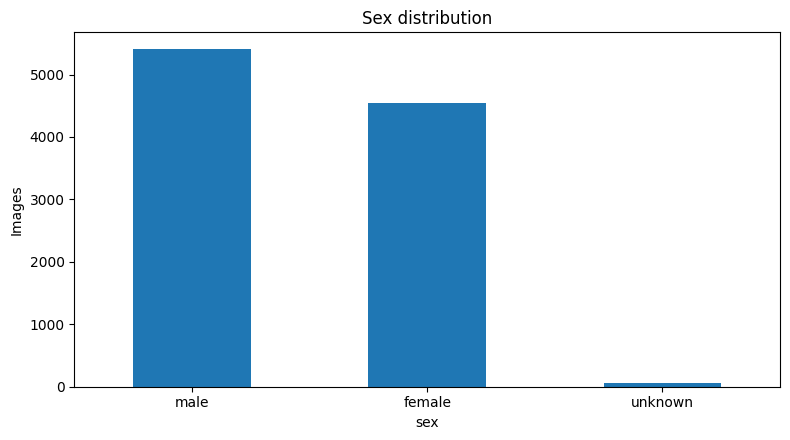

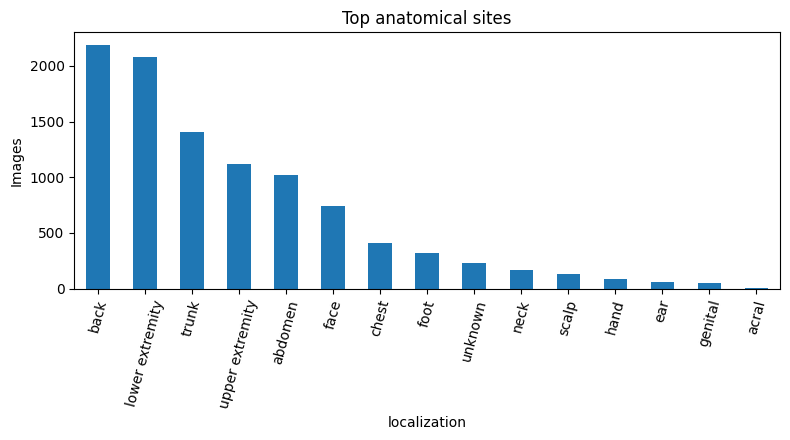

In [12]:
# --- EDA figures ---

def save_bar(series, title, xlabel, ylabel, out_path, rotation=0):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    series.plot(kind="bar", ax=ax)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis='x', rotation=rotation)
    fig.tight_layout()
    fig.savefig(out_path, dpi=200)
    plt.show()

save_bar(class_counts, "HAM10000 class distribution", "Diagnosis", "Images", FIG_DIR / "class_distribution.png")
save_bar(meta["dx_type"].fillna("missing").value_counts(), "Diagnosis confirmation type", "dx_type", "Images", FIG_DIR / "dx_type_distribution.png", rotation=30)
save_bar(meta["sex"].fillna("missing").value_counts(), "Sex distribution", "sex", "Images", FIG_DIR / "sex_distribution.png")
save_bar(meta["localization"].fillna("missing").value_counts().head(20), "Top anatomical sites", "localization", "Images", FIG_DIR / "localization_distribution.png", rotation=75)

## 4. Lesion-level grouped train/validation/test split

Final results must use grouped splitting by `lesion_id`. The validation set is reserved for early stopping, model selection, and temperature scaling. The test set is held back until final evaluation.

In [13]:
# --- Grouped stratified split with fallback ---

def stratified_group_split(df, label_col="label", group_col="lesion_id", test_size=0.2, seed=42):
    """Return train_idx, test_idx. Prefer StratifiedGroupKFold; fallback to GroupShuffleSplit."""
    y = df[label_col].values
    groups = df[group_col].values
    idx = np.arange(len(df))

    if HAS_SGK:
        # n_splits approximates requested test fraction.
        n_splits = max(2, int(round(1 / test_size)))
        sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        # Choose the fold whose test size is closest to requested.
        best = None
        for tr, te in sgkf.split(idx, y, groups):
            frac = len(te) / len(idx)
            score = abs(frac - test_size)
            if best is None or score < best[0]:
                best = (score, tr, te)
        return best[1], best[2]
    else:
        gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
        tr, te = next(gss.split(idx, y, groups))
        return tr, te

# First split: train+val vs test.
trainval_idx, test_idx = stratified_group_split(
    meta, label_col="label", group_col="lesion_id", test_size=CONFIG["test_size"], seed=CONFIG["seed"]
)
trainval_df = meta.iloc[trainval_idx].copy().reset_index(drop=True)
test_df = meta.iloc[test_idx].copy().reset_index(drop=True)

# Second split: train vs validation inside trainval.
train_idx2, val_idx2 = stratified_group_split(
    trainval_df, label_col="label", group_col="lesion_id", test_size=CONFIG["val_size_of_trainval"], seed=CONFIG["seed"] + 1
)
train_df = trainval_df.iloc[train_idx2].copy().reset_index(drop=True)
val_df = trainval_df.iloc[val_idx2].copy().reset_index(drop=True)

# Verify no lesion leakage.
def assert_no_group_overlap(a, b, group_col="lesion_id", name_a="A", name_b="B"):
    overlap = set(a[group_col]).intersection(set(b[group_col]))
    if overlap:
        raise AssertionError(f"Leakage: {len(overlap)} lesion_ids overlap between {name_a} and {name_b}")
    print(f"No {group_col} overlap between {name_a} and {name_b}.")

assert_no_group_overlap(train_df, val_df, name_a="train", name_b="val")
assert_no_group_overlap(train_df, test_df, name_a="train", name_b="test")
assert_no_group_overlap(val_df, test_df, name_a="val", name_b="test")

for split_name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    df["split"] = split_name
    df.to_csv(SPLIT_DIR / f"{split_name}.csv", index=False)
    print(split_name, df.shape, "lesions", df["lesion_id"].nunique())
    display(df["dx"].value_counts().reindex(CLASS_NAMES).to_frame("n"))

split_all = pd.concat([train_df, val_df, test_df], axis=0).reset_index(drop=True)
split_all.to_csv(SPLIT_DIR / "ham10000_lesion_level_split_all.csv", index=False)
print("Saved split files to", SPLIT_DIR)

# Reviewer/editor export: full lesion-level split protocol and class distributions.
split_method = "StratifiedGroupKFold" if HAS_SGK else "GroupShuffleSplit fallback"
split_protocol = {
    "split_by": CONFIG["split_by"],
    "group_col": "lesion_id",
    "label_col": "dx",
    "label_index_col": "label",
    "class_order": CLASS_NAMES,
    "stratification_method": split_method,
    "stratified_group_kfold_available": bool(HAS_SGK),
    "test_size_requested": CONFIG["test_size"],
    "validation_size_within_trainval_requested": CONFIG["val_size_of_trainval"],
    "effective_train_fraction": len(train_df) / len(meta),
    "effective_validation_fraction": len(val_df) / len(meta),
    "effective_test_fraction": len(test_df) / len(meta),
    "first_split_seed": CONFIG["seed"],
    "second_split_seed": CONFIG["seed"] + 1,
    "n_images_total": int(len(meta)),
    "n_lesions_total": int(meta["lesion_id"].nunique()),
    "n_images_train": int(len(train_df)),
    "n_images_validation": int(len(val_df)),
    "n_images_test": int(len(test_df)),
    "n_lesions_train": int(train_df["lesion_id"].nunique()),
    "n_lesions_validation": int(val_df["lesion_id"].nunique()),
    "n_lesions_test": int(test_df["lesion_id"].nunique()),
    "leakage_checks": "no lesion_id overlap across train, validation, and test; image_id overlap is also exported; assertions above fail the notebook if lesion leakage is detected",
}

split_class_rows = []
for split_name, df_split in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    counts = df_split["dx"].value_counts().reindex(CLASS_NAMES).fillna(0).astype(int)
    for cls in CLASS_NAMES:
        split_class_rows.append({
            "split": split_name,
            "class": cls,
            "n_images": int(counts.loc[cls]),
            "proportion_within_split": float(counts.loc[cls] / max(len(df_split), 1)),
            "n_lesions": int(df_split.loc[df_split["dx"] == cls, "lesion_id"].nunique()),
        })
split_class_distribution = pd.DataFrame(split_class_rows)
split_class_distribution.to_csv(RESULT_DIR / "reviewer_split_class_distribution.csv", index=False)

split_overlaps = []
for a_name, a_df, b_name, b_df in [
    ("train", train_df, "validation", val_df),
    ("train", train_df, "test", test_df),
    ("validation", val_df, "test", test_df),
]:
    lesion_overlap = sorted(set(a_df["lesion_id"].astype(str)) & set(b_df["lesion_id"].astype(str)))
    image_overlap = sorted(set(a_df["image_id"].astype(str)) & set(b_df["image_id"].astype(str)))
    split_overlaps.append({
        "split_a": a_name,
        "split_b": b_name,
        "lesion_id_overlap_n": int(len(lesion_overlap)),
        "image_id_overlap_n": int(len(image_overlap)),
        "lesion_overlap_examples": ";".join(lesion_overlap[:10]),
        "image_overlap_examples": ";".join(image_overlap[:10]),
    })
pd.DataFrame(split_overlaps).to_csv(RESULT_DIR / "reviewer_split_internal_overlap_checks.csv", index=False)
# Backward-compatible filename requested by earlier draft.
pd.DataFrame(split_overlaps).to_csv(RESULT_DIR / "reviewer_split_lesion_overlap_checks.csv", index=False)

with open(RESULT_DIR / "reviewer_split_protocol_summary.json", "w") as f:
    json.dump(split_protocol, f, indent=2)

print("Reviewer split protocol saved:", RESULT_DIR / "reviewer_split_protocol_summary.json")
display(split_class_distribution)


No lesion_id overlap between train and val.
No lesion_id overlap between train and test.
No lesion_id overlap between val and test.
train (6413, 12) lesions 4780


,n
dx,
akiec,203
bcc,329
bkl,681
df,69
mel,695
nv,4342
vasc,94


val (1605, 12) lesions 1196


,n
dx,
akiec,56
bcc,100
bkl,192
df,18
mel,199
nv,1027
vasc,13


test (1997, 12) lesions 1494


,n
dx,
akiec,68
bcc,85
bkl,226
df,28
mel,219
nv,1336
vasc,35


Saved split files to /content/drive/MyDrive/ham10000_trustworthy_ai/splits
Reviewer split protocol saved: /content/drive/MyDrive/ham10000_trustworthy_ai/results/reviewer_split_protocol_summary.json


,split,class,n_images,proportion_within_split,n_lesions
0,train,akiec,203,0.031654,147
1,train,bcc,329,0.051302,212
2,train,bkl,681,0.106191,460
3,train,df,69,0.010759,42
4,train,mel,695,0.108374,383
5,train,nv,4342,0.677062,3474
6,train,vasc,94,0.014658,62
7,validation,akiec,56,0.034891,37
8,validation,bcc,100,0.062305,60
9,validation,bkl,192,0.119626,117


split,test,train,val
dx,,,
akiec,68,203,56
bcc,85,329,100
bkl,226,681,192
df,28,69,18
mel,219,695,199
nv,1336,4342,1027
vasc,35,94,13


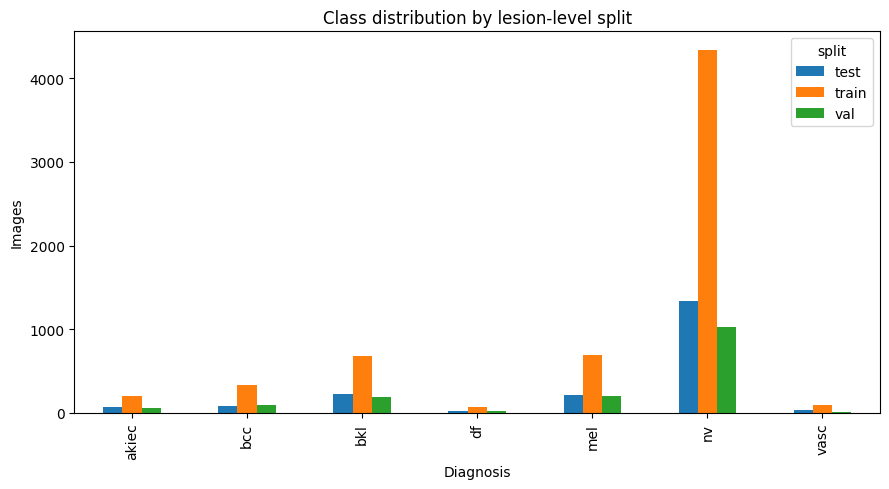

In [14]:
# --- Split distribution figure ---

split_counts = split_all.pivot_table(index="dx", columns="split", values="image_id", aggfunc="count").reindex(CLASS_NAMES).fillna(0)
display(split_counts)
split_counts.to_csv(RESULT_DIR / "split_class_distribution.csv")

fig, ax = plt.subplots(figsize=(9, 5))
split_counts.plot(kind="bar", ax=ax)
ax.set_title("Class distribution by lesion-level split")
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Images")
fig.tight_layout()
fig.savefig(FIG_DIR / "split_class_distribution.png", dpi=200)
plt.show()

## 5. Train-only metadata preprocessing

Metadata preprocessing is fitted on the training split only to avoid leakage. For the multimodal model, age is median-imputed and standardized; sex, anatomical site, and diagnosis-confirmation type are one-hot encoded with unknown categories handled safely.

In [15]:
# --- Train-only metadata preprocessing ---
# Predictive metadata should include only variables plausibly available before diagnosis.
#
# IMPORTANT METHODOLOGICAL GUARD:
#   dx_type is the diagnostic-confirmation mechanism (e.g., histology, follow-up,
#   consensus, confocal). It is valid for subgroup/error analysis but is not a
#   deployable pre-diagnostic predictor. Including it as a model input would risk
#   post-outcome/label-confirmation leakage.
#
# Therefore:
#   - Model-input metadata: age, sex, localization
#   - Subgroup-only metadata: sex, age_bin, localization, dx_type

META_CATEGORICAL_COLS = ["sex", "localization"]
META_NUMERIC_COLS = ["age"]
SUBGROUP_VARIABLES = ["sex", "age_bin", "localization", "dx_type"]

assert "dx_type" not in META_CATEGORICAL_COLS + META_NUMERIC_COLS, (
    "dx_type must never be used as a predictive metadata input. "
    "It is reserved for subgroup analysis only."
)

class MetadataPreprocessor:
    def __init__(self, categorical_cols, numeric_cols):
        self.categorical_cols = list(categorical_cols)
        self.numeric_cols = list(numeric_cols)
        self.encoder = None
        self.scaler = None
        self.age_median = None
        self.feature_names_ = None

    def fit(self, df):
        cat = df[self.categorical_cols].fillna("missing").astype(str).replace({"nan": "missing"})
        # Compatibility with sklearn versions.
        try:
            self.encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
        except TypeError:
            self.encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)
        self.encoder.fit(cat)

        num = df[self.numeric_cols].copy()
        self.age_median = float(num["age"].median())
        num["age"] = num["age"].fillna(self.age_median).astype(float)
        self.scaler = StandardScaler().fit(num.values)

        cat_names = list(self.encoder.get_feature_names_out(self.categorical_cols))
        self.feature_names_ = self.numeric_cols + cat_names
        return self

    def transform(self, df):
        cat = df[self.categorical_cols].fillna("missing").astype(str).replace({"nan": "missing"})
        cat_arr = self.encoder.transform(cat)
        num = df[self.numeric_cols].copy()
        num["age"] = num["age"].fillna(self.age_median).astype(float)
        num_arr = self.scaler.transform(num.values)
        return np.concatenate([num_arr, cat_arr], axis=1).astype("float32")

meta_pre = MetadataPreprocessor(META_CATEGORICAL_COLS, META_NUMERIC_COLS).fit(train_df)
X_meta_train = meta_pre.transform(train_df)
X_meta_val = meta_pre.transform(val_df)
X_meta_test = meta_pre.transform(test_df)
META_DIM = X_meta_train.shape[1]

joblib.dump(meta_pre, MODEL_DIR / "metadata_preprocessor_clean_inputs.joblib")

metadata_manifest = {
    "predictive_categorical_cols": META_CATEGORICAL_COLS,
    "predictive_numeric_cols": META_NUMERIC_COLS,
    "excluded_from_predictive_inputs": ["dx_type"],
    "subgroup_variables": SUBGROUP_VARIABLES,
    "reason_dx_type_excluded": (
        "dx_type encodes diagnostic-confirmation pathway and may be partly downstream "
        "of the diagnostic process; it is retained only for subgroup analysis."
    ),
    "metadata_feature_dimension": int(META_DIM),
    "metadata_feature_names": list(meta_pre.feature_names_),
}
(MODEL_DIR / "metadata_input_manifest.json").write_text(json.dumps(metadata_manifest, indent=2))

print("Metadata feature dimension:", META_DIM)
print("Predictive categorical metadata:", META_CATEGORICAL_COLS)
print("Predictive numeric metadata:", META_NUMERIC_COLS)
print("Subgroup-only variables:", SUBGROUP_VARIABLES)
print("First 10 metadata features:", meta_pre.feature_names_[:10])
print("Confirmed: dx_type is excluded from model inputs and retained only for subgroup analysis.")


Metadata feature dimension: 18
Predictive categorical metadata: ['sex', 'localization']
Predictive numeric metadata: ['age']
Subgroup-only variables: ['sex', 'age_bin', 'localization', 'dx_type']
First 10 metadata features: ['age', 'sex_female', 'sex_male', 'sex_unknown', 'localization_abdomen', 'localization_back', 'localization_chest', 'localization_ear', 'localization_face', 'localization_foot']
Confirmed: dx_type is excluded from model inputs and retained only for subgroup analysis.


## 6. TensorFlow datasets

The model receives two inputs: an image tensor and a metadata vector. For image-only models, the metadata input is present but ignored, which keeps all downstream code consistent.

In [16]:
# --- Data pipeline: CPU-only Python/PIL sequence for images ---
# This cell intentionally does NOT use tf.data.
# Reason: earlier failures occurred during TensorFlow device-side dataset/tensor construction.
# This CPU-only version loads image batches with Python/PIL and passes NumPy arrays to Keras.
# Same downstream outputs are preserved:
#   train_ds, val_ds, test_ds = datasets_for(...)

from pathlib import Path
import numpy as np
from PIL import Image, ImageEnhance, ImageOps
import tensorflow as tf
from tensorflow import keras

IMG_SIZE = int(CONFIG["image_size"])
BATCH_SIZE = int(CONFIG["batch_size"])
N_CLASSES = len(CLASS_NAMES)


def compute_inverse_frequency_weights(df, label_col="label", n_classes=None):
    """Inverse-frequency class weights: total / (K * n_k)."""
    if n_classes is None:
        n_classes = N_CLASSES
    counts = (
        df[label_col].value_counts()
        .reindex(range(n_classes))
        .fillna(0)
        .astype(float)
        .values
    )
    total = counts.sum()
    weights = total / (n_classes * np.maximum(counts, 1.0))
    return weights.astype("float32")


def compute_effective_number_weights(df, beta=0.9999, label_col="label", n_classes=None):
    """Effective-number class-balanced weights, normalized to mean 1."""
    if n_classes is None:
        n_classes = N_CLASSES
    counts = (
        df[label_col].value_counts()
        .reindex(range(n_classes))
        .fillna(0)
        .astype(float)
        .values
    )
    counts = np.maximum(counts, 1.0)
    effective_num = 1.0 - np.power(beta, counts)
    weights = (1.0 - beta) / np.maximum(effective_num, 1e-12)
    weights = weights / np.mean(weights)
    return weights.astype("float32")


class_weights_arr = compute_inverse_frequency_weights(train_df)
class_balanced_weights_arr = compute_effective_number_weights(
    train_df,
    beta=float(CONFIG["class_balanced_beta"]),
)
class_weight_dict = {i: float(class_weights_arr[i]) for i in range(N_CLASSES)}

print(
    "Inverse-frequency class weights:",
    {CLASS_NAMES[i]: round(float(class_weights_arr[i]), 3) for i in range(N_CLASSES)},
)
print(
    "Effective-number class-balanced weights:",
    {CLASS_NAMES[i]: round(float(class_balanced_weights_arr[i]), 3) for i in range(N_CLASSES)},
)


def _pil_resize_rgb(path, image_size=IMG_SIZE):
    """Load one image as RGB float32 array in 0-255 scale."""
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
        im = im.resize((image_size, image_size), resample=Image.BILINEAR)
        arr = np.asarray(im, dtype="float32")
    return arr


def _augment_numpy_dermoscopy(arr, rng):
    """Conservative lesion-preserving augmentation in NumPy/PIL.

    This avoids tf.image entirely at the dataset stage, removing the earlier TensorFlow-device failure path while retaining defendable dermoscopy augmentation.
    """
    im = Image.fromarray(np.clip(arr, 0, 255).astype("uint8"), mode="RGB")

    if rng.random() < 0.5:
        im = ImageOps.mirror(im)
    if rng.random() < 0.5:
        im = ImageOps.flip(im)

    # Mild brightness and contrast perturbations.
    brightness = rng.uniform(0.90, 1.10)
    contrast = rng.uniform(0.90, 1.10)
    im = ImageEnhance.Brightness(im).enhance(brightness)
    im = ImageEnhance.Contrast(im).enhance(contrast)

    # Mild central zoom/crop.
    crop_fraction = rng.uniform(0.90, 1.00)
    w, h = im.size
    cw, ch = int(w * crop_fraction), int(h * crop_fraction)
    left = (w - cw) // 2
    top = (h - ch) // 2
    im = im.crop((left, top, left + cw, top + ch)).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)

    return np.asarray(im, dtype="float32")


def load_image_numpy(path, training=False, seed=None):
    """Public helper used by Sequence, stress tests and Grad-CAM."""
    path = str(path)
    arr = _pil_resize_rgb(path, IMG_SIZE)
    if training:
        rng = np.random.default_rng(seed)
        arr = _augment_numpy_dermoscopy(arr, rng)
    return arr.astype("float32")


class HAM10000Sequence(keras.utils.Sequence):
    """Keras-compatible image loader that avoids tf.data completely.

    Keras receives NumPy batches and performs forward/backward passes on CPU in this notebook.
    The returned input signature matches the model:
      image-only: {"image": images}
      multimodal: {"image": images, "metadata": meta}
    """
    def __init__(
        self,
        df,
        X_meta,
        batch_size=16,
        training=False,
        shuffle=False,
        use_metadata=False,
        include_sample_weight=False,
        sample_weight_mode="inverse_frequency",
        seed=42,
    ):
        try:
            super().__init__()
        except TypeError:
            super().__init__(**{})
        self.df = df.reset_index(drop=True).copy()
        self.paths = self.df["image_path"].astype(str).to_numpy()
        self.labels = self.df["label"].astype("int32").to_numpy()
        self.X_meta = np.asarray(X_meta, dtype="float32")
        self.batch_size = int(batch_size)
        self.training = bool(training)
        self.shuffle = bool(shuffle)
        self.use_metadata = bool(use_metadata)
        self.include_sample_weight = bool(include_sample_weight)
        self.sample_weight_mode = sample_weight_mode
        self.seed = int(seed)
        self.epoch = 0
        self.indexes = np.arange(len(self.paths))

        if len(self.paths) != len(self.labels) or len(self.paths) != len(self.X_meta):
            raise ValueError(
                f"Length mismatch: paths={len(self.paths)}, labels={len(self.labels)}, metadata={len(self.X_meta)}"
            )

        missing = [p for p in self.paths[: min(len(self.paths), 3000)] if not Path(p).exists()]
        if missing:
            raise FileNotFoundError("Missing image files, examples:\n" + "\n".join(missing[:5]))

        if self.include_sample_weight:
            if self.sample_weight_mode == "inverse_frequency":
                self.sample_weights = class_weights_arr[self.labels].astype("float32")
            elif self.sample_weight_mode == "class_balanced":
                self.sample_weights = class_balanced_weights_arr[self.labels].astype("float32")
            else:
                raise ValueError(f"Unknown sample_weight_mode: {self.sample_weight_mode}")
        else:
            self.sample_weights = None

        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.paths) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            rng = np.random.default_rng(self.seed + self.epoch)
            rng.shuffle(self.indexes)
        self.epoch += 1

    def __getitem__(self, batch_idx):
        start = batch_idx * self.batch_size
        end = min((batch_idx + 1) * self.batch_size, len(self.paths))
        batch_indexes = self.indexes[start:end]

        images = np.empty((len(batch_indexes), IMG_SIZE, IMG_SIZE, 3), dtype="float32")
        for j, idx in enumerate(batch_indexes):
            # deterministic per-image/per-epoch augmentation seed
            aug_seed = self.seed + self.epoch * 1_000_003 + int(idx)
            images[j] = load_image_numpy(self.paths[idx], training=self.training, seed=aug_seed)

        y = self.labels[batch_indexes].astype("int32")
        if self.use_metadata:
            x = {
                "image": images,
                "metadata": self.X_meta[batch_indexes].astype("float32"),
            }
        else:
            x = {"image": images}

        if self.include_sample_weight:
            sw = self.sample_weights[batch_indexes].astype("float32")
            return x, y, sw
        return x, y

    def __iter__(self):
        for i in range(len(self)):
            yield self[i]


def make_tf_dataset(
    df,
    X_meta,
    training=False,
    include_sample_weight=False,
    shuffle=True,
    use_metadata=False,
):
    """Compatibility wrapper: name kept, but backend is Keras Sequence rather than tf.data."""
    return HAM10000Sequence(
        df=df,
        X_meta=X_meta,
        batch_size=BATCH_SIZE,
        training=training,
        shuffle=(training and shuffle),
        use_metadata=use_metadata,
        include_sample_weight=include_sample_weight,
        seed=int(CONFIG["seed"]),
    )


def datasets_for(use_metadata=False, loss_type=None):
    """Return train/validation/test datasets compatible with a given model and loss."""
    if loss_type is None:
        loss_type = CONFIG["loss_type"]

    include_train_weights = loss_type == "weighted_ce"

    train_dataset = make_tf_dataset(
        train_df,
        X_meta_train,
        training=True,
        include_sample_weight=include_train_weights,
        shuffle=True,
        use_metadata=use_metadata,
    )
    val_dataset = make_tf_dataset(
        val_df,
        X_meta_val,
        training=False,
        include_sample_weight=False,
        shuffle=False,
        use_metadata=use_metadata,
    )
    test_dataset = make_tf_dataset(
        test_df,
        X_meta_test,
        training=False,
        include_sample_weight=False,
        shuffle=False,
        use_metadata=use_metadata,
    )
    return train_dataset, val_dataset, test_dataset


# Construct default datasets.
train_ds, val_ds, test_ds = datasets_for(
    use_metadata=bool(CONFIG["use_metadata"]),
    loss_type=CONFIG["loss_type"],
)

print("CPU-only Keras Sequence datasets constructed; tf.data is not used.")
print("use_metadata:", CONFIG["use_metadata"])
print("loss_type:", CONFIG["loss_type"])
print("batch_size:", BATCH_SIZE)
print("image_size:", IMG_SIZE)
print("backend:", CONFIG.get("data_pipeline_backend", "keras_sequence_cpu"))
print("compute mode: CPU-only")
print("GPUs visible to TensorFlow:", tf.config.list_logical_devices("GPU"))

if bool(CONFIG.get("preview_tfdata_batch", False)):
    preview_batch = train_ds[0]
    print("Batch preview successful.")
    if len(preview_batch) == 3:
        x_preview, y_preview, sw_preview = preview_batch
        print("Batch includes sample weights:", sw_preview.shape)
    else:
        x_preview, y_preview = preview_batch
        print("Batch does not include sample weights.")
    print("Input keys:", list(x_preview.keys()))
    print("Image batch shape:", x_preview["image"].shape)
    if "metadata" in x_preview:
        print("Metadata batch shape:", x_preview["metadata"].shape)
    print("Label batch shape:", y_preview.shape)
else:
    print("Batch preview skipped. The first batch will be loaded at fit/evaluation time.")


Inverse-frequency class weights: {'akiec': 4.513, 'bcc': 2.785, 'bkl': 1.345, 'df': 13.277, 'mel': 1.318, 'nv': 0.211, 'vasc': 9.746}
Effective-number class-balanced weights: {'akiec': 0.952, 'bcc': 0.591, 'bkl': 0.291, 'df': 2.782, 'mel': 0.285, 'nv': 0.054, 'vasc': 2.045}
CPU-only Keras Sequence datasets constructed; tf.data is not used.
use_metadata: False
loss_type: weighted_ce
batch_size: 8
image_size: 224
backend: keras_sequence_cpu
compute mode: CPU-only
GPUs visible to TensorFlow: []
Batch preview skipped. The first batch will be loaded at fit/evaluation time.


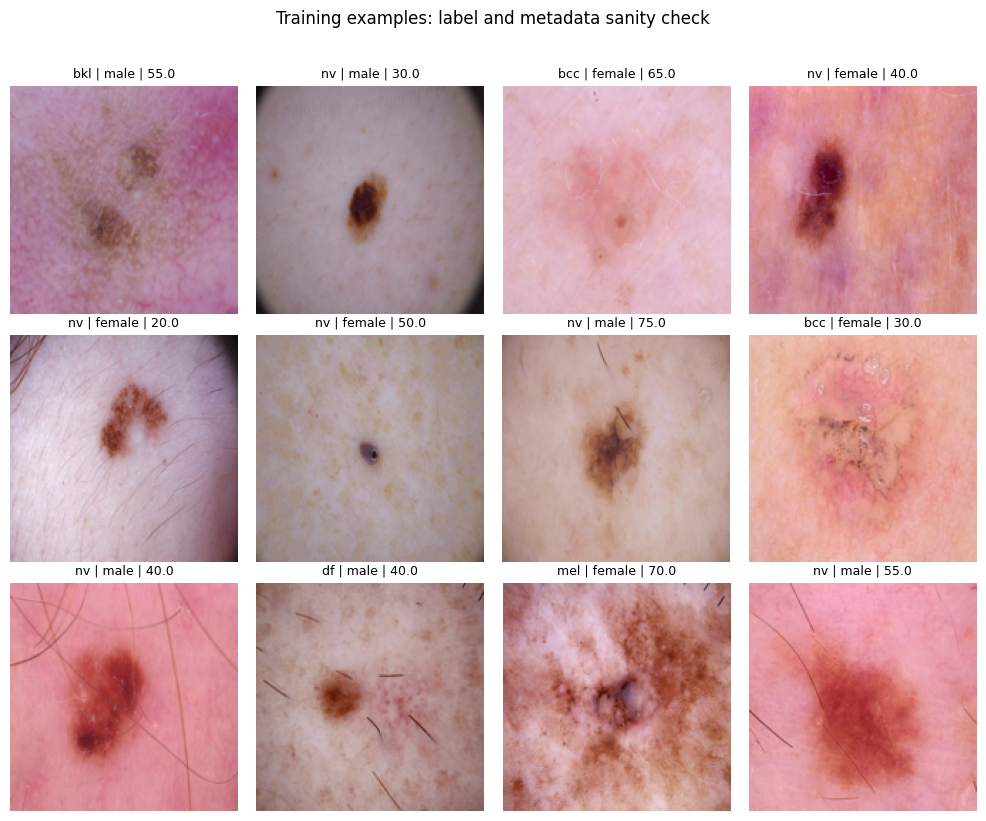

In [17]:
# --- Visual sanity check: samples from the training split ---

sample_df = train_df.sample(min(12, len(train_df)), random_state=CONFIG["seed"])
fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for ax, (_, row) in zip(axes.flat, sample_df.iterrows()):
    img = Image.open(row["image_path"]).convert("RGB").resize((160, 160))
    ax.imshow(img)
    ax.set_title(f"{row['dx']} | {row['sex']} | {row['age']}", fontsize=9)
    ax.axis("off")
fig.suptitle("Training examples: label and metadata sanity check", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "training_examples_grid.png", dpi=200)
plt.show()

## 7. Model builders: image-only and late-fusion multimodal networks

The recommended first publishable route is: EfficientNetB0 image-only baseline → temperature scaling and selective referral → metadata late-fusion ablation → optional MC Dropout/ensemble for the best model.

In [18]:
# --- Losses and model builders: CPU-only publishable version ---
# This cell defines losses and model constructors only.
# Model construction is CPU-only by design, avoiding all CUDA/CuDNN paths.

import contextlib


def _maybe_cpu_scope(enabled=True):
    """Context manager for CPU-only graph/model construction when requested."""
    if enabled:
        return tf.device("/CPU:0")
    return contextlib.nullcontext()


def class_weighted_sparse_ce(class_weights):
    # Keep the constant on CPU at creation time; it will be copied as needed during fit.
    with tf.device("/CPU:0"):
        weights_tf = tf.constant(np.asarray(class_weights, dtype="float32"), dtype=tf.float32)

    def loss_fn(y_true, logits):
        y_true_int = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        ce = tf.keras.losses.sparse_categorical_crossentropy(y_true_int, logits, from_logits=True)
        w = tf.gather(weights_tf, y_true_int)
        return ce * w

    return loss_fn


def sparse_categorical_focal_loss(gamma=2.0, class_weights=None):
    if class_weights is None:
        cw = None
    else:
        with tf.device("/CPU:0"):
            cw = tf.constant(np.asarray(class_weights, dtype="float32"), dtype=tf.float32)

    def loss_fn(y_true, logits):
        y_true_int = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        ce = tf.keras.losses.sparse_categorical_crossentropy(y_true_int, logits, from_logits=True)
        probs = tf.nn.softmax(logits, axis=-1)
        p_t = tf.gather(probs, y_true_int[:, None], batch_dims=1)
        p_t = tf.squeeze(p_t, axis=1)
        focal = tf.pow(1.0 - p_t, gamma) * ce
        if cw is not None:
            focal *= tf.gather(cw, y_true_int)
        return focal

    return loss_fn


@keras.utils.register_keras_serializable(package="TrustworthySkinAI")
class ResNet50Preprocess(layers.Layer):
    def call(self, inputs):
        return tf.keras.applications.resnet50.preprocess_input(inputs)


@keras.utils.register_keras_serializable(package="TrustworthySkinAI")
class MobileNetV2Preprocess(layers.Layer):
    def call(self, inputs):
        return tf.keras.applications.mobilenet_v2.preprocess_input(inputs)


@keras.utils.register_keras_serializable(package="TrustworthySkinAI")
class DenseNetPreprocess(layers.Layer):
    def call(self, inputs):
        return tf.keras.applications.densenet.preprocess_input(inputs)


@keras.utils.register_keras_serializable(package="TrustworthySkinAI")
class EfficientNetIdentityPreprocess(layers.Layer):
    def call(self, inputs):
        # Keras EfficientNet preprocessing is already included in the application model.
        # Keeping this explicit identity layer documents the intended 0-255 input scale.
        return tf.cast(inputs, tf.float32)


def get_backbone(name, input_tensor):
    """Return an ImageNet-pretrained backbone with a stable preprocessing path.

    Input images are float32 in 0-255 RGB scale. EfficientNet models in Keras include
    their own rescaling/normalization preprocessing; ResNet/MobileNet/DenseNet use
    their standard preprocessing layers.
    """
    name_l = name.lower()

    if name_l == "efficientnetb0":
        x = EfficientNetIdentityPreprocess(name="efficientnet_input_scale_documented")(input_tensor)
        backbone = tf.keras.applications.EfficientNetB0(
            include_top=False, weights="imagenet", input_tensor=x, pooling="avg"
        )
    elif name_l == "resnet50":
        x = ResNet50Preprocess(name="resnet_preprocess")(input_tensor)
        backbone = tf.keras.applications.ResNet50(
            include_top=False, weights="imagenet", input_tensor=x, pooling="avg"
        )
    elif name_l == "mobilenetv2":
        x = MobileNetV2Preprocess(name="mobilenet_preprocess")(input_tensor)
        backbone = tf.keras.applications.MobileNetV2(
            include_top=False, weights="imagenet", input_tensor=x, pooling="avg"
        )
    elif name_l == "densenet121":
        x = DenseNetPreprocess(name="densenet_preprocess")(input_tensor)
        backbone = tf.keras.applications.DenseNet121(
            include_top=False, weights="imagenet", input_tensor=x, pooling="avg"
        )
    else:
        raise ValueError(f"Unsupported backbone: {name}")

    return backbone


def build_model(backbone_name="EfficientNetB0", use_metadata=False, meta_dim=None, dropout_rate=0.3, train_backbone=False):
    """Build the image-only or late-fusion multimodal classifier.

    Graph construction happens under a CPU device scope. This notebook is CPU-only.
    """
    if meta_dim is None:
        meta_dim = META_DIM

    build_on_cpu = bool(CONFIG.get("build_model_on_cpu", True))

    with _maybe_cpu_scope(build_on_cpu):
        image_in = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
        backbone = get_backbone(backbone_name, image_in)
        backbone.trainable = bool(train_backbone)

        img_emb = backbone.output
        img_emb = layers.Dropout(dropout_rate, name="image_dropout")(img_emb)

        if use_metadata:
            meta_in = keras.Input(shape=(meta_dim,), name="metadata")
            m = layers.Dense(64, activation="relu", name="metadata_dense_1")(meta_in)
            m = layers.BatchNormalization(name="metadata_bn_1")(m)
            m = layers.Dropout(dropout_rate, name="metadata_dropout")(m)
            m = layers.Dense(32, activation="relu", name="metadata_dense_2")(m)
            x = layers.Concatenate(name="late_fusion_concat")([img_emb, m])
            inputs = {"image": image_in, "metadata": meta_in}
        else:
            x = img_emb
            inputs = {"image": image_in}

        x = layers.Dense(256, activation="relu", name="classifier_dense")(x)
        x = layers.BatchNormalization(name="classifier_bn")(x)
        x = layers.Dropout(dropout_rate, name="classifier_dropout")(x)
        logits = layers.Dense(N_CLASSES, dtype="float32", name="logits")(x)

        model = keras.Model(
            inputs=inputs,
            outputs=logits,
            name=f"{backbone_name}_{'multimodal' if use_metadata else 'image_only'}",
        )

    return model


def compile_model(model, lr, loss_type="weighted_ce"):
    """Compile model using the requested long-tail strategy."""
    compile_on_cpu = bool(CONFIG.get("compile_model_on_cpu", True))

    with _maybe_cpu_scope(compile_on_cpu):
        opt = keras.optimizers.Adam(learning_rate=lr)

        if loss_type == "focal":
            loss = sparse_categorical_focal_loss(gamma=CONFIG["focal_gamma"], class_weights=class_weights_arr)
        elif loss_type == "class_balanced_ce":
            loss = class_weighted_sparse_ce(class_balanced_weights_arr)
        elif loss_type == "weighted_ce":
            # For weighted CE, sample weights are supplied by the Sequence.
            loss = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
        else:
            raise ValueError(f"Unsupported loss_type: {loss_type}")

        model.compile(
            optimizer=opt,
            loss=loss,
            metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
        )

    return model


# Optional preview. Disabled by default because the training utility will build the real model.
if bool(CONFIG.get("run_model_build_preview", False)):
    runtime_guard("before optional model build preview")
    preview_model = build_model(CONFIG["backbone"], use_metadata=CONFIG["use_metadata"], meta_dim=META_DIM)
    compile_model(preview_model, CONFIG["head_learning_rate"], CONFIG["loss_type"])
    preview_model.summary()
else:
    print("Model-builder cell loaded. Preview build skipped for speed/stability.")
    print("Backbone:", CONFIG["backbone"], "| use_metadata:", CONFIG["use_metadata"], "| N_CLASSES:", N_CLASSES)


Model-builder cell loaded. Preview build skipped for speed/stability.
Backbone: EfficientNetB0 | use_metadata: False | N_CLASSES: 7


## 8. Training protocol: frozen head training then careful fine-tuning

This is a two-stage transfer-learning protocol. First train only the classification head to stabilise the task-specific layer. Then unfreeze the last part of the backbone with a much smaller learning rate.

In [19]:
# --- Training utilities: CPU-only full-run version ---

def model_uses_metadata(model):
    names = []
    for inp in model.inputs:
        try:
            names.append(inp.name.split(":")[0].split("/")[-1])
        except Exception:
            pass
    return "metadata" in names


def unfreeze_last_n_layers(model, n_last=40):
    """Unfreeze the last n layers of the nested application backbone, keeping BatchNorm frozen.

    Important Keras detail:
    For nested application models, the parent backbone model must be set trainable=True
    before individual child layers can contribute trainable weights. This function records
    the actual trainable layers/parameters so the fine-tuning protocol is auditable.
    """
    # Freeze all top-level layers first.
    for layer in model.layers:
        layer.trainable = False

    backbone = None
    for layer in model.layers:
        if isinstance(layer, keras.Model) and layer.name.lower().startswith(("efficientnet", "resnet", "mobilenet", "densenet")):
            backbone = layer
            break

    fine_tuned_backbone_layers = []

    if backbone is not None:
        # Re-enable the nested backbone container, then selectively unfreeze child layers.
        backbone.trainable = True
        for layer in backbone.layers:
            layer.trainable = False

        for layer in backbone.layers[-int(n_last):]:
            if not isinstance(layer, layers.BatchNormalization):
                layer.trainable = True
                fine_tuned_backbone_layers.append(layer.name)
    else:
        # Fallback for a non-nested model. This path is not expected for the application backbones.
        for layer in model.layers[-int(n_last):]:
            if not isinstance(layer, layers.BatchNormalization):
                layer.trainable = True
                fine_tuned_backbone_layers.append(layer.name)

    top_trainable_layers = []
    for layer in model.layers:
        if layer.name.startswith(("classifier", "logits", "metadata", "late_fusion")) and not isinstance(layer, layers.BatchNormalization):
            layer.trainable = True
            top_trainable_layers.append(layer.name)

    trainable_parameter_count = int(np.sum([np.prod(w.shape) for w in model.trainable_weights]))
    trainable_weight_count = int(len(model.trainable_weights))

    report = {
        "requested_last_n_backbone_layers": int(n_last),
        "backbone_model_name": backbone.name if backbone is not None else "not_found_non_nested_fallback",
        "batchnorm_layers_kept_frozen": True,
        "fine_tuned_backbone_layer_names": fine_tuned_backbone_layers,
        "top_level_trainable_layer_names": top_trainable_layers,
        "trainable_weight_count_after_unfreeze": trainable_weight_count,
        "trainable_parameter_count_after_unfreeze": trainable_parameter_count,
    }
    model._fine_tune_report = report

    print("Unfroze backbone layers:", len(fine_tuned_backbone_layers))
    print("Trainable weights after unfreeze:", trainable_weight_count)
    print("Trainable parameters after unfreeze:", trainable_parameter_count)
    return model


def safe_load_model(path):
    """Load a Keras model without requiring custom loss serialization."""
    custom_objects = {
        "ResNet50Preprocess": ResNet50Preprocess,
        "MobileNetV2Preprocess": MobileNetV2Preprocess,
        "DenseNetPreprocess": DenseNetPreprocess,
        "EfficientNetIdentityPreprocess": EfficientNetIdentityPreprocess,
    }
    with tf.device("/CPU:0"):
        return tf.keras.models.load_model(path, compile=False, custom_objects=custom_objects)


def _fit_with_runtime_guard(model, train_data, val_data, epochs, callbacks, stage_name):
    """Fit on CPU with a clear failure message.

    CUDA is disabled at setup, so this function avoids all GPU-specific guards.
    """
    runtime_guard(f"before {stage_name}")
    try:
        with tf.device("/CPU:0"):
            return model.fit(
                train_data,
                validation_data=val_data,
                epochs=int(epochs),
                callbacks=callbacks,
                verbose=1,
            )
    except Exception as e:
        raise RuntimeError(
            f"TensorFlow/Keras failed during {stage_name}. This CPU-only notebook avoids CUDA; "
            "check the preceding traceback for data-path, memory, or model-construction errors."
        ) from e


def train_one_model(backbone_name, use_metadata, seed, loss_type="weighted_ce", run_tag=None):
    set_all_seeds(seed, deterministic=False)
    tf.keras.backend.clear_session()
    gc.collect()

    if run_tag is None:
        run_tag = f"{backbone_name}_{'meta' if use_metadata else 'image'}_seed{seed}_{loss_type}"
    out_dir = MODEL_DIR / run_tag
    out_dir.mkdir(parents=True, exist_ok=True)
    final_path = out_dir / "final_model.keras"

    if final_path.exists() and not CONFIG["force_retrain"]:
        print(f"Existing trained model found; reusing: {final_path}")
        model = safe_load_model(final_path)
        runtime_path = out_dir / "runtime.json"
        runtime = json.load(open(runtime_path)) if runtime_path.exists() else {
            "run_tag": run_tag,
            "backbone": backbone_name,
            "use_metadata": use_metadata,
            "seed": seed,
            "loss_type": loss_type,
            "reused_existing": True,
            "timestamp": datetime.now().isoformat(),
        }
        return model, out_dir, runtime

    train_ds_local, val_ds_local, _ = datasets_for(use_metadata=use_metadata, loss_type=loss_type)

    print(f"Building model safely | {run_tag}")
    model = build_model(
        backbone_name,
        use_metadata=use_metadata,
        meta_dim=META_DIM,
        dropout_rate=CONFIG["dropout_rate"],
        train_backbone=False,
    )
    compile_model(model, CONFIG["head_learning_rate"], loss_type)

    # Save a text summary for reproducibility without forcing interactive rendering.
    summary_lines = []
    model.summary(print_fn=lambda x: summary_lines.append(x))
    (out_dir / "model_summary.txt").write_text("\n".join(summary_lines))

    callbacks_head = [
        keras.callbacks.ModelCheckpoint(out_dir / "best_head.weights.h5", monitor="val_loss", save_best_only=True, save_weights_only=True),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=CONFIG["early_stopping_patience"], restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6),
        keras.callbacks.CSVLogger(out_dir / "history_head.csv"),
    ]

    print(f"Stage 1: frozen backbone head training | {run_tag}")
    t0 = time.time()
    hist1 = _fit_with_runtime_guard(
        model,
        train_ds_local,
        val_ds_local,
        epochs=CONFIG["head_epochs"],
        callbacks=callbacks_head,
        stage_name=f"head training: {run_tag}",
    )
    head_seconds = time.time() - t0

    best_head_path = out_dir / "best_head.weights.h5"
    if best_head_path.exists():
        model.load_weights(best_head_path)
        print("Loaded best head-stage validation-loss weights:", best_head_path)

    print(f"Stage 2: fine-tuning | {run_tag}")
    model = unfreeze_last_n_layers(model, CONFIG["finetune_last_n_layers"])
    fine_tune_report = getattr(model, "_fine_tune_report", {})
    with open(out_dir / "fine_tuned_layers_after_unfreeze.json", "w") as f:
        json.dump(fine_tune_report, f, indent=2)
    compile_model(model, CONFIG["finetune_learning_rate"], loss_type)

    callbacks_ft = [
        keras.callbacks.ModelCheckpoint(out_dir / "best_finetuned.weights.h5", monitor="val_loss", save_best_only=True, save_weights_only=True),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=CONFIG["early_stopping_patience"], restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7),
        keras.callbacks.CSVLogger(out_dir / "history_finetune.csv"),
    ]

    t1 = time.time()
    hist2 = _fit_with_runtime_guard(
        model,
        train_ds_local,
        val_ds_local,
        epochs=CONFIG["finetune_epochs"],
        callbacks=callbacks_ft,
        stage_name=f"fine-tuning: {run_tag}",
    )
    ft_seconds = time.time() - t1

    best_ft_path = out_dir / "best_finetuned.weights.h5"
    if best_ft_path.exists():
        model.load_weights(best_ft_path)
        print("Loaded best fine-tuning validation-loss weights before final save:", best_ft_path)

    # Save without optimizer to avoid serializing custom losses/optimizer state.
    with tf.device("/CPU:0"):
        model.save(final_path, include_optimizer=False)

    runtime = {
        "run_tag": run_tag,
        "backbone": backbone_name,
        "use_metadata": use_metadata,
        "seed": seed,
        "loss_type": loss_type,
        "head_seconds": head_seconds,
        "finetune_seconds": ft_seconds,
        "total_seconds": head_seconds + ft_seconds,
        "batch_size": BATCH_SIZE,
        "image_size": IMG_SIZE,
        "build_model_on_cpu": bool(CONFIG.get("build_model_on_cpu", True)),
        "compile_model_on_cpu": bool(CONFIG.get("compile_model_on_cpu", True)),
        "compute_mode": "CPU-only",
        "gpu_name": None,
        "timestamp": datetime.now().isoformat(),
        "reused_existing": False,
    }
    with open(out_dir / "runtime.json", "w") as f:
        json.dump(runtime, f, indent=2)

    return model, out_dir, runtime

print("Training utility ready. Model build/compile/training are CPU-only.")


Training utility ready. Model build/compile/training are CPU-only.


In [20]:
# --- Reviewer/editor export: complete training and preprocessing details ---
# This cell writes the method details requested by the editor in a machine-readable form.

import platform
import sklearn

training_details = {
    "optimizer": "Adam",
    "head_learning_rate_initial": CONFIG["head_learning_rate"],
    "finetune_learning_rate_initial": CONFIG["finetune_learning_rate"],
    "lr_schedule_head": "ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-6)",
    "lr_schedule_finetune": "ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-7)",
    "head_epochs_max": CONFIG["head_epochs"],
    "finetune_epochs_max": CONFIG["finetune_epochs"],
    "early_stopping": f"EarlyStopping(monitor='val_loss', patience={CONFIG['early_stopping_patience']}, restore_best_weights=True)",
    "model_checkpointing": "best validation-loss weights saved separately for head and fine-tuning stages",
    "batch_size": CONFIG["batch_size"],
    "image_size": CONFIG["image_size"],
    "dropout_rate": CONFIG["dropout_rate"],
    "primary_loss_type": CONFIG["loss_type"],
    "focal_gamma": CONFIG["focal_gamma"],
    "class_balanced_beta": CONFIG["class_balanced_beta"],
    "class_order": CLASS_NAMES,
    "inverse_frequency_class_weights": {CLASS_NAMES[i]: float(class_weights_arr[i]) for i in range(N_CLASSES)},
    "effective_number_class_balanced_weights": {CLASS_NAMES[i]: float(class_balanced_weights_arr[i]) for i in range(N_CLASSES)},
    "fine_tuning": {
        "stage_1": "ImageNet backbone frozen; classifier head trained",
        "stage_2": f"last {CONFIG['finetune_last_n_layers']} backbone layers considered for unfreezing; BatchNorm layers kept frozen; classifier head trainable",
        "auditable_layer_export": "Each model directory writes fine_tuned_layers_after_unfreeze.json with actual trainable backbone/top layers and trainable-parameter count.",
    },
    "augmentation_train_only": {
        "horizontal_flip_probability": 0.5,
        "vertical_flip_probability": 0.5,
        "brightness_factor_uniform": [0.90, 1.10],
        "contrast_factor_uniform": [0.90, 1.10],
        "central_crop_fraction_uniform": [0.90, 1.00],
        "validation_test_augmentation": "none",
    },
    "image_preprocessing": {
        "read": "PIL ImageOps.exif_transpose, RGB conversion",
        "resize": f"{CONFIG['image_size']}x{CONFIG['image_size']} bilinear",
        "numeric_scale": "float32 RGB in 0-255 scale before model-specific preprocessing",
        "EfficientNetB0": "Keras EfficientNet internal preprocessing/rescaling path; identity layer documents 0-255 input scale",
        "ResNet50": "tf.keras.applications.resnet50.preprocess_input layer inside model graph",
        "MobileNetV2": "tf.keras.applications.mobilenet_v2.preprocess_input layer inside model graph",
        "DenseNet121": "tf.keras.applications.densenet.preprocess_input layer inside model graph if used",
    },
    "metadata_inputs_for_multimodal_ablation": {
        "included": META_NUMERIC_COLS + META_CATEGORICAL_COLS,
        "excluded": ["dx_type"],
        "exclusion_reason": "dx_type records diagnostic-confirmation pathway and is reserved for subgroup analysis to avoid post-outcome leakage",
        "preprocessing_fit_scope": "train split only",
    },
    "software_versions": {
        "python": sys.version,
        "platform": platform.platform(),
        "tensorflow": tf.__version__,
        "keras": tf.keras.__version__ if hasattr(tf.keras, "__version__") else "tf.keras bundled",
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "PIL": Image.__version__ if hasattr(Image, "__version__") else "unknown",
    },
    "hardware": {
        "compute_mode": "CPU-only in this notebook run",
        "visible_gpus_to_tensorflow": [str(x) for x in tf.config.list_physical_devices("GPU")],
        "cpu_devices": [str(x) for x in tf.config.list_physical_devices("CPU")],
        "mixed_precision_policy": str(tf.keras.mixed_precision.global_policy()),
    },
}

with open(RESULT_DIR / "reviewer_training_reproducibility_details.json", "w") as f:
    json.dump(training_details, f, indent=2)

class_weight_export = pd.DataFrame({
    "class": CLASS_NAMES,
    "inverse_frequency_weight": [float(x) for x in class_weights_arr],
    "effective_number_weight": [float(x) for x in class_balanced_weights_arr],
})
class_weight_export.to_csv(RESULT_DIR / "reviewer_class_weight_values.csv", index=False)

display(class_weight_export)
print("Saved:", RESULT_DIR / "reviewer_training_reproducibility_details.json")
print("Saved:", RESULT_DIR / "reviewer_class_weight_values.csv")


,class,inverse_frequency_weight,effective_number_weight
0,akiec,4.513019,0.952018
1,bcc,2.784629,0.591111
2,bkl,1.345291,0.290601
3,df,13.277432,2.782202
4,mel,1.318191,0.284945
5,nv,0.210996,0.054317
6,vasc,9.746201,2.044806


Saved: /content/drive/MyDrive/ham10000_trustworthy_ai/results/reviewer_training_reproducibility_details.json
Saved: /content/drive/MyDrive/ham10000_trustworthy_ai/results/reviewer_class_weight_values.csv


In [21]:
# --- Main baseline training cell ---
# This trains the first image-only baseline configured in CONFIG.

RUN_TRAINING = CONFIG["run_training"]

baseline_model = None
baseline_dir = None
baseline_runtime = None

if RUN_TRAINING:
    baseline_model, baseline_dir, baseline_runtime = train_one_model(
        CONFIG["backbone"],
        use_metadata=CONFIG["use_metadata"],
        seed=CONFIG["seed"],
        loss_type=CONFIG["loss_type"]
    )
    print("Baseline model directory:", baseline_dir)
    print("Baseline runtime:", baseline_runtime)
else:
    print("Training skipped. Set CONFIG['run_training']=True when ready.")

Building model safely | EfficientNetB0_image_seed42_weighted_ce
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Stage 1: frozen backbone head training | EfficientNetB0_image_seed42_weighted_ce
[before head training: EfficientNetB0_image_seed42_weighted_ce] CPU TensorFlow sanity check passed; checksum=519435.688
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 67s 79ms/step - accuracy: 0.3650 - loss: 1.8028 - val_accuracy: 0.5427 - val_loss: 1.2853 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 62s 77ms/step - accuracy: 0.4739 - loss: 1.3846 - val_accuracy: 0.5090 - val_loss: 1.3071 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 63s 78ms/step - accuracy: 0.5076 - loss: 1.2898 - val_accuracy: 0.5215 - val_loss: 1.2603 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 62s 78ms/step - accuracy: 0.5160 - loss: 1.2528 - val_accuracy: 0.5857 - val_loss: 1.1292 - learning_rate: 0.0010
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 62s 77ms/step - accuracy: 0.5358 - loss: 1.1827 - val_accuracy: 0.5826 - val_loss: 1.1688 - learning_rate: 0.0010
Epoch 6/8
802/802 ━━━━━━━━━━━━━━━━

In [22]:
# --- Model comparison funnel, long-tail loss ablation, and repeated-seed final run ---
# These runs are enabled for publication-grade evidence. Existing models are reused unless CONFIG["force_retrain"]=True.

funnel_rows = []

# 1) Backbone funnel: compare model families under the same split and weighted CE.
if CONFIG["run_model_funnel"]:
    for bb in CONFIG["funnel_backbones"]:
        tf.keras.backend.clear_session(); gc.collect()
        model_i, out_dir_i, runtime_i = train_one_model(
            bb, use_metadata=False, seed=CONFIG["seed"], loss_type="weighted_ce",
            run_tag=f"{bb}_image_seed{CONFIG['seed']}_weighted_ce"
        )
        funnel_rows.append(runtime_i)
        pd.DataFrame(funnel_rows).to_csv(RESULT_DIR / "model_funnel_runtime.csv", index=False)
else:
    print("Model funnel skipped.")

# 2) Long-tail loss ablation on the configured main backbone.
loss_rows = []
if CONFIG["run_long_tail_ablation"]:
    for loss_type in CONFIG["long_tail_losses"]:
        tf.keras.backend.clear_session(); gc.collect()
        model_l, out_dir_l, runtime_l = train_one_model(
            CONFIG["backbone"], use_metadata=False, seed=CONFIG["seed"], loss_type=loss_type,
            run_tag=f"{CONFIG['backbone']}_image_seed{CONFIG['seed']}_{loss_type}"
        )
        loss_rows.append(runtime_l)
        pd.DataFrame(loss_rows).to_csv(RESULT_DIR / "long_tail_loss_ablation_runtime.csv", index=False)
else:
    print("Long-tail loss ablation skipped.")

# 3) Repeated seeds for the primary model specification.
seed_rows = []
if CONFIG["run_final_three_seeds"]:
    for seed in CONFIG["final_seeds"]:
        tf.keras.backend.clear_session(); gc.collect()
        model_s, out_dir_s, runtime_s = train_one_model(
            CONFIG["backbone"], use_metadata=CONFIG["use_metadata"], seed=seed, loss_type=CONFIG["loss_type"],
            run_tag=f"{CONFIG['backbone']}_{'meta' if CONFIG['use_metadata'] else 'image'}_seed{seed}_{CONFIG['loss_type']}"
        )
        seed_rows.append(runtime_s)
        pd.DataFrame(seed_rows).to_csv(RESULT_DIR / "final_repeated_seed_runtime.csv", index=False)
else:
    print("Repeated-seed final run skipped.")

# Keep the primary baseline in memory for immediate downstream evaluation.
if baseline_model is None:
    primary_path = MODEL_DIR / f"{CONFIG['backbone']}_{'meta' if CONFIG['use_metadata'] else 'image'}_seed{CONFIG['seed']}_{CONFIG['loss_type']}" / "final_model.keras"
    if primary_path.exists():
        baseline_model = safe_load_model(primary_path)
        baseline_dir = primary_path.parent
        print("Loaded primary baseline after funnel:", primary_path)

Building model safely | EfficientNetB0_image_seed42_weighted_ce


Stage 1: frozen backbone head training | EfficientNetB0_image_seed42_weighted_ce
[before head training: EfficientNetB0_image_seed42_weighted_ce] CPU TensorFlow sanity check passed; checksum=519435.688
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 63s 75ms/step - accuracy: 0.3650 - loss: 1.8028 - val_accuracy: 0.5427 - val_loss: 1.2853 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 58s 72ms/step - accuracy: 0.4739 - loss: 1.3846 - val_accuracy: 0.5090 - val_loss: 1.3071 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 59s 74ms/step - accuracy: 0.5076 - loss: 1.2898 - val_accuracy: 0.5215 - val_loss: 1.2603 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 59s 73ms/step - accuracy: 0.5160 - loss: 1.2528 - val_accuracy: 0.5857 - val_loss: 1.1292 - learning_rate: 0.0010
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 58s 72ms/step - accuracy: 0.5358 - loss: 1.1827 - val_accuracy: 0.5826 - val_loss: 1.1688 - learning_rate: 0.0010
Epoch 6/8
802/802 ━━━━━━━━━━━━━━━━

Stage 1: frozen backbone head training | MobileNetV2_image_seed42_weighted_ce
[before head training: MobileNetV2_image_seed42_weighted_ce] CPU TensorFlow sanity check passed; checksum=519435.688
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 52s 63ms/step - accuracy: 0.3791 - loss: 1.7449 - val_accuracy: 0.4037 - val_loss: 1.5814 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 51s 63ms/step - accuracy: 0.4984 - loss: 1.3684 - val_accuracy: 0.5302 - val_loss: 1.3238 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 51s 63ms/step - accuracy: 0.5334 - loss: 1.2282 - val_accuracy: 0.5421 - val_loss: 1.2149 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 51s 64ms/step - accuracy: 0.5467 - loss: 1.1671 - val_accuracy: 0.5701 - val_loss: 1.1322 - learning_rate: 0.0010
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 51s 63ms/step - accuracy: 0.5350 - loss: 1.1443 - val_accuracy: 0.5913 - val_loss: 1.0729 - learning_rate: 0.0010
Epoch 6/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 5

Stage 1: frozen backbone head training | ResNet50_image_seed42_weighted_ce
[before head training: ResNet50_image_seed42_weighted_ce] CPU TensorFlow sanity check passed; checksum=519435.688
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 71s 86ms/step - accuracy: 0.3894 - loss: 1.7005 - val_accuracy: 0.6380 - val_loss: 0.9754 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 68s 85ms/step - accuracy: 0.5339 - loss: 1.3225 - val_accuracy: 0.6093 - val_loss: 1.0420 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 68s 85ms/step - accuracy: 0.5634 - loss: 1.1517 - val_accuracy: 0.6523 - val_loss: 0.9795 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 68s 84ms/step - accuracy: 0.6000 - loss: 1.0120 - val_accuracy: 0.6312 - val_loss: 0.9815 - learning_rate: 3.0000e-04
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 70s 87ms/step - accuracy: 0.6044 - loss: 0.9825 - val_accuracy: 0.6673 - val_loss: 0.8946 - learning_rate: 3.0000e-04
Epoch 6/8
802/802 ━━━━━━━━━━━━━━━━━━━━

Stage 1: frozen backbone head training | EfficientNetB0_image_seed42_weighted_ce
[before head training: EfficientNetB0_image_seed42_weighted_ce] CPU TensorFlow sanity check passed; checksum=519435.688
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 64s 76ms/step - accuracy: 0.3650 - loss: 1.8028 - val_accuracy: 0.5427 - val_loss: 1.2853 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 58s 72ms/step - accuracy: 0.4739 - loss: 1.3846 - val_accuracy: 0.5090 - val_loss: 1.3071 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 60s 74ms/step - accuracy: 0.5076 - loss: 1.2898 - val_accuracy: 0.5215 - val_loss: 1.2603 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 59s 74ms/step - accuracy: 0.5160 - loss: 1.2528 - val_accuracy: 0.5857 - val_loss: 1.1292 - learning_rate: 0.0010
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 58s 73ms/step - accuracy: 0.5358 - loss: 1.1827 - val_accuracy: 0.5826 - val_loss: 1.1688 - learning_rate: 0.0010
Epoch 6/8
802/802 ━━━━━━━━━━━━━━━━

Stage 1: frozen backbone head training | EfficientNetB0_image_seed42_focal
[before head training: EfficientNetB0_image_seed42_focal] CPU TensorFlow sanity check passed; checksum=519435.688
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 62s 74ms/step - accuracy: 0.3644 - loss: 1.3830 - val_accuracy: 0.4673 - val_loss: 1.0008 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 59s 73ms/step - accuracy: 0.4623 - loss: 0.9247 - val_accuracy: 0.5340 - val_loss: 0.9733 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 59s 74ms/step - accuracy: 0.4926 - loss: 0.8533 - val_accuracy: 0.5925 - val_loss: 0.8008 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 58s 72ms/step - accuracy: 0.5104 - loss: 0.8004 - val_accuracy: 0.5975 - val_loss: 0.8371 - learning_rate: 0.0010
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 59s 73ms/step - accuracy: 0.5110 - loss: 0.7943 - val_accuracy: 0.5819 - val_loss: 0.7751 - learning_rate: 0.0010
Epoch 6/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 58s 72m

Stage 1: frozen backbone head training | EfficientNetB0_image_seed42_class_balanced_ce
[before head training: EfficientNetB0_image_seed42_class_balanced_ce] CPU TensorFlow sanity check passed; checksum=519435.688
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 63s 74ms/step - accuracy: 0.3855 - loss: 0.3933 - val_accuracy: 0.5308 - val_loss: 0.3412 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 59s 74ms/step - accuracy: 0.5049 - loss: 0.2971 - val_accuracy: 0.5539 - val_loss: 0.3153 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 59s 74ms/step - accuracy: 0.5378 - loss: 0.2844 - val_accuracy: 0.5950 - val_loss: 0.2755 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 58s 73ms/step - accuracy: 0.5481 - loss: 0.2743 - val_accuracy: 0.5558 - val_loss: 0.2910 - learning_rate: 0.0010
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 59s 74ms/step - accuracy: 0.5523 - loss: 0.2610 - val_accuracy: 0.5844 - val_loss: 0.2750 - learning_rate: 0.0010
Epoch 6/8
802/802 ━━━━

Stage 1: frozen backbone head training | EfficientNetB0_image_seed42_weighted_ce
[before head training: EfficientNetB0_image_seed42_weighted_ce] CPU TensorFlow sanity check passed; checksum=519435.688
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 63s 75ms/step - accuracy: 0.3650 - loss: 1.8028 - val_accuracy: 0.5427 - val_loss: 1.2853 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 58s 72ms/step - accuracy: 0.4739 - loss: 1.3846 - val_accuracy: 0.5090 - val_loss: 1.3071 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 59s 74ms/step - accuracy: 0.5076 - loss: 1.2898 - val_accuracy: 0.5215 - val_loss: 1.2603 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 59s 74ms/step - accuracy: 0.5160 - loss: 1.2528 - val_accuracy: 0.5857 - val_loss: 1.1292 - learning_rate: 0.0010
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 58s 72ms/step - accuracy: 0.5358 - loss: 1.1827 - val_accuracy: 0.5826 - val_loss: 1.1688 - learning_rate: 0.0010
Epoch 6/8
802/802 ━━━━━━━━━━━━━━━━

Stage 1: frozen backbone head training | EfficientNetB0_image_seed2026_weighted_ce
[before head training: EfficientNetB0_image_seed2026_weighted_ce] CPU TensorFlow sanity check passed; checksum=527233.375
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 63s 74ms/step - accuracy: 0.3354 - loss: 1.8774 - val_accuracy: 0.4860 - val_loss: 1.4565 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 60s 74ms/step - accuracy: 0.4737 - loss: 1.4359 - val_accuracy: 0.5751 - val_loss: 1.1440 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 60s 74ms/step - accuracy: 0.5087 - loss: 1.2845 - val_accuracy: 0.6193 - val_loss: 1.0490 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 58s 73ms/step - accuracy: 0.5267 - loss: 1.2027 - val_accuracy: 0.6062 - val_loss: 1.0497 - learning_rate: 0.0010
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 59s 73ms/step - accuracy: 0.5264 - loss: 1.2233 - val_accuracy: 0.6025 - val_loss: 1.0805 - learning_rate: 0.0010
Epoch 6/8
802/802 ━━━━━━━━━━━━

Stage 1: frozen backbone head training | EfficientNetB0_image_seed3407_weighted_ce
[before head training: EfficientNetB0_image_seed3407_weighted_ce] CPU TensorFlow sanity check passed; checksum=513979.094
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 62s 74ms/step - accuracy: 0.3552 - loss: 1.8529 - val_accuracy: 0.4978 - val_loss: 1.3729 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 59s 74ms/step - accuracy: 0.4848 - loss: 1.3908 - val_accuracy: 0.5670 - val_loss: 1.1947 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 59s 73ms/step - accuracy: 0.5085 - loss: 1.2552 - val_accuracy: 0.5882 - val_loss: 1.1150 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 59s 74ms/step - accuracy: 0.5232 - loss: 1.2227 - val_accuracy: 0.6174 - val_loss: 1.0384 - learning_rate: 0.0010
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 58s 72ms/step - accuracy: 0.5361 - loss: 1.2463 - val_accuracy: 0.5682 - val_loss: 1.1196 - learning_rate: 0.0010
Epoch 6/8
802/802 ━━━━━━━━━━━━

## 9. Evaluation functions

The following cells evaluate classification, calibration, subgroup gaps, and selective referral. They work with logits, not softmax-only outputs, so that temperature scaling can be fitted correctly on the validation set.

In [23]:
# --- Prediction and metric utilities ---

def compatible_datasets_for_model(model, loss_type=None):
    """Build val/test datasets compatible with the model's input signature."""
    use_meta = model_uses_metadata(model)
    train_d, val_d, test_d = datasets_for(use_metadata=use_meta, loss_type=loss_type or CONFIG["loss_type"])
    return train_d, val_d, test_d


def to_numpy_1d(y):
    """Accept TensorFlow tensors or NumPy arrays from either tf.data or Keras Sequence."""
    if hasattr(y, "numpy"):
        y = y.numpy()
    return np.asarray(y).astype("int32").reshape(-1)


def collect_logits(model, ds):
    logits_list, y_list = [], []
    for batch in ds:
        if len(batch) == 3:
            x, y, _ = batch
        else:
            x, y = batch
        logits = model.predict(x, verbose=0)
        logits_list.append(np.asarray(logits))
        y_list.append(to_numpy_1d(y))
    return np.concatenate(logits_list, axis=0), np.concatenate(y_list, axis=0)


def softmax_np(logits, temperature=1.0):
    z = logits / float(max(temperature, 1e-8))
    z = z - np.max(z, axis=1, keepdims=True)
    expz = np.exp(z)
    return expz / np.sum(expz, axis=1, keepdims=True)


def onehot_np(y, n_classes=N_CLASSES):
    y = y.astype(int)
    out = np.zeros((len(y), n_classes), dtype=float)
    out[np.arange(len(y)), y] = 1.0
    return out


def multiclass_brier(y_true, probs):
    return float(np.mean(np.sum((onehot_np(y_true, probs.shape[1]) - probs) ** 2, axis=1)))


def expected_calibration_error(y_true, probs, n_bins=15):
    """Top-label ECE using equal-width confidence bins over [0, 1]."""
    conf = probs.max(axis=1)
    pred = probs.argmax(axis=1)
    correct = (pred == y_true).astype(float)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    bin_rows = []
    for i in range(n_bins):
        lo, hi = bins[i], bins[i+1]
        # Left-closed/right-open except the final bin, which includes 1.0.
        if i == n_bins - 1:
            mask = (conf >= lo) & (conf <= hi)
        else:
            mask = (conf >= lo) & (conf < hi)
        n = int(mask.sum())
        if n > 0:
            acc = float(correct[mask].mean())
            avg_conf = float(conf[mask].mean())
            gap = abs(acc - avg_conf)
            ece += (n / len(y_true)) * gap
            bin_rows.append({"bin": i, "lo": lo, "hi": hi, "n": n, "accuracy": acc, "confidence": avg_conf, "gap": gap})
        else:
            bin_rows.append({"bin": i, "lo": lo, "hi": hi, "n": 0, "accuracy": np.nan, "confidence": np.nan, "gap": np.nan})
    return float(ece), pd.DataFrame(bin_rows)


def maximum_calibration_error(y_true, probs, n_bins=15):
    """Maximum absolute top-label calibration gap across non-empty bins."""
    _, bins = expected_calibration_error(y_true, probs, n_bins=n_bins)
    gaps = bins.loc[bins["n"] > 0, "gap"].dropna()
    return float(gaps.max()) if len(gaps) else np.nan


def fit_temperature_scaling(logits_val, y_val, max_iter=500, lr=0.05):
    """Fit a single scalar temperature on validation logits only."""
    logits_tf = tf.constant(logits_val, dtype=tf.float32)
    y_tf = tf.constant(y_val, dtype=tf.int32)
    log_t = tf.Variable(0.0, dtype=tf.float32)
    opt = tf.keras.optimizers.Adam(learning_rate=lr)

    best_loss = np.inf
    best_t = 1.0
    for _ in range(max_iter):
        with tf.GradientTape() as tape:
            t = tf.exp(log_t)
            scaled = logits_tf / t
            loss = tf.reduce_mean(tf.keras.losses.sparse_categorical_crossentropy(y_tf, scaled, from_logits=True))
        grads = tape.gradient(loss, [log_t])
        opt.apply_gradients(zip(grads, [log_t]))
        loss_val = float(loss.numpy())
        t_val = float(tf.exp(log_t).numpy())
        if loss_val < best_loss:
            best_loss = loss_val
            best_t = t_val
    return best_t, best_loss


def evaluate_probs(y_true, probs, prefix=""):
    pred = probs.argmax(axis=1)
    y_oh = onehot_np(y_true, probs.shape[1])
    out = {}
    out[prefix + "accuracy"] = accuracy_score(y_true, pred)
    out[prefix + "balanced_accuracy"] = balanced_accuracy_score(y_true, pred)
    out[prefix + "macro_f1"] = f1_score(y_true, pred, average="macro", zero_division=0)
    out[prefix + "weighted_f1"] = f1_score(y_true, pred, average="weighted", zero_division=0)
    out[prefix + "macro_recall"] = recall_score(y_true, pred, average="macro", zero_division=0)
    out[prefix + "brier"] = multiclass_brier(y_true, probs)
    out[prefix + "nll"] = log_loss(y_true, np.clip(probs, 1e-7, 1-1e-7), labels=np.arange(probs.shape[1]))
    out[prefix + "ece"], _ = expected_calibration_error(y_true, probs, CONFIG["n_bins_ece"])
    out[prefix + "mce"] = maximum_calibration_error(y_true, probs, CONFIG["n_bins_ece"])
    out[prefix + "ece_n_bins"] = int(CONFIG["n_bins_ece"])
    try:
        out[prefix + "ovr_roc_auc_macro"] = roc_auc_score(y_oh, probs, average="macro", multi_class="ovr")
    except Exception:
        out[prefix + "ovr_roc_auc_macro"] = np.nan
    return out


def per_class_table(y_true, probs):
    pred = probs.argmax(axis=1)
    rows = []
    for i, name in enumerate(CLASS_NAMES):
        mask = y_true == i
        rows.append({
            "class": name,
            "support": int(mask.sum()),
            "recall": recall_score((y_true == i).astype(int), (pred == i).astype(int), zero_division=0),
            "precision": precision_score((y_true == i).astype(int), (pred == i).astype(int), zero_division=0),
            "f1": f1_score((y_true == i).astype(int), (pred == i).astype(int), zero_division=0),
        })
    return pd.DataFrame(rows)


In [24]:
# --- Choose model for evaluation: validation-selected, test-blind ---
# Publishable rule:
#   The final model for held-out test evaluation must be selected using validation data only.
#   The test set is not used for model selection.
#
# Priority:
#   1) If MODEL_TO_EVALUATE is explicitly set, load that model.
#   2) Otherwise, evaluate all saved final_model.keras files on the validation split.
#   3) Select the model with the highest validation macro-F1.
#   4) Prepare compatible val/test datasets for the selected model.

from pathlib import Path
import pandas as pd
import numpy as np
import gc

# Manual override. Leave as None for publishable validation-based model selection.
MODEL_TO_EVALUATE = None
# Example:
# MODEL_TO_EVALUATE = "/content/ham10000_trustworthy_ai/models/EfficientNetB0_image_seed42_weighted_ce/final_model.keras"


def infer_loss_type_from_run_tag(run_tag):
    """Infer training loss type from a saved model folder name."""
    if "class_balanced_ce" in run_tag:
        return "class_balanced_ce"
    if "weighted_ce" in run_tag:
        return "weighted_ce"
    if "focal" in run_tag:
        return "focal"
    return CONFIG.get("loss_type", "weighted_ce")


def infer_backbone_from_run_tag(run_tag):
    """Infer backbone name for audit only."""
    possible = ["EfficientNetB0", "ResNet50", "MobileNetV2", "DenseNet121"]
    low = run_tag.lower()
    for b in possible:
        if b.lower() in low:
            return b
    return "unknown"


def is_primary_selection_candidate(model_path):
    """Return True if a saved model is eligible for primary test-blind selection.

    The manuscript's main model-selection analysis is intentionally image-only.
    Multimodal models are trained later as a clean exploratory ablation using age,
    sex and localization only. Repeated-seed confirmation models are also excluded
    from primary selection to prevent post-selection confirmation runs from changing
    the selected model family on later reruns.
    """
    run_tag = Path(model_path).parent.name.lower()

    excluded_tokens = [
        "multimodal",
        "cleanmeta",
        "finalconfirm",
        "tflite",
        "saved_model",
    ]

    if any(tok in run_tag for tok in excluded_tokens):
        return False

    if CONFIG.get("main_model_selection_image_only", True):
        # Exclude older or accidental metadata model folders from primary selection.
        if "_meta" in run_tag or "metadata" in run_tag:
            return False

    return True


def validation_score_model(model_path):
    """Load one model and score it on the validation split only."""
    model_path = Path(model_path)
    run_tag = model_path.parent.name
    loss_type_i = infer_loss_type_from_run_tag(run_tag)

    model_i = safe_load_model(model_path)
    uses_meta_i = model_uses_metadata(model_i)

    # Only validation is used here; test is intentionally untouched.
    _, val_ds_i, _ = datasets_for(
        use_metadata=uses_meta_i,
        loss_type=loss_type_i,
    )

    val_logits_i, y_val_i = collect_logits(model_i, val_ds_i)
    val_probs_i = softmax_np(val_logits_i, temperature=1.0)
    val_metrics_i = evaluate_probs(y_val_i, val_probs_i, prefix="val_")

    row = {
        "run_tag": run_tag,
        "model_path": str(model_path),
        "backbone": infer_backbone_from_run_tag(run_tag),
        "loss_type": loss_type_i,
        "uses_metadata": uses_meta_i,
        **val_metrics_i,
    }

    runtime_path = model_path.parent / "runtime.json"
    if runtime_path.exists():
        try:
            runtime = json.load(open(runtime_path))
            for k in [
                "seed",
                "total_seconds",
                "head_seconds",
                "finetune_seconds",
                "reused_existing",
                "timestamp",
            ]:
                row[k] = runtime.get(k)
        except Exception as e:
            row["runtime_json_error"] = repr(e)

    # Free memory after scoring candidate.
    del model_i
    gc.collect()
    tf.keras.backend.clear_session()

    return row


def load_explicit_or_select_best_model():
    """Return model_eval, selected_model_path, selection_table."""
    if MODEL_TO_EVALUATE is not None:
        explicit_path = Path(MODEL_TO_EVALUATE)
        if not explicit_path.exists():
            raise FileNotFoundError(f"MODEL_TO_EVALUATE does not exist: {explicit_path}")

        selected_model = safe_load_model(explicit_path)
        selection_table = pd.DataFrame([{
            "selection_mode": "manual_explicit_path",
            "run_tag": explicit_path.parent.name,
            "model_path": str(explicit_path),
            "uses_metadata": model_uses_metadata(selected_model),
        }])
        return selected_model, explicit_path, selection_table

    all_candidate_paths = sorted(MODEL_DIR.rglob("final_model.keras"))
    candidate_paths = [p for p in all_candidate_paths if is_primary_selection_candidate(p)]
    excluded_paths = [p for p in all_candidate_paths if not is_primary_selection_candidate(p)]
    if excluded_paths:
        print(f"Excluded {len(excluded_paths)} non-primary/exploratory saved model(s) from main selection.")

    if not candidate_paths:
        # Fallback only if no saved model exists yet.
        if "baseline_model" in globals() and baseline_model is not None:
            selection_table = pd.DataFrame([{
                "selection_mode": "in_memory_baseline_fallback",
                "run_tag": "baseline_model_in_memory",
                "model_path": None,
                "uses_metadata": model_uses_metadata(baseline_model),
                "warning": "No saved final_model.keras files found; using in-memory baseline_model.",
            }])
            return baseline_model, None, selection_table

        return None, None, pd.DataFrame()

    print(f"Found {len(candidate_paths)} primary image-only candidate model(s).")
    print("Scoring candidates on the validation split only...")

    rows = []
    for p in candidate_paths:
        try:
            row = validation_score_model(p)
            rows.append(row)
            print(
                "Scored:",
                row["run_tag"],
                "| val_macro_f1:",
                round(float(row.get("val_macro_f1", np.nan)), 4),
                "| val_bal_acc:",
                round(float(row.get("val_balanced_accuracy", np.nan)), 4),
            )
        except Exception as e:
            rows.append({
                "run_tag": Path(p).parent.name,
                "model_path": str(p),
                "selection_error": repr(e),
            })
            print("Could not score:", p, "->", repr(e))

    selection_df = pd.DataFrame(rows)

    valid_df = selection_df.dropna(subset=["val_macro_f1"]).copy()
    if valid_df.empty:
        raise RuntimeError(
            "No candidate model could be scored on validation data. "
            "Check saved models and dataset compatibility."
        )

    # Primary selection metric: validation macro-F1.
    # Tie-breakers: validation balanced accuracy, validation Brier, validation ECE.
    sort_cols = ["val_macro_f1"]
    ascending = [False]

    if "val_balanced_accuracy" in valid_df.columns:
        sort_cols.append("val_balanced_accuracy")
        ascending.append(False)
    if "val_brier" in valid_df.columns:
        sort_cols.append("val_brier")
        ascending.append(True)
    if "val_ece" in valid_df.columns:
        sort_cols.append("val_ece")
        ascending.append(True)

    valid_df = valid_df.sort_values(sort_cols, ascending=ascending)

    selected_row = valid_df.iloc[0]
    selected_path = Path(selected_row["model_path"])
    selected_model = safe_load_model(selected_path)

    selection_df["selected_for_main_test_evaluation"] = (
        selection_df["model_path"].astype(str) == str(selected_path)
    )
    selection_df["selection_metric"] = "validation_macro_f1"
    selection_df["selection_note"] = (
        "Image-only model selected without using the held-out test set. "
        "Multimodal/metadata models and final-confirmation seed runs are excluded from primary selection. "
        "Test data are used only after this selection step."
    )

    return selected_model, selected_path, selection_df


model_eval, selected_model_path, model_selection_df = load_explicit_or_select_best_model()

if model_eval is None:
    print("No trained model available. Run the training cells first or set MODEL_TO_EVALUATE to a valid .keras path.")
else:
    print("\nSelected model for main evaluation:")
    print("Path:", selected_model_path)
    print("Uses metadata:", model_uses_metadata(model_eval))

    display(
        model_selection_df.sort_values(
            "val_macro_f1",
            ascending=False,
            na_position="last",
        )
    )

    model_selection_df.to_csv(
        RESULT_DIR / "model_selection_validation_only.csv",
        index=False,
    )

    _, val_ds_eval, test_ds_eval = compatible_datasets_for_model(model_eval)
    print("Compatible validation and test datasets prepared.")

Found 7 primary image-only candidate model(s).
Scoring candidates on the validation split only...
Scored: EfficientNetB0_image_seed2026_weighted_ce | val_macro_f1: 0.5869 | val_bal_acc: 0.6517
Scored: EfficientNetB0_image_seed3407_weighted_ce | val_macro_f1: 0.5737 | val_bal_acc: 0.648
Scored: EfficientNetB0_image_seed42_class_balanced_ce | val_macro_f1: 0.5495 | val_bal_acc: 0.6503
Scored: EfficientNetB0_image_seed42_focal | val_macro_f1: 0.5601 | val_bal_acc: 0.6645
Scored: EfficientNetB0_image_seed42_weighted_ce | val_macro_f1: 0.5818 | val_bal_acc: 0.6664
Scored: MobileNetV2_image_seed42_weighted_ce | val_macro_f1: 0.5478 | val_bal_acc: 0.627
Scored: ResNet50_image_seed42_weighted_ce | val_macro_f1: 0.6305 | val_bal_acc: 0.6584

Selected model for main evaluation:
Path: /content/drive/MyDrive/ham10000_trustworthy_ai/models/ResNet50_image_seed42_weighted_ce/final_model.keras
Uses metadata: False


,run_tag,model_path,backbone,loss_type,uses_metadata,val_accuracy,val_balanced_accuracy,val_macro_f1,val_weighted_f1,val_macro_recall,...,val_ovr_roc_auc_macro,seed,total_seconds,head_seconds,finetune_seconds,reused_existing,timestamp,selected_for_main_test_evaluation,selection_metric,selection_note
6,ResNet50_image_seed42_weighted_ce,/content/drive/MyDrive/ham10000_trustworthy_ai...,ResNet50,weighted_ce,False,0.755140,0.658401,0.630498,0.767939,0.658401,...,0.951352,42,2146.547348,549.196537,1597.350811,False,2026-07-07T02:05:25.991797,True,validation_macro_f1,Image-only model selected without using the he...
0,EfficientNetB0_image_seed2026_weighted_ce,/content/drive/MyDrive/ham10000_trustworthy_ai...,EfficientNetB0,weighted_ce,False,0.707165,0.651724,0.586898,0.728117,0.651724,...,0.932051,2026,1705.911856,474.862529,1231.049327,False,2026-07-07T04:09:09.669345,False,validation_macro_f1,Image-only model selected without using the he...
4,EfficientNetB0_image_seed42_weighted_ce,/content/drive/MyDrive/ham10000_trustworthy_ai...,EfficientNetB0,weighted_ce,False,0.711526,0.666442,0.581775,0.732743,0.666442,...,0.929298,42,1513.777135,473.652282,1040.124853,False,2026-07-07T03:40:18.642325,False,validation_macro_f1,Image-only model selected without using the he...
1,EfficientNetB0_image_seed3407_weighted_ce,/content/drive/MyDrive/ham10000_trustworthy_ai...,EfficientNetB0,weighted_ce,False,0.709034,0.647975,0.573691,0.731314,0.647975,...,0.931028,3407,1571.888161,473.552103,1098.336058,False,2026-07-07T04:35:38.218938,False,validation_macro_f1,Image-only model selected without using the he...
3,EfficientNetB0_image_seed42_focal,/content/drive/MyDrive/ham10000_trustworthy_ai...,EfficientNetB0,focal,False,0.694704,0.664452,0.560108,0.719467,0.664452,...,0.924414,42,1391.680252,472.455648,919.224604,False,2026-07-07T02:54:22.862795,False,validation_macro_f1,Image-only model selected without using the he...
2,EfficientNetB0_image_seed42_class_balanced_ce,/content/drive/MyDrive/ham10000_trustworthy_ai...,EfficientNetB0,class_balanced_ce,False,0.702804,0.650307,0.549549,0.724239,0.650307,...,0.926853,42,1210.074846,475.086175,734.988671,False,2026-07-07T03:14:48.548687,False,validation_macro_f1,Image-only model selected without using the he...
5,MobileNetV2_image_seed42_weighted_ce,/content/drive/MyDrive/ham10000_trustworthy_ai...,MobileNetV2,weighted_ce,False,0.712773,0.627038,0.547753,0.732692,0.627038,...,0.924364,42,1194.157618,406.326514,787.831103,False,2026-07-07T01:29:16.430092,False,validation_macro_f1,Image-only model selected without using the he...


Compatible validation and test datasets prepared.


In [25]:
# --- Section 9A. Repeated-seed confirmation for validation-selected final architecture ---
# Purpose:
#   The earlier repeated-seed block follows the configured primary backbone.
#   This cell repeats the architecture/loss actually selected by validation macro-F1.
#
# Design:
#   - Uses the selected backbone/loss/use_metadata from model_selection_df.
#   - Saves results separately under FINALCONFIRM_* folders.
#   - Excludes these confirmation models from primary selection on future reruns.
#   - Reloads the selected model afterwards so downstream test evaluation remains
#     based on the validation-selected model.

if model_eval is not None and CONFIG.get("run_final_selected_seed_confirmation", True):
    selected_run_tag = Path(selected_model_path).parent.name if selected_model_path is not None else "manual_or_in_memory"
    selected_backbone = infer_backbone_from_run_tag(selected_run_tag)
    selected_loss = infer_loss_type_from_run_tag(selected_run_tag)
    selected_uses_metadata = bool(model_uses_metadata(model_eval))

    if selected_backbone == "unknown":
        print("Could not infer selected backbone; skipping final selected seed confirmation.")
    else:
        final_seed_rows = []

        print("Repeated-seed confirmation for selected architecture:")
        print("backbone:", selected_backbone)
        print("loss:", selected_loss)
        print("uses_metadata:", selected_uses_metadata)
        print("seeds:", CONFIG["final_seeds"])

        for seed in CONFIG["final_seeds"]:
            tf.keras.backend.clear_session()
            gc.collect()

            confirm_tag = (
                f"FINALCONFIRM_{selected_backbone}_"
                f"{'meta' if selected_uses_metadata else 'image'}_"
                f"seed{seed}_{selected_loss}"
            )

            model_s, out_dir_s, runtime_s = train_one_model(
                selected_backbone,
                use_metadata=selected_uses_metadata,
                seed=seed,
                loss_type=selected_loss,
                run_tag=confirm_tag,
            )

            _, val_s, test_s = compatible_datasets_for_model(model_s)

            val_logits_s, y_val_s = collect_logits(model_s, val_s)
            test_logits_s, y_test_s = collect_logits(model_s, test_s)

            T_s, val_nll_s = fit_temperature_scaling(val_logits_s, y_val_s)
            test_probs_s = softmax_np(test_logits_s, temperature=T_s)

            metrics_s = evaluate_probs(y_test_s, test_probs_s, prefix="test_")

            final_seed_rows.append({
                "confirmation_scope": "validation_selected_architecture",
                "confirm_run_tag": confirm_tag,
                "selected_run_tag": selected_run_tag,
                "backbone": selected_backbone,
                "loss_type": selected_loss,
                "uses_metadata": selected_uses_metadata,
                "seed": seed,
                "temperature": T_s,
                "val_nll_temperature": val_nll_s,
                **metrics_s,
                **runtime_s,
            })

            pd.DataFrame(final_seed_rows).to_csv(
                RESULT_DIR / "final_selected_architecture_repeated_seed_metrics.csv",
                index=False,
            )

        final_seed_df = pd.DataFrame(final_seed_rows)
        display(final_seed_df)

        # Reload the validation-selected model for downstream evaluation.
        if selected_model_path is not None and Path(selected_model_path).exists():
            model_eval = safe_load_model(selected_model_path)
            _, val_ds_eval, test_ds_eval = compatible_datasets_for_model(model_eval)
            print("Reloaded validation-selected model for downstream evaluation:", selected_model_path)
else:
    print("Final selected architecture repeated-seed confirmation skipped.")


Repeated-seed confirmation for selected architecture:
backbone: ResNet50
loss: weighted_ce
uses_metadata: False
seeds: [42, 2026, 3407]
Building model safely | FINALCONFIRM_ResNet50_image_seed42_weighted_ce


Stage 1: frozen backbone head training | FINALCONFIRM_ResNet50_image_seed42_weighted_ce
[before head training: FINALCONFIRM_ResNet50_image_seed42_weighted_ce] CPU TensorFlow sanity check passed; checksum=519435.688
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 71s 86ms/step - accuracy: 0.3894 - loss: 1.7005 - val_accuracy: 0.6380 - val_loss: 0.9754 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 68s 85ms/step - accuracy: 0.5339 - loss: 1.3225 - val_accuracy: 0.6093 - val_loss: 1.0420 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 67s 84ms/step - accuracy: 0.5634 - loss: 1.1517 - val_accuracy: 0.6523 - val_loss: 0.9795 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 68s 84ms/step - accuracy: 0.6000 - loss: 1.0120 - val_accuracy: 0.6312 - val_loss: 0.9815 - learning_rate: 3.0000e-04
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 69s 86ms/step - accuracy: 0.6044 - loss: 0.9825 - val_accuracy: 0.6673 - val_loss: 0.8946 - learning_rate: 3.0000e-04
Epoch 6/8
80

Stage 1: frozen backbone head training | FINALCONFIRM_ResNet50_image_seed2026_weighted_ce
[before head training: FINALCONFIRM_ResNet50_image_seed2026_weighted_ce] CPU TensorFlow sanity check passed; checksum=527233.375
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 71s 86ms/step - accuracy: 0.3962 - loss: 1.6755 - val_accuracy: 0.5645 - val_loss: 1.2900 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 70s 87ms/step - accuracy: 0.5322 - loss: 1.2830 - val_accuracy: 0.6168 - val_loss: 1.0630 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 70s 88ms/step - accuracy: 0.5826 - loss: 1.1428 - val_accuracy: 0.6193 - val_loss: 1.0328 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 70s 87ms/step - accuracy: 0.5876 - loss: 1.1094 - val_accuracy: 0.6287 - val_loss: 0.9763 - learning_rate: 0.0010
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 68s 85ms/step - accuracy: 0.5857 - loss: 1.0524 - val_accuracy: 0.6187 - val_loss: 1.0626 - learning_rate: 0.0010
Epoch 6/8
802/80

Stage 1: frozen backbone head training | FINALCONFIRM_ResNet50_image_seed3407_weighted_ce
[before head training: FINALCONFIRM_ResNet50_image_seed3407_weighted_ce] CPU TensorFlow sanity check passed; checksum=513979.094
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 71s 86ms/step - accuracy: 0.3926 - loss: 1.6819 - val_accuracy: 0.6069 - val_loss: 1.1264 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 70s 87ms/step - accuracy: 0.5561 - loss: 1.2471 - val_accuracy: 0.6393 - val_loss: 0.9750 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 69s 87ms/step - accuracy: 0.5738 - loss: 1.1295 - val_accuracy: 0.6025 - val_loss: 1.0876 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 68s 85ms/step - accuracy: 0.5779 - loss: 1.1146 - val_accuracy: 0.5533 - val_loss: 1.2854 - learning_rate: 0.0010
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 70s 87ms/step - accuracy: 0.6081 - loss: 1.0288 - val_accuracy: 0.6492 - val_loss: 0.9574 - learning_rate: 3.0000e-04
Epoch 6/8
80

,confirmation_scope,confirm_run_tag,selected_run_tag,backbone,loss_type,uses_metadata,seed,temperature,val_nll_temperature,test_accuracy,...,finetune_seconds,total_seconds,batch_size,image_size,build_model_on_cpu,compile_model_on_cpu,compute_mode,gpu_name,timestamp,reused_existing
0,validation_selected_architecture,FINALCONFIRM_ResNet50_image_seed42_weighted_ce,ResNet50_image_seed42_weighted_ce,ResNet50,weighted_ce,False,42,1.636197,0.612319,0.745118,...,1600.308528,2146.998018,8,224,True,True,CPU-only,None,2026-07-07T05:15:09.724083,False
1,validation_selected_architecture,FINALCONFIRM_ResNet50_image_seed2026_weighted_ce,ResNet50_image_seed42_weighted_ce,ResNet50,weighted_ce,False,2026,1.576744,0.635445,0.744617,...,1146.533821,1701.829810,8,224,True,True,CPU-only,None,2026-07-07T05:44:56.726561,False
2,validation_selected_architecture,FINALCONFIRM_ResNet50_image_seed3407_weighted_ce,ResNet50_image_seed42_weighted_ce,ResNet50,weighted_ce,False,3407,1.308002,0.662491,0.747121,...,883.980833,1442.091351,8,224,True,True,CPU-only,None,2026-07-07T06:10:16.685127,False


Reloaded validation-selected model for downstream evaluation: /content/drive/MyDrive/ham10000_trustworthy_ai/models/ResNet50_image_seed42_weighted_ce/final_model.keras


In [26]:
# --- Evaluate uncalibrated model ---

if model_eval is not None:
    val_logits, y_val = collect_logits(model_eval, val_ds_eval)
    test_logits, y_test = collect_logits(model_eval, test_ds_eval)

    val_probs_raw = softmax_np(val_logits)
    test_probs_raw = softmax_np(test_logits)

    raw_metrics = evaluate_probs(y_test, test_probs_raw, prefix="raw_")
    display(pd.DataFrame([raw_metrics]).T.rename(columns={0: "value"}))
    pd.DataFrame([raw_metrics]).to_csv(RESULT_DIR / "test_metrics_raw.csv", index=False)

    pct = per_class_table(y_test, test_probs_raw)
    display(pct)
    pct.to_csv(RESULT_DIR / "per_class_metrics_raw.csv", index=False)
else:
    print("Skipped evaluation; no model loaded.")

,value
raw_accuracy,0.745118
raw_balanced_accuracy,0.672645
raw_macro_f1,0.624629
raw_weighted_f1,0.761538
raw_macro_recall,0.672645
raw_brier,0.362036
raw_nll,0.730715
raw_ece,0.111334
raw_mce,0.312631
raw_ece_n_bins,15.000000


,class,support,recall,precision,f1
0,akiec,68,0.617647,0.461538,0.528302
1,bcc,85,0.552941,0.522222,0.537143
2,bkl,226,0.752212,0.561056,0.642722
3,df,28,0.500000,0.583333,0.538462
4,mel,219,0.547945,0.379747,0.448598
5,nv,1336,0.794910,0.942325,0.862363
6,vasc,35,0.942857,0.717391,0.814815


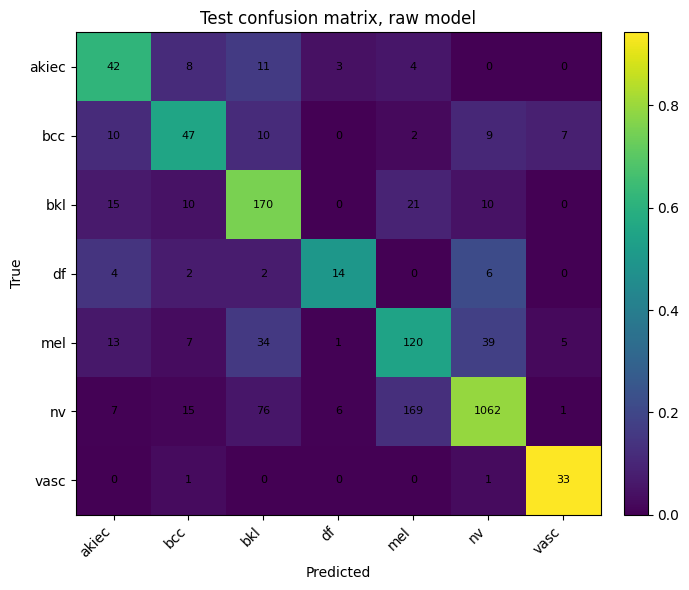

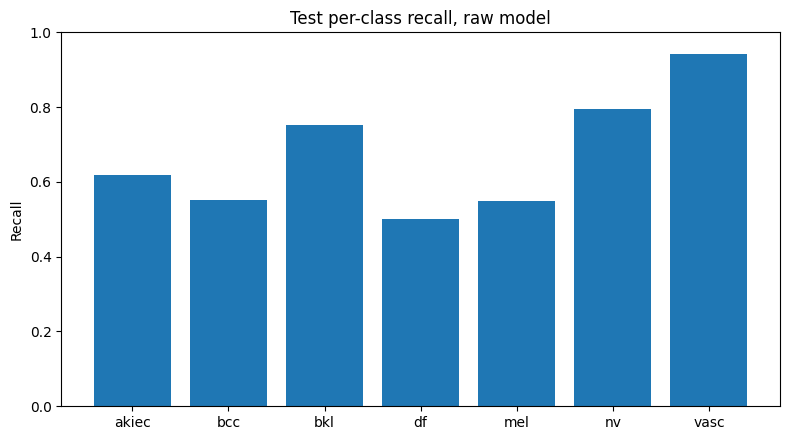

In [27]:
# --- Plot confusion matrix and per-class recall ---

def plot_confusion(y_true, probs, out_path, title="Confusion matrix"):
    pred = probs.argmax(axis=1)
    cm = confusion_matrix(y_true, pred, labels=np.arange(N_CLASSES))
    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm_norm, aspect="auto")
    ax.set_xticks(np.arange(N_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
    ax.set_yticks(np.arange(N_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=8)
    fig.tight_layout()
    fig.savefig(out_path, dpi=200)
    plt.show()
    return cm


def plot_per_class_recall(y_true, probs, out_path, title="Per-class recall"):
    tab = per_class_table(y_true, probs)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.bar(tab["class"], tab["recall"])
    ax.set_ylim(0, 1)
    ax.set_ylabel("Recall")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(out_path, dpi=200)
    plt.show()
    return tab

if model_eval is not None:
    cm = plot_confusion(y_test, test_probs_raw, FIG_DIR / "confusion_matrix_raw.png", "Test confusion matrix, raw model")
    recall_tab = plot_per_class_recall(y_test, test_probs_raw, FIG_DIR / "per_class_recall_raw.png", "Test per-class recall, raw model")
else:
    print("Skipped plots; no model loaded.")

## 10. Temperature scaling calibration

Temperature scaling is fitted on validation logits only. It should improve probability calibration while leaving argmax predictions unchanged. It does **not** by itself prove that uncertainty is a good failure detector, which is why risk--coverage is evaluated separately.

In [28]:
# --- Temperature scaling ---
# fit_temperature_scaling is defined in the metric utilities cell so repeated-seed confirmation can use it earlier.
# A single scalar temperature is fitted on the validation split only and then applied unchanged to test and ISIC2018 related-domain data.

if model_eval is not None:
    T, val_nll_T = fit_temperature_scaling(val_logits, y_val)
    print("Fitted temperature:", T, "validation NLL:", val_nll_T)
    val_probs_temp = softmax_np(val_logits, temperature=T)
    test_probs_temp = softmax_np(test_logits, temperature=T)
    temp_metrics = evaluate_probs(y_test, test_probs_temp, prefix="temp_")
    display(pd.DataFrame([raw_metrics, temp_metrics], index=["raw", "temperature_scaled"]).T)
    pd.DataFrame([{"temperature": T, "validation_nll_temperature": val_nll_T, **temp_metrics}]).to_csv(RESULT_DIR / "test_metrics_temperature_scaled.csv", index=False)

    calibration_params = {
        "temperature": float(T),
        "validation_nll_temperature": float(val_nll_T),
        "temperature_fitted_on": "HAM10000 validation split only",
        "applied_to": "held-out HAM10000 test and optional ISIC2018 related-domain test without refitting",
        "ece_definition": "top-label expected calibration error",
        "ece_bins": int(CONFIG["n_bins_ece"]),
        "ece_binning": "equal-width bins over [0, 1]; final bin includes 1.0",
        "scalar_temperature_limitation": "A single global scalar assumes uniform logit overconfidence and may not correct class-wise or subgroup calibration heterogeneity.",
        "clinical_acceptability_note": CONFIG.get("ece_acceptability_note", "No universal clinical ECE threshold is assumed."),
    }
    with open(RESULT_DIR / "reviewer_temperature_scaling_and_ece_definition.json", "w") as f:
        json.dump(calibration_params, f, indent=2)
else:
    print("Skipped temperature scaling; no model loaded.")


Fitted temperature: 1.6361967325210571 validation NLL: 0.6123189330101013


,raw,temperature_scaled
raw_accuracy,0.745118,NaN
raw_balanced_accuracy,0.672645,NaN
raw_macro_f1,0.624629,NaN
raw_weighted_f1,0.761538,NaN
raw_macro_recall,0.672645,NaN
raw_brier,0.362036,NaN
raw_nll,0.730715,NaN
raw_ece,0.111334,NaN
raw_mce,0.312631,NaN
raw_ece_n_bins,15.000000,NaN


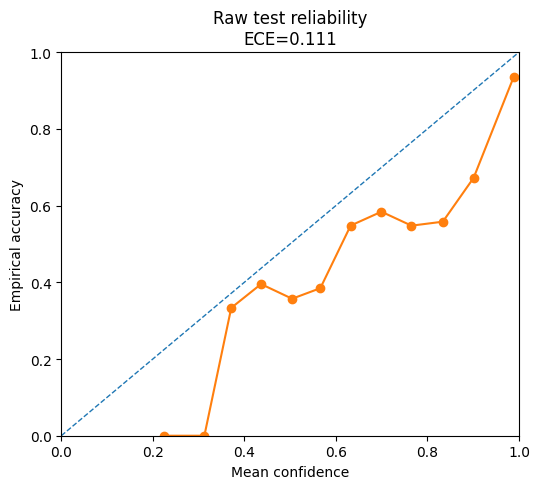

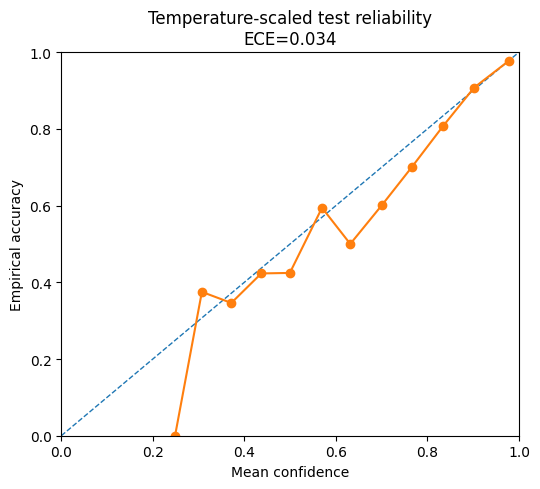

In [29]:
# --- Reliability diagrams ---

def plot_reliability(y_true, probs, out_path, title="Reliability diagram", n_bins=15):
    ece, bin_df = expected_calibration_error(y_true, probs, n_bins=n_bins)
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
    valid = bin_df["n"] > 0
    ax.plot(bin_df.loc[valid, "confidence"], bin_df.loc[valid, "accuracy"], marker="o")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("Mean confidence")
    ax.set_ylabel("Empirical accuracy")
    ax.set_title(f"{title}\nECE={ece:.3f}")
    fig.tight_layout()
    fig.savefig(out_path, dpi=200)
    plt.show()
    return bin_df

if model_eval is not None:
    raw_bins = plot_reliability(y_test, test_probs_raw, FIG_DIR / "reliability_raw.png", "Raw test reliability", CONFIG["n_bins_ece"])
    temp_bins = plot_reliability(y_test, test_probs_temp, FIG_DIR / "reliability_temperature_scaled.png", "Temperature-scaled test reliability", CONFIG["n_bins_ece"])
    raw_bins.to_csv(RESULT_DIR / "reliability_bins_raw.csv", index=False)
    temp_bins.to_csv(RESULT_DIR / "reliability_bins_temperature_scaled.csv", index=False)
else:
    print("Skipped reliability diagrams; no model loaded.")

In [30]:
# --- Evaluate all trained model variants found in MODEL_DIR ---
# This creates a paper-ready comparison table for backbone/loss/seed runs.
# It uses the same validation-fitted temperature logic per model and evaluates once on the held-out test split.

def infer_model_metadata_from_path(model_path):
    run_tag = model_path.parent.name
    use_meta = "_meta_" in run_tag or "_multimodal_" in run_tag
    loss_type = "weighted_ce"
    for cand in ["class_balanced_ce", "weighted_ce", "focal"]:
        if run_tag.endswith(cand) or f"_{cand}" in run_tag:
            loss_type = cand
    return run_tag, use_meta, loss_type


all_model_rows = []
model_paths = sorted(MODEL_DIR.rglob("final_model.keras"))

for model_path in model_paths:
    try:
        run_tag, use_meta_i, loss_type_i = infer_model_metadata_from_path(model_path)
        m_i = safe_load_model(model_path)
        _, val_ds_i, test_ds_i = datasets_for(use_metadata=model_uses_metadata(m_i), loss_type=loss_type_i)

        v_logits, v_y = collect_logits(m_i, val_ds_i)
        te_logits, te_y = collect_logits(m_i, test_ds_i)

        t_i, val_nll_i = fit_temperature_scaling(v_logits, v_y, max_iter=250, lr=0.05)
        te_probs_raw = softmax_np(te_logits)
        te_probs_t = softmax_np(te_logits, temperature=t_i)

        raw_i = evaluate_probs(te_y, te_probs_raw, prefix="raw_")
        temp_i = evaluate_probs(te_y, te_probs_t, prefix="temp_")
        row = {
            "run_tag": run_tag,
            "model_path": str(model_path),
            "uses_metadata": model_uses_metadata(m_i),
            "temperature": t_i,
            "val_nll_temperature": val_nll_i,
            **raw_i,
            **temp_i,
        }

        runtime_path = model_path.parent / "runtime.json"
        if runtime_path.exists():
            try:
                rt = json.load(open(runtime_path))
                for k in ["backbone", "seed", "loss_type", "total_seconds", "head_seconds", "finetune_seconds", "reused_existing"]:
                    row[k] = rt.get(k)
            except Exception:
                pass

        all_model_rows.append(row)
        print("Evaluated:", run_tag)

    except Exception as e:
        all_model_rows.append({"run_tag": model_path.parent.name, "model_path": str(model_path), "error": repr(e)})
        print("Could not evaluate", model_path, "->", repr(e))

if all_model_rows:
    model_comparison_df = pd.DataFrame(all_model_rows)
    sort_col = "temp_macro_f1" if "temp_macro_f1" in model_comparison_df.columns else model_comparison_df.columns[0]
    display(model_comparison_df.sort_values(sort_col, ascending=False, na_position="last"))
    model_comparison_df.to_csv(RESULT_DIR / "all_trained_model_comparison.csv", index=False)
else:
    print("No trained model variants found yet.")

Evaluated: EfficientNetB0_image_seed2026_weighted_ce
Evaluated: EfficientNetB0_image_seed3407_weighted_ce
Evaluated: EfficientNetB0_image_seed42_class_balanced_ce
Evaluated: EfficientNetB0_image_seed42_focal
Evaluated: EfficientNetB0_image_seed42_weighted_ce
Evaluated: FINALCONFIRM_ResNet50_image_seed2026_weighted_ce
Evaluated: FINALCONFIRM_ResNet50_image_seed3407_weighted_ce
Evaluated: FINALCONFIRM_ResNet50_image_seed42_weighted_ce
Evaluated: MobileNetV2_image_seed42_weighted_ce
Evaluated: ResNet50_image_seed42_weighted_ce


,run_tag,model_path,uses_metadata,temperature,val_nll_temperature,raw_accuracy,raw_balanced_accuracy,raw_macro_f1,raw_weighted_f1,raw_macro_recall,...,temp_mce,temp_ece_n_bins,temp_ovr_roc_auc_macro,backbone,seed,loss_type,total_seconds,head_seconds,finetune_seconds,reused_existing
5,FINALCONFIRM_ResNet50_image_seed2026_weighted_ce,/content/drive/MyDrive/ham10000_trustworthy_ai...,False,1.576744,0.635445,0.744617,0.673806,0.635591,0.761767,0.673806,...,0.240707,15,0.944316,ResNet50,2026,weighted_ce,1701.829810,555.295989,1146.533821,False
6,FINALCONFIRM_ResNet50_image_seed3407_weighted_ce,/content/drive/MyDrive/ham10000_trustworthy_ai...,False,1.308002,0.662491,0.747121,0.686372,0.630642,0.763078,0.686372,...,0.261167,15,0.941213,ResNet50,3407,weighted_ce,1442.091351,558.110517,883.980833,False
7,FINALCONFIRM_ResNet50_image_seed42_weighted_ce,/content/drive/MyDrive/ham10000_trustworthy_ai...,False,1.636197,0.612319,0.745118,0.672645,0.624629,0.761538,0.672645,...,0.248575,15,0.940787,ResNet50,42,weighted_ce,2146.998018,546.689490,1600.308528,False
9,ResNet50_image_seed42_weighted_ce,/content/drive/MyDrive/ham10000_trustworthy_ai...,False,1.636197,0.612319,0.745118,0.672645,0.624629,0.761538,0.672645,...,0.248575,15,0.940787,ResNet50,42,weighted_ce,2146.547348,549.196537,1597.350811,False
0,EfficientNetB0_image_seed2026_weighted_ce,/content/drive/MyDrive/ham10000_trustworthy_ai...,False,1.031840,0.729445,0.715073,0.676277,0.600148,0.739920,0.676277,...,0.154031,15,0.929247,EfficientNetB0,2026,weighted_ce,1705.911856,474.862529,1231.049327,False
4,EfficientNetB0_image_seed42_weighted_ce,/content/drive/MyDrive/ham10000_trustworthy_ai...,False,1.045838,0.740133,0.708062,0.676052,0.590008,0.733005,0.676052,...,0.133605,15,0.926977,EfficientNetB0,42,weighted_ce,1513.777135,473.652282,1040.124853,False
1,EfficientNetB0_image_seed3407_weighted_ce,/content/drive/MyDrive/ham10000_trustworthy_ai...,False,0.998077,0.743258,0.700050,0.663395,0.573229,0.727112,0.663395,...,0.129854,15,0.926615,EfficientNetB0,3407,weighted_ce,1571.888161,473.552103,1098.336058,False
8,MobileNetV2_image_seed42_weighted_ce,/content/drive/MyDrive/ham10000_trustworthy_ai...,False,0.989977,0.752362,0.706560,0.669500,0.566281,0.730675,0.669500,...,0.138086,15,0.927630,MobileNetV2,42,weighted_ce,1194.157618,406.326514,787.831103,False
2,EfficientNetB0_image_seed42_class_balanced_ce,/content/drive/MyDrive/ham10000_trustworthy_ai...,False,0.943728,0.762974,0.695043,0.666224,0.555465,0.722419,0.666224,...,0.093425,15,0.923699,EfficientNetB0,42,class_balanced_ce,1210.074846,475.086175,734.988671,False
3,EfficientNetB0_image_seed42_focal,/content/drive/MyDrive/ham10000_trustworthy_ai...,False,0.662295,0.785640,0.683525,0.653494,0.536910,0.714079,0.653494,...,0.108116,15,0.922272,EfficientNetB0,42,focal,1391.680252,472.455648,919.224604,False


## 11. Selective referral / abstention analysis

The model is sorted from most certain to least certain. As coverage decreases, the system refers more uncertain cases to human review. The core question is whether selective referral reduces risk without disproportionately harming high-risk lesion sensitivity or subgroup coverage.

In [31]:
# --- Uncertainty scores and selective risk ---

def predictive_entropy(probs, eps=1e-12):
    p = np.clip(probs, eps, 1.0)
    return -np.sum(p * np.log(p), axis=1)


def confidence_margin(probs):
    s = np.sort(probs, axis=1)
    return s[:, -1] - s[:, -2]


def uncertainty_scores(probs):
    return {
        "maxprob_uncertainty": 1.0 - probs.max(axis=1),
        "entropy": predictive_entropy(probs),
        "negative_margin": -confidence_margin(probs),  # larger = more uncertain
    }


def selective_curve(y_true, probs, uncertainty, positive_class=None):
    """Risk-coverage curve with correct automatic sensitivity accounting.

    If positive_class is provided, auto_sensitivity_for_class is computed as:

        true positives that are kept AND predicted positive / all true positives

    Referred cases are therefore not counted as automatically detected. This avoids
    the previous bug where all predicted positives were counted, which could produce
    impossible sensitivity values above 1.
    """
    y_true = np.asarray(y_true).astype(int)
    probs = np.asarray(probs)
    uncertainty = np.asarray(uncertainty)

    pred = probs.argmax(axis=1)
    order = np.argsort(uncertainty)  # keep most certain first
    rows = []
    n = len(y_true)

    for k in range(max(1, int(0.05 * n)), n + 1):
        keep = order[:k]
        kept_mask = np.zeros(n, dtype=bool)
        kept_mask[keep] = True

        y_keep = y_true[keep]
        pred_keep = pred[keep]

        coverage = k / n
        risk = 1.0 - accuracy_score(y_keep, pred_keep)

        bal_acc = (
            balanced_accuracy_score(y_keep, pred_keep)
            if len(np.unique(y_keep)) > 1 else np.nan
        )

        macro_f1 = f1_score(
            y_keep,
            pred_keep,
            average="macro",
            zero_division=0,
        )

        row = {
            "coverage": coverage,
            "referral_rate": 1.0 - coverage,
            "selective_risk": risk,
            "balanced_accuracy": bal_acc,
            "macro_f1": macro_f1,
        }

        if positive_class is not None:
            true_pos = y_true == positive_class
            total_pos = int(true_pos.sum())

            if total_pos > 0:
                auto_detected_pos = (
                    true_pos
                    & kept_mask
                    & (pred == positive_class)
                ).sum()

                row["auto_sensitivity_for_class"] = auto_detected_pos / total_pos
                row["coverage_for_true_class"] = kept_mask[true_pos].mean()
            else:
                row["auto_sensitivity_for_class"] = np.nan
                row["coverage_for_true_class"] = np.nan

        rows.append(row)

    curve = pd.DataFrame(rows)

    if "auto_sensitivity_for_class" in curve.columns:
        max_sens = curve["auto_sensitivity_for_class"].dropna().max()
        assert (pd.isna(max_sens)) or (max_sens <= 1.0 + 1e-9), (
            "Selective sensitivity bug detected: auto_sensitivity_for_class exceeded 1."
        )

    # Area under risk-coverage: lower is better.
    aurc = np.trapz(curve["selective_risk"], curve["coverage"])
    return curve, float(aurc)


def summarize_selective(y_true, probs, scores):
    rows = []
    curves = {}
    mel_idx = CLASS_TO_IDX["mel"]

    for name, score in scores.items():
        curve, aurc = selective_curve(y_true, probs, score, positive_class=mel_idx)
        curves[name] = curve

        for target_cov in [0.95, 0.90, 0.80, 0.70, 0.50]:
            i = np.argmin(np.abs(curve["coverage"] - target_cov))
            row = curve.iloc[i].to_dict()
            row.update({"score": name, "target_coverage": target_cov, "AURC": aurc})
            rows.append(row)

    summary = pd.DataFrame(rows)

    if "auto_sensitivity_for_class" in summary.columns:
        assert summary["auto_sensitivity_for_class"].dropna().le(1.0 + 1e-9).all(), (
            "Selective summary contains impossible sensitivity > 1."
        )

    return summary, curves


if model_eval is not None:
    # Use calibrated probabilities for referral thresholds by default.
    probs_for_referral = test_probs_temp
    scores = uncertainty_scores(probs_for_referral)
    selective_summary, selective_curves = summarize_selective(y_test, probs_for_referral, scores)
    display(selective_summary)
    selective_summary.to_csv(RESULT_DIR / "selective_referral_summary.csv", index=False)

    for name, curve in selective_curves.items():
        curve.to_csv(RESULT_DIR / f"selective_curve_{name}.csv", index=False)

    print("Selective-referral curves saved. Sensitivity sanity check passed: values are bounded by 1.")
else:
    print("Skipped selective referral; no model loaded.")


,coverage,referral_rate,selective_risk,balanced_accuracy,macro_f1,auto_sensitivity_for_class,coverage_for_true_class,score,target_coverage,AURC
0,0.949925,0.050075,0.231945,0.702595,0.651850,0.534247,0.926941,maxprob_uncertainty,0.95,0.084598
1,0.899850,0.100150,0.218141,0.717789,0.669892,0.488584,0.849315,maxprob_uncertainty,0.90,0.084598
2,0.800200,0.199800,0.174593,0.758204,0.717444,0.397260,0.648402,maxprob_uncertainty,0.80,0.084598
3,0.700050,0.299950,0.135193,0.779893,0.750510,0.356164,0.538813,maxprob_uncertainty,0.70,0.084598
4,0.499750,0.500250,0.052104,0.854585,0.842450,0.191781,0.223744,maxprob_uncertainty,0.50,0.084598
5,0.949925,0.050075,0.236162,0.698933,0.648921,0.525114,0.926941,entropy,0.95,0.085938
6,0.899850,0.100150,0.218141,0.719035,0.673069,0.497717,0.844749,entropy,0.90,0.085938
7,0.800200,0.199800,0.179599,0.752158,0.717094,0.433790,0.675799,entropy,0.80,0.085938
8,0.700050,0.299950,0.144492,0.784498,0.750856,0.356164,0.515982,entropy,0.70,0.085938
9,0.499750,0.500250,0.052104,0.874788,0.851497,0.200913,0.232877,entropy,0.50,0.085938


Selective-referral curves saved. Sensitivity sanity check passed: values are bounded by 1.


In [32]:
# --- Reviewer export: validation-chosen practical selective-referral operating point ---
# This turns the retrospective risk-coverage curves into a concrete threshold rule.
# The threshold is selected using validation labels only and then applied once to the held-out test split.


def metrics_at_uncertainty_threshold(y_true, probs, uncertainty, threshold):
    y_true = np.asarray(y_true).astype(int)
    probs = np.asarray(probs)
    uncertainty = np.asarray(uncertainty)
    pred = probs.argmax(axis=1)
    keep = uncertainty <= float(threshold)
    n = len(y_true)
    mel_idx = CLASS_TO_IDX["mel"]
    mel_mask = y_true == mel_idx

    if keep.sum() > 0:
        selective_risk = 1.0 - accuracy_score(y_true[keep], pred[keep])
        balanced_acc = balanced_accuracy_score(y_true[keep], pred[keep]) if len(np.unique(y_true[keep])) > 1 else np.nan
        macro_f1 = f1_score(y_true[keep], pred[keep], average="macro", zero_division=0)
    else:
        selective_risk = np.nan
        balanced_acc = np.nan
        macro_f1 = np.nan

    mel_auto = mel_mask & keep
    mel_referred = mel_mask & (~keep)
    mel_correct = mel_auto & (pred == mel_idx)
    mel_wrong = mel_auto & (pred != mel_idx)

    return {
        "threshold": float(threshold),
        "n_total": int(n),
        "n_auto_classified": int(keep.sum()),
        "n_referred": int((~keep).sum()),
        "coverage": float(keep.mean()),
        "referral_rate": float((~keep).mean()),
        "selective_risk": float(selective_risk) if not pd.isna(selective_risk) else np.nan,
        "balanced_accuracy_auto_classified": float(balanced_acc) if not pd.isna(balanced_acc) else np.nan,
        "macro_f1_auto_classified": float(macro_f1) if not pd.isna(macro_f1) else np.nan,
        "n_melanoma_total": int(mel_mask.sum()),
        "n_melanoma_auto_total": int(mel_auto.sum()),
        "n_melanoma_auto_correct": int(mel_correct.sum()),
        "n_melanoma_auto_wrong": int(mel_wrong.sum()),
        "n_melanoma_referred": int(mel_referred.sum()),
        "melanoma_coverage": float(mel_auto.sum() / max(mel_mask.sum(), 1)),
        "melanoma_auto_recall": float(mel_correct.sum() / max(mel_mask.sum(), 1)),
    }


def choose_threshold_on_validation(y_true_val, probs_val, uncertainty_val, target_risk=0.15, min_coverage=0.50):
    thresholds = np.unique(np.asarray(uncertainty_val, dtype=float))
    rows = []
    for thr in thresholds:
        m = metrics_at_uncertainty_threshold(y_true_val, probs_val, uncertainty_val, thr)
        rows.append(m)
    curve = pd.DataFrame(rows).sort_values(["coverage", "threshold"]).reset_index(drop=True)

    eligible = curve[
        (curve["coverage"] >= float(min_coverage))
        & (curve["selective_risk"] <= float(target_risk))
    ].copy()

    if len(eligible):
        chosen = eligible.sort_values(["coverage", "selective_risk"], ascending=[False, True]).iloc[0].to_dict()
        chosen["target_risk_achieved_on_validation"] = True
        chosen["selection_rule"] = "maximum_validation_coverage_with_selective_risk_at_or_below_target"
    else:
        fallback_pool = curve[curve["coverage"] >= float(min_coverage)].copy()
        if fallback_pool.empty:
            fallback_pool = curve.copy()
        chosen = fallback_pool.sort_values(["selective_risk", "coverage"], ascending=[True, False]).iloc[0].to_dict()
        chosen["target_risk_achieved_on_validation"] = False
        chosen["selection_rule"] = "minimum_observed_validation_risk_fallback"

    chosen["target_selective_risk"] = float(target_risk)
    chosen["minimum_validation_coverage"] = float(min_coverage)
    return chosen, curve


if model_eval is not None and "val_probs_temp" in globals() and "test_probs_temp" in globals():
    score_name = CONFIG.get("primary_uncertainty_score", "entropy")
    val_score = uncertainty_scores(val_probs_temp)[score_name]
    test_score = uncertainty_scores(test_probs_temp)[score_name]

    chosen_val, validation_threshold_curve = choose_threshold_on_validation(
        y_true_val=y_val,
        probs_val=val_probs_temp,
        uncertainty_val=val_score,
        target_risk=CONFIG.get("referral_target_selective_risk", 0.15),
        min_coverage=CONFIG.get("referral_minimum_validation_coverage", 0.50),
    )

    test_operating = metrics_at_uncertainty_threshold(
        y_true=y_test,
        probs=test_probs_temp,
        uncertainty=test_score,
        threshold=chosen_val["threshold"],
    )

    policy = {
        "primary_uncertainty_score": score_name,
        "threshold_selected_on": "HAM10000 validation split only",
        "threshold_applied_to": "held-out HAM10000 test split",
        "threshold_direction": "auto-classify if uncertainty_score <= threshold; refer otherwise",
        "target_selective_risk": CONFIG.get("referral_target_selective_risk", 0.15),
        "minimum_validation_coverage": CONFIG.get("referral_minimum_validation_coverage", 0.50),
        "selection_rule": chosen_val["selection_rule"],
        "target_risk_achieved_on_validation": bool(chosen_val["target_risk_achieved_on_validation"]),
        "chosen_threshold": float(chosen_val["threshold"]),
        "clinical_example_language": (
            "For a local triage policy requiring the automatic arm to remain at or below the specified selective-risk target, "
            "cases with entropy above the validation-chosen threshold are referred rather than automatically classified. "
            "This is an example operating point, not a deployment recommendation."
        ),
    }

    validation_threshold_curve.to_csv(RESULT_DIR / "selective_referral_validation_threshold_curve.csv", index=False)
    pd.DataFrame([chosen_val]).to_csv(RESULT_DIR / "selective_referral_operating_point_validation_chosen.csv", index=False)
    pd.DataFrame([test_operating]).to_csv(RESULT_DIR / "selective_referral_operating_point_test_results.csv", index=False)
    with open(RESULT_DIR / "selective_referral_threshold_policy.json", "w") as f:
        json.dump(policy, f, indent=2)

    worked_example = f"""# Selective referral worked operating-point example

This example is selected on the HAM10000 validation split only and then applied once to the held-out HAM10000 test split.

Local constraint used for this example: automatic classifications should have selective risk <= {policy['target_selective_risk']:.3f} while retaining at least {policy['minimum_validation_coverage']:.3f} validation coverage.

Primary uncertainty score: {score_name}.

Decision rule: auto-classify if {score_name} <= {chosen_val['threshold']:.6f}; otherwise refer/abstain.

Validation result at selected threshold: coverage {chosen_val['coverage']:.3f}, referral rate {chosen_val['referral_rate']:.3f}, selective risk {chosen_val['selective_risk']:.3f}.

Held-out test result at the same threshold: coverage {test_operating['coverage']:.3f}, referral rate {test_operating['referral_rate']:.3f}, selective risk {test_operating['selective_risk']:.3f}.

Melanoma counts on held-out test at this threshold: total melanoma {test_operating['n_melanoma_total']}, automatically classified melanoma {test_operating['n_melanoma_auto_total']}, automatically correct melanoma {test_operating['n_melanoma_auto_correct']}, automatically wrong melanoma {test_operating['n_melanoma_auto_wrong']}, referred melanoma {test_operating['n_melanoma_referred']}.

This is a worked example for manuscript transparency, not a deployment recommendation. A clinical site would need to set the risk target prospectively and validate it locally.
"""
    (RESULT_DIR / "selective_referral_worked_example.md").write_text(worked_example)

    display(pd.DataFrame([{"split": "validation_chosen", **chosen_val}, {"split": "test_applied", **test_operating}]))
    print("Saved validation-chosen referral threshold policy:", RESULT_DIR / "selective_referral_threshold_policy.json")
    print("Saved worked example:", RESULT_DIR / "selective_referral_worked_example.md")
else:
    print("Selective referral operating-point export skipped; run validation/test calibrated probabilities first.")


,split,threshold,n_total,n_auto_classified,n_referred,coverage,referral_rate,selective_risk,balanced_accuracy_auto_classified,macro_f1_auto_classified,...,n_melanoma_auto_total,n_melanoma_auto_correct,n_melanoma_auto_wrong,n_melanoma_referred,melanoma_coverage,melanoma_auto_recall,target_risk_achieved_on_validation,selection_rule,target_selective_risk,minimum_validation_coverage
0,validation_chosen,0.997711,1605.0,1227.0,378.0,0.764486,0.235514,0.149959,0.802378,0.760734,...,142.0,99.0,43.0,57.0,0.713568,0.497487,True,maximum_validation_coverage_with_selective_ris...,0.15,0.5
1,test_applied,0.997711,1997.0,1545.0,452.0,0.773660,0.226340,0.170874,0.771983,0.733198,...,142.0,94.0,48.0,77.0,0.648402,0.429224,NaN,NaN,NaN,NaN


Saved validation-chosen referral threshold policy: /content/drive/MyDrive/ham10000_trustworthy_ai/results/selective_referral_threshold_policy.json
Saved worked example: /content/drive/MyDrive/ham10000_trustworthy_ai/results/selective_referral_worked_example.md


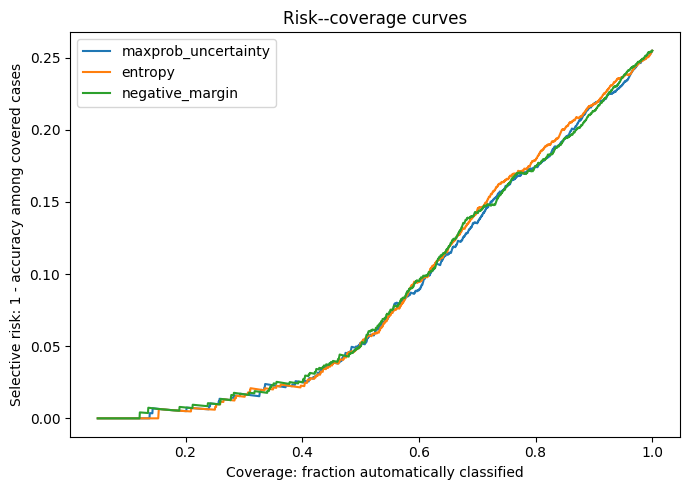

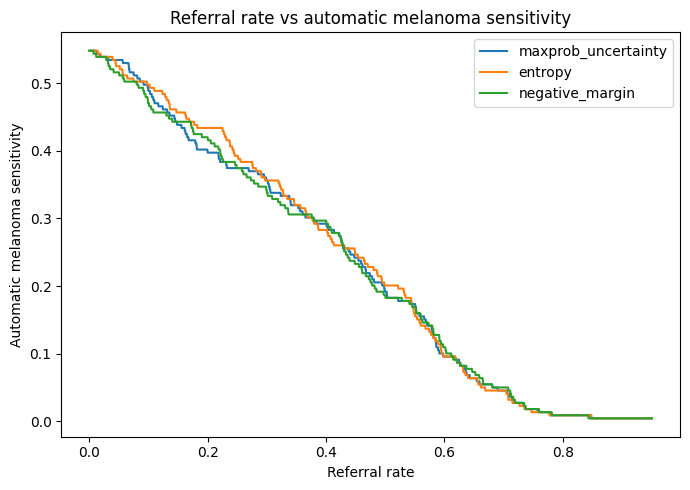

In [33]:
# --- Plot risk-coverage and referral curves ---

def plot_selective_curves(curves, out_path):
    fig, ax = plt.subplots(figsize=(7, 5))
    for name, curve in curves.items():
        ax.plot(curve["coverage"], curve["selective_risk"], label=name)
    ax.set_xlabel("Coverage: fraction automatically classified")
    ax.set_ylabel("Selective risk: 1 - accuracy among covered cases")
    ax.set_title("Risk--coverage curves")
    ax.legend()
    fig.tight_layout()
    fig.savefig(out_path, dpi=200)
    plt.show()


def plot_referral_vs_melanoma(curves, out_path):
    fig, ax = plt.subplots(figsize=(7, 5))
    for name, curve in curves.items():
        if "auto_sensitivity_for_class" in curve:
            ax.plot(curve["referral_rate"], curve["auto_sensitivity_for_class"], label=name)
    ax.set_xlabel("Referral rate")
    ax.set_ylabel("Automatic melanoma sensitivity")
    ax.set_title("Referral rate vs automatic melanoma sensitivity")
    ax.legend()
    fig.tight_layout()
    fig.savefig(out_path, dpi=200)
    plt.show()

if model_eval is not None:
    plot_selective_curves(selective_curves, FIG_DIR / "risk_coverage_curves.png")
    plot_referral_vs_melanoma(selective_curves, FIG_DIR / "referral_vs_melanoma_sensitivity.png")
else:
    print("Skipped selective plots; no model loaded.")

## 12. Internal subgroup analysis: sex, age, anatomical site, label-confirmation type

HAM10000 should not be over-claimed as a skin-tone fairness benchmark, because it does not provide reliable skin-tone or ethnicity labels. However, it does support internal subgroup analysis using available metadata: sex, age, anatomical site, and diagnosis-confirmation type.

In [34]:
import numpy as np
import pandas as pd

# --- Subgroup analysis ---

def add_age_bins(df):
    out = df.copy()
    out["age_bin"] = pd.cut(out["age"], bins=[-np.inf, 30, 45, 60, 75, np.inf], labels=["<=30", "31-45", "46-60", "61-75", ">75"])
    out["age_bin"] = out["age_bin"].astype(str).replace("nan", "missing")
    return out


def subgroup_metrics(df, y_true, probs, subgroup_col, min_n=30):
    rows = []
    tmp = df.reset_index(drop=True).copy()
    tmp["y_true"] = y_true
    pred = probs.argmax(axis=1)
    tmp["y_pred"] = pred

    # Get melanoma class index, assuming CLASS_TO_IDX is available in the global scope
    mel_idx = CLASS_TO_IDX["mel"]

    for group, idx in tmp.groupby(subgroup_col).groups.items():
        idx = np.array(list(idx))
        if len(idx) < min_n:
            continue

        subgroup_y_true = y_true[idx]
        subgroup_probs = probs[idx]
        subgroup_pred = subgroup_probs.argmax(axis=1)

        metrics = evaluate_probs(subgroup_y_true, subgroup_probs, prefix="")

        # Calculate melanoma recall for the subgroup
        mask_melanoma = subgroup_y_true == mel_idx
        total_melanoma_in_subgroup = mask_melanoma.sum()

        if total_melanoma_in_subgroup > 0:
            melanoma_recall_val = recall_score(mask_melanoma.astype(int), (subgroup_pred == mel_idx).astype(int), zero_division=0)
        else:
            melanoma_recall_val = np.nan # Use NaN if no melanoma cases in subgroup

        metrics["melanoma_recall"] = melanoma_recall_val

        metrics.update({"subgroup_variable": subgroup_col, "subgroup": str(group), "n": len(idx)})
        rows.append(metrics)
    return pd.DataFrame(rows)

if model_eval is not None:
    test_df_eval = add_age_bins(test_df)
    subgroup_vars = ["sex", "age_bin", "localization", "dx_type"]
    subgroup_tables = []
    for var in subgroup_vars:
        tab = subgroup_metrics(test_df_eval, y_test, test_probs_temp, var, min_n=CONFIG["min_subgroup_n"])
        subgroup_tables.append(tab)
    subgroup_results = pd.concat(subgroup_tables, axis=0, ignore_index=True)
    display(subgroup_results.sort_values(["subgroup_variable", "balanced_accuracy"]))
    subgroup_results.to_csv(RESULT_DIR / "internal_subgroup_metrics_temperature_scaled.csv", index=False)

    # Gap summary per variable.
    gap_rows = []
    for var, g in subgroup_results.groupby("subgroup_variable"):
        for metric in ["balanced_accuracy", "macro_f1", "brier", "ece", "melanoma_recall"]:
            vals = g[metric].dropna()
            if len(vals) >= 2:
                gap_rows.append({"subgroup_variable": var, "metric": metric, "min": vals.min(), "max": vals.max(), "gap": vals.max() - vals.min()})
    gap_df = pd.DataFrame(gap_rows)
    display(gap_df)
    gap_df.to_csv(RESULT_DIR / "internal_subgroup_gap_summary.csv", index=False)


    # Reviewer-facing sex subgroup interpretation note.
    sex_rows = subgroup_results.loc[subgroup_results["subgroup_variable"] == "sex"].copy()
    note_lines = [
        "# Sex subgroup calibration and discrimination note",
        "",
        "This note is generated from the internal HAM10000 test split. It is descriptive only and should not be interpreted causally.",
    ]
    if len(sex_rows):
        note_lines.append("")
        for _, row in sex_rows.sort_values("subgroup").iterrows():
            note_lines.append(
                f"- {row['subgroup']}: n={int(row['n'])}, balanced accuracy={row.get('balanced_accuracy', np.nan):.3f}, "
                f"macro-F1={row.get('macro_f1', np.nan):.3f}, ECE={row.get('ece', np.nan):.3f}, "
                f"melanoma recall={row.get('melanoma_recall', np.nan) if not pd.isna(row.get('melanoma_recall', np.nan)) else float('nan'):.3f}."
            )
        note_lines.append("")
        note_lines.append(
            "If one sex subgroup shows better discrimination but worse calibration, report this as evidence that global scalar temperature scaling may not correct subgroup-specific calibration heterogeneity. "
            "The notebook does not infer a biological cause, because HAM10000 subgroup variables are observational and confounded by acquisition site, diagnosis mix, lesion location, and sample size."
        )
    else:
        note_lines.append("No sex subgroup rows met the minimum subgroup size threshold in this run.")

    (RESULT_DIR / "subgroup_sex_calibration_discrimination_note.md").write_text("\n".join(note_lines))
    print("Saved:", RESULT_DIR / "subgroup_sex_calibration_discrimination_note.md")
else:
    print("Skipped subgroup analysis; no model loaded.")

,accuracy,balanced_accuracy,macro_f1,weighted_f1,macro_recall,brier,nll,ece,mce,ece_n_bins,ovr_roc_auc_macro,melanoma_recall,subgroup_variable,subgroup,n
5,0.769953,0.570000,0.404912,0.841693,0.456000,0.344931,0.593339,0.114210,0.683696,15,NaN,0.500000,age_bin,<=30,213
3,0.756757,0.635177,0.594302,0.775658,0.635177,0.333371,0.646703,0.048148,0.260691,15,0.934938,0.661765,age_bin,46-60,592
4,0.682353,0.668067,0.616348,0.689408,0.668067,0.416196,0.811168,0.065643,0.244537,15,0.930850,0.571429,age_bin,61-75,425
6,0.645833,0.677055,0.651947,0.645988,0.677055,0.448779,0.882169,0.104994,0.165234,15,NaN,0.566667,age_bin,>75,144
2,0.791191,0.741011,0.618506,0.811997,0.741011,0.256112,0.458605,0.046408,0.213953,15,0.954667,0.348837,age_bin,31-45,613
18,0.574004,0.600045,0.527496,0.584475,0.600045,0.551189,1.022195,0.092194,0.261055,15,0.898392,0.547945,dx_type,histo,1054
16,0.789474,0.800849,0.566690,0.833903,0.533899,0.289707,0.576547,0.069953,0.631739,15,NaN,NaN,dx_type,consensus,190
17,0.979647,0.979647,0.197944,0.989719,0.195929,0.041887,0.098624,0.045523,0.630344,15,NaN,NaN,dx_type,follow_up,737
11,0.786667,0.339869,0.261538,0.821333,0.254902,0.238646,0.456387,0.099215,0.435583,15,NaN,0.166667,localization,foot,75
10,0.622517,0.580871,0.525875,0.602928,0.580871,0.533991,1.093696,0.114872,0.211135,15,NaN,0.115385,localization,face,151


,subgroup_variable,metric,min,max,gap
0,age_bin,balanced_accuracy,0.570000,0.741011,0.171011
1,age_bin,macro_f1,0.404912,0.651947,0.247035
2,age_bin,brier,0.256112,0.448779,0.192667
3,age_bin,ece,0.046408,0.114210,0.067803
4,age_bin,melanoma_recall,0.348837,0.661765,0.312927
5,dx_type,balanced_accuracy,0.600045,0.979647,0.379602
6,dx_type,macro_f1,0.197944,0.566690,0.368746
7,dx_type,brier,0.041887,0.551189,0.509302
8,dx_type,ece,0.045523,0.092194,0.046671
9,localization,balanced_accuracy,0.339869,0.928571,0.588702


Saved: /content/drive/MyDrive/ham10000_trustworthy_ai/results/subgroup_sex_calibration_discrimination_note.md


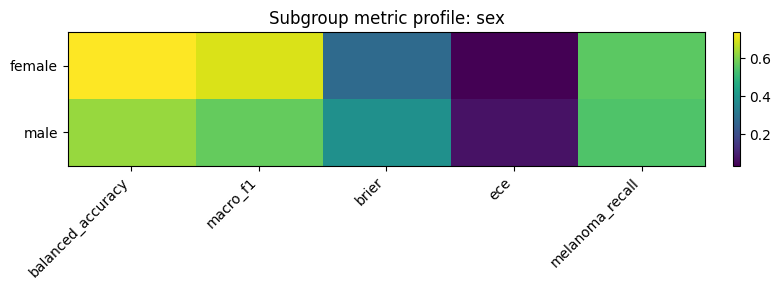

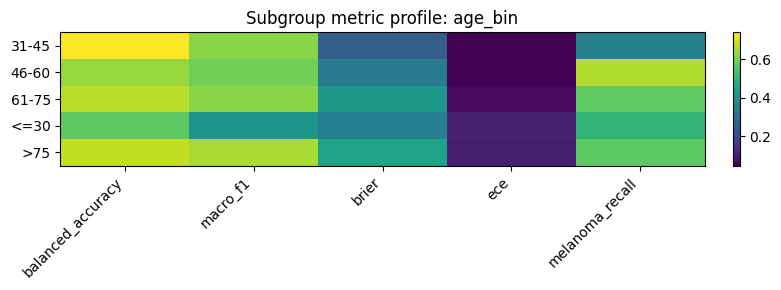

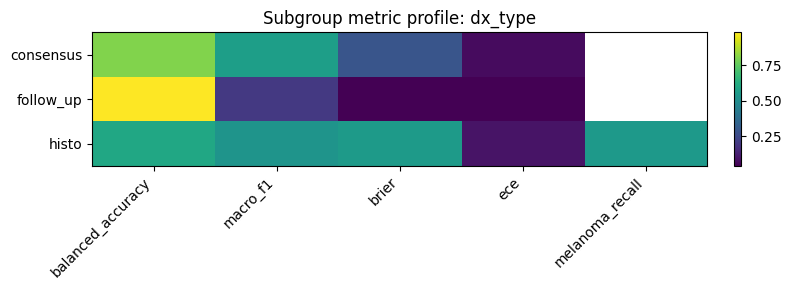

In [35]:
# --- Subgroup heatmap-style plot with matplotlib ---

if model_eval is not None and 'subgroup_results' in globals() and len(subgroup_results):
    plot_df = subgroup_results.copy()
    # Keep only moderate-sized subgroup tables to avoid unreadable figures.
    for var in ["sex", "age_bin", "dx_type"]:
        sub = plot_df[plot_df["subgroup_variable"] == var].copy()
        if sub.empty:
            continue
        metrics_to_plot = ["balanced_accuracy", "macro_f1", "brier", "ece", "melanoma_recall"]
        mat = sub.set_index("subgroup")[metrics_to_plot]
        fig, ax = plt.subplots(figsize=(8, max(3, 0.5 * len(mat))))
        im = ax.imshow(mat.values, aspect="auto")
        ax.set_xticks(np.arange(len(metrics_to_plot))); ax.set_xticklabels(metrics_to_plot, rotation=45, ha="right")
        ax.set_yticks(np.arange(len(mat.index))); ax.set_yticklabels(mat.index)
        ax.set_title(f"Subgroup metric profile: {var}")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        fig.tight_layout()
        fig.savefig(FIG_DIR / f"subgroup_metric_profile_{var}.png", dpi=200)
        plt.show()
else:
    print("Skipped subgroup plots.")

In [36]:
# --- Section 12A. Per-subgroup class counts ---
# Purpose:
#   Report the denominator behind subgroup metrics, especially melanoma, df, vasc, and akiec.
#   This prevents over-interpreting unstable recall values in small subgroups.

if model_eval is not None:
    test_df_eval = add_age_bins(test_df)
    subgroup_vars = ["sex", "age_bin", "localization", "dx_type"]

    subgroup_count_rows = []

    for var in subgroup_vars:
        tmp = test_df_eval.reset_index(drop=True).copy()
        tmp["true_label_id"] = y_test
        tmp["true_label"] = [CLASS_NAMES[int(i)] for i in y_test]

        for subgroup_name, g in tmp.groupby(var, dropna=False):
            label_counts = (
                g["true_label"]
                .value_counts()
                .reindex(CLASS_NAMES)
                .fillna(0)
                .astype(int)
                .to_dict()
            )

            row = {
                "subgroup_variable": var,
                "subgroup": str(subgroup_name),
                "n": int(len(g)),
            }

            # Add all class counts.
            for cls in CLASS_NAMES:
                row[f"n_{cls}"] = int(label_counts.get(cls, 0))

            # Add key rare/high-risk denominators explicitly.
            row["n_mel"] = int(label_counts.get("mel", 0))
            row["n_df"] = int(label_counts.get("df", 0))
            row["n_vasc"] = int(label_counts.get("vasc", 0))
            row["n_akiec"] = int(label_counts.get("akiec", 0))

            # Helpful instability flags.
            row["has_melanoma_cases"] = row["n_mel"] > 0
            row["melanoma_recall_unstable_if_lt10"] = row["n_mel"] < 10
            row["rare_class_min_n_akiec_df_vasc_mel"] = int(
                min(row["n_akiec"], row["n_df"], row["n_vasc"], row["n_mel"])
            )

            subgroup_count_rows.append(row)

    subgroup_class_counts = pd.DataFrame(subgroup_count_rows)

    # Sort to match the main subgroup table style.
    subgroup_class_counts = subgroup_class_counts.sort_values(
        ["subgroup_variable", "n"],
        ascending=[True, False]
    ).reset_index(drop=True)

    display_cols = [
        "subgroup_variable", "subgroup", "n",
        "n_akiec", "n_df", "n_vasc", "n_mel",
        "melanoma_recall_unstable_if_lt10",
        "rare_class_min_n_akiec_df_vasc_mel"
    ]

    display(subgroup_class_counts[display_cols])

    subgroup_class_counts.to_csv(
        RESULT_DIR / "internal_subgroup_class_counts.csv",
        index=False
    )

    print("Saved:", RESULT_DIR / "internal_subgroup_class_counts.csv")

else:
    print("Skipped subgroup class counts; no model loaded.")

,subgroup_variable,subgroup,n,n_akiec,n_df,n_vasc,n_mel,melanoma_recall_unstable_if_lt10,rare_class_min_n_akiec_df_vasc_mel
0,age_bin,31-45,613,4,10,7,43,False,4
1,age_bin,46-60,592,16,11,10,68,False,10
2,age_bin,61-75,425,31,5,8,70,False,5
3,age_bin,<=30,213,0,2,5,6,True,0
4,age_bin,>75,144,17,0,5,30,False,0
5,age_bin,missing,10,0,0,0,2,True,0
6,dx_type,histo,1054,68,12,11,219,False,11
7,dx_type,follow_up,737,0,0,0,0,True,0
8,dx_type,consensus,190,0,16,24,0,True,0
9,dx_type,confocal,16,0,0,0,0,True,0


Saved: /content/drive/MyDrive/ham10000_trustworthy_ai/results/internal_subgroup_class_counts.csv


In [37]:
# --- Section 12B. Selective referral by subgroup ---
# Purpose:
#   For each subgroup, report how many cases would be automatically classified
#   and how many would be referred under fixed coverage or fixed target-risk rules.
#
# This directly supports the paper question:
#   "When should a skin-lesion AI abstain and refer to a human?"

def subgroup_selective_metrics_at_coverage(
    y_true_sub,
    probs_sub,
    uncertainty_sub,
    target_coverage=0.80
):
    """Selective-referral metrics within one subgroup at a fixed coverage."""
    y_true_sub = np.asarray(y_true_sub).astype(int)
    probs_sub = np.asarray(probs_sub)
    uncertainty_sub = np.asarray(uncertainty_sub)

    pred_sub = probs_sub.argmax(axis=1)
    n = len(y_true_sub)

    if n == 0:
        return None

    # Keep most certain cases.
    order = np.argsort(uncertainty_sub)
    k = int(np.ceil(target_coverage * n))
    k = max(1, min(k, n))
    keep = order[:k]

    y_keep = y_true_sub[keep]
    pred_keep = pred_sub[keep]

    mel_idx = CLASS_TO_IDX["mel"]
    true_mel_all = y_true_sub == mel_idx

    if true_mel_all.sum() > 0:
        # Automatic melanoma recall:
        # true melanoma cases must be both kept and predicted as melanoma.
        kept_mask = np.zeros(n, dtype=bool)
        kept_mask[keep] = True

        auto_mel_detected = (
            true_mel_all
            & kept_mask
            & (pred_sub == mel_idx)
        ).sum()

        melanoma_auto_recall = auto_mel_detected / true_mel_all.sum()
        melanoma_coverage = kept_mask[true_mel_all].mean()
    else:
        melanoma_auto_recall = np.nan
        melanoma_coverage = np.nan

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        if len(np.unique(y_keep)) >= 2:
            bal_acc = balanced_accuracy_score(y_keep, pred_keep)
        else:
            bal_acc = np.nan

        macro_f1 = f1_score(
            y_keep,
            pred_keep,
            average="macro",
            zero_division=0
        )

    return {
        "target_coverage": float(target_coverage),
        "achieved_coverage": float(k / n),
        "referral_rate": float(1.0 - (k / n)),
        "n_total": int(n),
        "n_auto_classified": int(k),
        "n_referred": int(n - k),
        "selective_risk": float(1.0 - accuracy_score(y_keep, pred_keep)),
        "balanced_accuracy_auto_classified": float(bal_acc) if not pd.isna(bal_acc) else np.nan,
        "macro_f1_auto_classified": float(macro_f1),
        "melanoma_auto_recall": float(melanoma_auto_recall) if not pd.isna(melanoma_auto_recall) else np.nan,
        "melanoma_coverage": float(melanoma_coverage) if not pd.isna(melanoma_coverage) else np.nan,
        "n_mel": int(true_mel_all.sum()),
        "n_akiec": int((y_true_sub == CLASS_TO_IDX["akiec"]).sum()),
        "n_df": int((y_true_sub == CLASS_TO_IDX["df"]).sum()),
        "n_vasc": int((y_true_sub == CLASS_TO_IDX["vasc"]).sum()),
    }


def subgroup_selective_curve(y_true_sub, probs_sub, uncertainty_sub):
    """Full subgroup risk-coverage curve."""
    y_true_sub = np.asarray(y_true_sub).astype(int)
    probs_sub = np.asarray(probs_sub)
    uncertainty_sub = np.asarray(uncertainty_sub)

    pred_sub = probs_sub.argmax(axis=1)
    n = len(y_true_sub)

    order = np.argsort(uncertainty_sub)
    rows = []

    for k in range(1, n + 1):
        keep = order[:k]
        y_keep = y_true_sub[keep]
        pred_keep = pred_sub[keep]

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            if len(np.unique(y_keep)) >= 2:
                bal_acc = balanced_accuracy_score(y_keep, pred_keep)
            else:
                bal_acc = np.nan

        rows.append({
            "coverage": k / n,
            "referral_rate": 1.0 - (k / n),
            "selective_risk": 1.0 - accuracy_score(y_keep, pred_keep),
            "balanced_accuracy_auto_classified": bal_acc,
            "macro_f1_auto_classified": f1_score(
                y_keep,
                pred_keep,
                average="macro",
                zero_division=0
            )
        })

    return pd.DataFrame(rows)


def subgroup_selective_at_target_risk(
    y_true_sub,
    probs_sub,
    uncertainty_sub,
    target_risk=0.20
):
    """Find maximum subgroup coverage that keeps selective risk <= target_risk."""
    curve = subgroup_selective_curve(y_true_sub, probs_sub, uncertainty_sub)

    eligible = curve[curve["selective_risk"] <= target_risk].copy()

    if eligible.empty:
        # No operating point achieves the target risk.
        best = curve.sort_values("selective_risk", ascending=True).iloc[0].to_dict()
        best.update({
            "target_risk": float(target_risk),
            "target_risk_achieved": False,
            "selection_rule": "minimum_observed_risk_because_target_not_reached",
        })
        return best

    # Among eligible points, choose largest coverage.
    best = eligible.sort_values("coverage", ascending=False).iloc[0].to_dict()
    best.update({
        "target_risk": float(target_risk),
        "target_risk_achieved": True,
        "selection_rule": "maximum_coverage_under_target_risk",
    })
    return best


if model_eval is not None:
    test_df_eval = add_age_bins(test_df)
    subgroup_vars = ["sex", "age_bin", "localization", "dx_type"]

    # Use calibrated probabilities for referral.
    probs_for_referral = test_probs_temp

    # Main uncertainty score.
    # Use entropy as the primary paper-facing score; maxprob can be used as sensitivity analysis.
    all_scores = uncertainty_scores(probs_for_referral)

    fixed_coverages = [0.95, 0.90, 0.80, 0.70]
    target_risks = [0.20, 0.15, 0.10]

    fixed_coverage_rows = []
    target_risk_rows = []

    for score_name, uncertainty in all_scores.items():
        for var in subgroup_vars:
            for subgroup_name, subgroup_index in test_df_eval.groupby(var, dropna=False).groups.items():
                subgroup_index = np.asarray(list(subgroup_index))

                if len(subgroup_index) < CONFIG["min_subgroup_n"]:
                    continue

                y_sub = y_test[subgroup_index]
                probs_sub = probs_for_referral[subgroup_index]
                uncertainty_sub = uncertainty[subgroup_index]

                for cov in fixed_coverages:
                    row = subgroup_selective_metrics_at_coverage(
                        y_true_sub=y_sub,
                        probs_sub=probs_sub,
                        uncertainty_sub=uncertainty_sub,
                        target_coverage=cov
                    )
                    row.update({
                        "score": score_name,
                        "subgroup_variable": var,
                        "subgroup": str(subgroup_name),
                        "rule_type": "fixed_coverage",
                    })
                    fixed_coverage_rows.append(row)

                for risk in target_risks:
                    row = subgroup_selective_at_target_risk(
                        y_true_sub=y_sub,
                        probs_sub=probs_sub,
                        uncertainty_sub=uncertainty_sub,
                        target_risk=risk
                    )
                    row.update({
                        "score": score_name,
                        "subgroup_variable": var,
                        "subgroup": str(subgroup_name),
                        "n_total": int(len(subgroup_index)),
                        "n_mel": int((y_sub == CLASS_TO_IDX["mel"]).sum()),
                        "n_akiec": int((y_sub == CLASS_TO_IDX["akiec"]).sum()),
                        "n_df": int((y_sub == CLASS_TO_IDX["df"]).sum()),
                        "n_vasc": int((y_sub == CLASS_TO_IDX["vasc"]).sum()),
                        "rule_type": "target_risk",
                    })
                    target_risk_rows.append(row)

    subgroup_selective_fixed_coverage = pd.DataFrame(fixed_coverage_rows)
    subgroup_selective_target_risk = pd.DataFrame(target_risk_rows)

    display(
        subgroup_selective_fixed_coverage.sort_values(
            ["score", "subgroup_variable", "subgroup", "target_coverage"]
        )
    )

    display(
        subgroup_selective_target_risk.sort_values(
            ["score", "subgroup_variable", "subgroup", "target_risk"]
        )
    )

    subgroup_selective_fixed_coverage.to_csv(
        RESULT_DIR / "subgroup_selective_referral_fixed_coverage.csv",
        index=False
    )

    subgroup_selective_target_risk.to_csv(
        RESULT_DIR / "subgroup_selective_referral_target_risk.csv",
        index=False
    )

    print("Saved:", RESULT_DIR / "subgroup_selective_referral_fixed_coverage.csv")
    print("Saved:", RESULT_DIR / "subgroup_selective_referral_target_risk.csv")

else:
    print("Skipped subgroup selective referral; no model loaded.")

,target_coverage,achieved_coverage,referral_rate,n_total,n_auto_classified,n_referred,selective_risk,balanced_accuracy_auto_classified,macro_f1_auto_classified,melanoma_auto_recall,melanoma_coverage,n_mel,n_akiec,n_df,n_vasc,score,subgroup_variable,subgroup,rule_type
87,0.70,0.701468,0.298532,613,430,183,0.067442,0.858917,0.830829,0.255814,0.418605,43,4,10,7,entropy,age_bin,31-45,fixed_coverage
86,0.80,0.800979,0.199021,613,491,122,0.116090,0.827822,0.748108,0.279070,0.581395,43,4,10,7,entropy,age_bin,31-45,fixed_coverage
85,0.90,0.900489,0.099511,613,552,61,0.170290,0.769746,0.662307,0.325581,0.767442,43,4,10,7,entropy,age_bin,31-45,fixed_coverage
84,0.95,0.951060,0.048940,613,583,30,0.188679,0.761327,0.658905,0.348837,0.930233,43,4,10,7,entropy,age_bin,31-45,fixed_coverage
91,0.70,0.701014,0.298986,592,415,177,0.115663,0.746264,0.718911,0.382353,0.485294,68,16,11,10,entropy,age_bin,46-60,fixed_coverage
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
152,0.95,0.950857,0.049143,875,832,43,0.181490,0.747143,0.707773,0.493506,0.870130,77,26,17,14,negative_margin,sex,female,fixed_coverage
159,0.70,0.700270,0.299730,1111,778,333,0.181234,0.717321,0.667291,0.323944,0.514085,142,42,11,21,negative_margin,sex,male,fixed_coverage
158,0.80,0.800180,0.199820,1111,889,222,0.221597,0.711267,0.657039,0.422535,0.704225,142,42,11,21,negative_margin,sex,male,fixed_coverage
157,0.90,0.900090,0.099910,1111,1000,111,0.262000,0.666210,0.612397,0.485915,0.859155,142,42,11,21,negative_margin,sex,male,fixed_coverage


,coverage,referral_rate,selective_risk,balanced_accuracy_auto_classified,macro_f1_auto_classified,target_risk,target_risk_achieved,selection_rule,score,subgroup_variable,subgroup,n_total,n_mel,n_akiec,n_df,n_vasc,rule_type
65,0.755302,0.244698,0.099352,0.839572,0.801246,0.10,True,maximum_coverage_under_target_risk,entropy,age_bin,31-45,613,43,4,10,7,target_risk
64,0.862969,0.137031,0.149338,0.800715,0.706833,0.15,True,maximum_coverage_under_target_risk,entropy,age_bin,31-45,613,43,4,10,7,target_risk
63,0.982055,0.017945,0.199336,0.749567,0.634878,0.20,True,maximum_coverage_under_target_risk,entropy,age_bin,31-45,613,43,4,10,7,target_risk
68,0.679054,0.320946,0.099502,0.757520,0.731191,0.10,True,maximum_coverage_under_target_risk,entropy,age_bin,46-60,592,68,16,11,10,target_risk
67,0.788851,0.211149,0.149893,0.741943,0.703718,0.15,True,maximum_coverage_under_target_risk,entropy,age_bin,46-60,592,68,16,11,10,target_risk
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,0.888000,0.112000,0.149292,0.783123,0.757081,0.15,True,maximum_coverage_under_target_risk,negative_margin,sex,female,875,77,26,17,14,target_risk
114,1.000000,0.000000,0.196571,0.737165,0.696012,0.20,True,maximum_coverage_under_target_risk,negative_margin,sex,female,875,77,26,17,14,target_risk
119,0.536454,0.463546,0.098993,0.760083,0.725784,0.10,True,maximum_coverage_under_target_risk,negative_margin,sex,male,1111,142,42,11,21,target_risk
118,0.636364,0.363636,0.149929,0.750711,0.703685,0.15,True,maximum_coverage_under_target_risk,negative_margin,sex,male,1111,142,42,11,21,target_risk


Saved: /content/drive/MyDrive/ham10000_trustworthy_ai/results/subgroup_selective_referral_fixed_coverage.csv
Saved: /content/drive/MyDrive/ham10000_trustworthy_ai/results/subgroup_selective_referral_target_risk.csv


## 13. Bootstrap confidence intervals

Bootstrap uncertainty should be reported for key metrics. This is especially important for minority classes such as `df`, `vasc`, and `akiec`, where single-point estimates can be unstable.

In [38]:
# --- Bootstrap confidence intervals ---

def bootstrap_ci_metrics(y_true, probs, n_reps=1000, seed=42):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    rows = []
    for b in range(n_reps):
        idx = rng.integers(0, n, size=n)
        try:
            m = evaluate_probs(y_true[idx], probs[idx], prefix="")
            m["rep"] = b
            rows.append(m)
        except Exception:
            continue
    boot = pd.DataFrame(rows)
    summary = []
    for col in [c for c in boot.columns if c != "rep"]:
        vals = boot[col].dropna().values
        if len(vals) == 0:
            continue
        summary.append({
            "metric": col,
            "mean": float(vals.mean()),
            "lower_95": float(np.percentile(vals, 2.5)),
            "upper_95": float(np.percentile(vals, 97.5)),
        })
    return pd.DataFrame(summary), boot

RUN_BOOTSTRAP = CONFIG["run_bootstrap"]

if model_eval is not None and RUN_BOOTSTRAP:
    boot_summary, boot_raw = bootstrap_ci_metrics(y_test, test_probs_temp, n_reps=CONFIG["bootstrap_reps"], seed=CONFIG["seed"])
    display(boot_summary)
    boot_summary.to_csv(RESULT_DIR / "bootstrap_ci_summary_temperature_scaled.csv", index=False)
    boot_raw.to_csv(RESULT_DIR / "bootstrap_raw_temperature_scaled.csv", index=False)
else:
    print("Bootstrap skipped. Set CONFIG['run_bootstrap']=True for final reporting.")

,metric,mean,lower_95,upper_95
0,accuracy,0.745417,0.726577,0.764146
1,balanced_accuracy,0.673907,0.637891,0.713003
2,macro_f1,0.624367,0.586517,0.660461
3,weighted_f1,0.761885,0.744176,0.778874
4,macro_recall,0.673907,0.637891,0.713003
5,brier,0.336101,0.316147,0.357133
6,nll,0.634727,0.595923,0.677369
7,ece,0.040934,0.028900,0.055621
8,mce,0.250874,0.211135,0.322392
9,ece_n_bins,15.000000,15.000000,15.000000


In [39]:
# --- Section 13A. Bootstrap confidence intervals for subgroup metrics ---
# Purpose:
#   Quantify uncertainty for subgroup balanced accuracy, macro-F1, Brier score, ECE,
#   and melanoma recall.
#
# Important:
#   This bootstraps within each subgroup. It does not claim causal fairness;
#   it quantifies how unstable each subgroup estimate is.

import warnings

def compact_subgroup_metrics(y_true_sub, probs_sub):
    """Metrics used for subgroup bootstrap CIs."""
    y_true_sub = np.asarray(y_true_sub).astype(int)
    probs_sub = np.asarray(probs_sub)
    pred_sub = probs_sub.argmax(axis=1)

    out = {}

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        if len(np.unique(y_true_sub)) >= 2:
            out["balanced_accuracy"] = balanced_accuracy_score(y_true_sub, pred_sub)
        else:
            out["balanced_accuracy"] = np.nan

        out["macro_f1"] = f1_score(
            y_true_sub,
            pred_sub,
            average="macro",
            zero_division=0
        )

        out["brier"] = multiclass_brier(y_true_sub, probs_sub)

        out["ece"], _ = expected_calibration_error(
            y_true_sub,
            probs_sub,
            n_bins=CONFIG["n_bins_ece"]
        )

        mel_idx = CLASS_TO_IDX["mel"]
        true_mel = y_true_sub == mel_idx
        pred_mel = pred_sub == mel_idx

        if true_mel.sum() > 0:
            out["melanoma_recall"] = recall_score(
                true_mel.astype(int),
                pred_mel.astype(int),
                zero_division=0
            )
        else:
            out["melanoma_recall"] = np.nan

    return out


def bootstrap_subgroup_metrics(
    df_eval,
    y_true,
    probs,
    subgroup_vars,
    n_reps=1000,
    min_n=30,
    seed=42
):
    """Bootstrap subgroup metrics within each subgroup."""
    rng = np.random.default_rng(seed)
    rows = []
    raw_rows = []

    df_eval = df_eval.reset_index(drop=True).copy()

    for var in subgroup_vars:
        for subgroup_name, subgroup_index in df_eval.groupby(var, dropna=False).groups.items():
            subgroup_index = np.asarray(list(subgroup_index))

            if len(subgroup_index) < min_n:
                continue

            y_sub = y_true[subgroup_index]
            probs_sub = probs[subgroup_index]

            # Original point estimate.
            point = compact_subgroup_metrics(y_sub, probs_sub)

            # Class denominators.
            class_counts = {
                f"n_{cls}": int((y_sub == CLASS_TO_IDX[cls]).sum())
                for cls in CLASS_NAMES
            }

            boot_metric_rows = []

            for b in range(n_reps):
                boot_local_idx = rng.integers(0, len(subgroup_index), size=len(subgroup_index))

                try:
                    m = compact_subgroup_metrics(
                        y_sub[boot_local_idx],
                        probs_sub[boot_local_idx]
                    )
                    m.update({
                        "rep": b,
                        "subgroup_variable": var,
                        "subgroup": str(subgroup_name),
                        "n": int(len(subgroup_index)),
                    })
                    boot_metric_rows.append(m)
                    raw_rows.append(m)
                except Exception:
                    continue

            boot_df = pd.DataFrame(boot_metric_rows)

            for metric in ["balanced_accuracy", "macro_f1", "brier", "ece", "melanoma_recall"]:
                vals = boot_df[metric].dropna().values if metric in boot_df else np.array([])

                if len(vals) == 0:
                    rows.append({
                        "subgroup_variable": var,
                        "subgroup": str(subgroup_name),
                        "metric": metric,
                        "n": int(len(subgroup_index)),
                        "point_estimate": point.get(metric, np.nan),
                        "mean_bootstrap": np.nan,
                        "lower_95": np.nan,
                        "upper_95": np.nan,
                        "bootstrap_reps_successful": 0,
                        **class_counts,
                    })
                else:
                    rows.append({
                        "subgroup_variable": var,
                        "subgroup": str(subgroup_name),
                        "metric": metric,
                        "n": int(len(subgroup_index)),
                        "point_estimate": point.get(metric, np.nan),
                        "mean_bootstrap": float(np.mean(vals)),
                        "lower_95": float(np.percentile(vals, 2.5)),
                        "upper_95": float(np.percentile(vals, 97.5)),
                        "bootstrap_reps_successful": int(len(vals)),
                        **class_counts,
                    })

    summary = pd.DataFrame(rows)
    raw = pd.DataFrame(raw_rows)

    return summary, raw


if model_eval is not None and CONFIG["run_bootstrap"]:
    test_df_eval = add_age_bins(test_df)
    subgroup_vars = ["sex", "age_bin", "localization", "dx_type"]

    subgroup_bootstrap_ci, subgroup_bootstrap_raw = bootstrap_subgroup_metrics(
        df_eval=test_df_eval,
        y_true=y_test,
        probs=test_probs_temp,
        subgroup_vars=subgroup_vars,
        n_reps=CONFIG["bootstrap_reps"],
        min_n=CONFIG["min_subgroup_n"],
        seed=CONFIG["seed"]
    )

    display(
        subgroup_bootstrap_ci.sort_values(
            ["subgroup_variable", "subgroup", "metric"]
        )
    )

    subgroup_bootstrap_ci.to_csv(
        RESULT_DIR / "subgroup_bootstrap_ci_temperature_scaled.csv",
        index=False
    )

    subgroup_bootstrap_raw.to_csv(
        RESULT_DIR / "subgroup_bootstrap_raw_temperature_scaled.csv",
        index=False
    )

    print("Saved:", RESULT_DIR / "subgroup_bootstrap_ci_temperature_scaled.csv")
    print("Saved:", RESULT_DIR / "subgroup_bootstrap_raw_temperature_scaled.csv")

else:
    print("Subgroup bootstrap skipped. Set CONFIG['run_bootstrap']=True and load a model.")

,subgroup_variable,subgroup,metric,n,point_estimate,mean_bootstrap,lower_95,upper_95,bootstrap_reps_successful,n_akiec,n_bcc,n_bkl,n_df,n_mel,n_nv,n_vasc
10,age_bin,31-45,balanced_accuracy,613,0.741011,0.742281,0.674084,0.802769,1000,4,8,29,10,43,512,7
12,age_bin,31-45,brier,613,0.256112,0.255649,0.223393,0.288574,1000,4,8,29,10,43,512,7
13,age_bin,31-45,ece,613,0.046408,0.054251,0.034043,0.076814,1000,4,8,29,10,43,512,7
11,age_bin,31-45,macro_f1,613,0.618506,0.610869,0.517557,0.702410,1000,4,8,29,10,43,512,7
14,age_bin,31-45,melanoma_recall,613,0.348837,0.353410,0.211483,0.514286,1000,4,8,29,10,43,512,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5,sex,male,balanced_accuracy,1111,0.627331,0.628841,0.578821,0.683149,1000,42,62,144,11,142,689,21
7,sex,male,brier,1111,0.387191,0.387105,0.356839,0.416581,1000,42,62,144,11,142,689,21
8,sex,male,ece,1111,0.067230,0.072327,0.052658,0.093445,1000,42,62,144,11,142,689,21
6,sex,male,macro_f1,1111,0.570616,0.568669,0.518062,0.623354,1000,42,62,144,11,142,689,21


Saved: /content/drive/MyDrive/ham10000_trustworthy_ai/results/subgroup_bootstrap_ci_temperature_scaled.csv
Saved: /content/drive/MyDrive/ham10000_trustworthy_ai/results/subgroup_bootstrap_raw_temperature_scaled.csv


## 14. Optional MC Dropout inference

MC Dropout is computationally cheaper than a full deep ensemble but still increases inference cost because each image requires multiple stochastic forward passes. Use it only for the best model.

In [40]:
# --- MC Dropout inference: cached CPU sensitivity analysis ---
# MC Dropout is computationally expensive because it repeats inference many times.
# This version caches image batches once, then reuses them for all stochastic passes.

CONFIG["mc_dropout_passes"] = int(CONFIG.get("mc_dropout_passes", 20))
CONFIG["mc_dropout_max_n"] = CONFIG.get("mc_dropout_max_n", 500)


def freeze_batchnorm_for_mc_dropout(model):
    """Freeze BatchNorm layers while keeping Dropout active through training=True."""
    for layer in model.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False
    return model


def to_numpy_batch_x(x):
    if isinstance(x, dict):
        return {k: np.asarray(v) for k, v in x.items()}
    return np.asarray(x)


def cache_sequence_batches(ds, max_n=None):
    """Cache batches from a Keras Sequence/iterable once to avoid repeated disk I/O."""
    cached_x = []
    cached_y = []
    n_seen = 0

    for batch in ds:
        if len(batch) == 3:
            x, y, _ = batch
        else:
            x, y = batch

        x_np = to_numpy_batch_x(x)
        y_np = to_numpy_1d(y)

        if max_n is not None:
            remaining = int(max_n) - n_seen
            if remaining <= 0:
                break

            if len(y_np) > remaining:
                y_np = y_np[:remaining]
                if isinstance(x_np, dict):
                    x_np = {k: v[:remaining] for k, v in x_np.items()}
                else:
                    x_np = x_np[:remaining]

        cached_x.append(x_np)
        cached_y.append(y_np)
        n_seen += len(y_np)

        if max_n is not None and n_seen >= int(max_n):
            break

    y_all = np.concatenate(cached_y, axis=0)
    print(f"Cached {len(y_all)} examples across {len(cached_x)} batches for MC Dropout.")
    return cached_x, y_all


def mc_forward(model, x):
    # Dropout active. BatchNorm layers are frozen beforehand for stability.
    with tf.device("/CPU:0"):
        return model(x, training=True)


def collect_mc_dropout_probs(model, ds, n_passes=20, max_n=None):
    model = freeze_batchnorm_for_mc_dropout(model)
    cached_x, y_all = cache_sequence_batches(ds, max_n=max_n)

    probs_passes = []

    for p in range(int(n_passes)):
        t_pass = time.time()
        logits_list = []

        for x_batch in cached_x:
            logits = mc_forward(model, x_batch).numpy()
            logits_list.append(logits)

        logits_p = np.concatenate(logits_list, axis=0)
        probs_passes.append(softmax_np(logits_p))

        print(f"MC pass {p + 1}/{n_passes} completed in {time.time() - t_pass:.1f} seconds.")

    probs_stack = np.stack(probs_passes, axis=0)
    mean_probs = probs_stack.mean(axis=0)

    epistemic_var = probs_stack.var(axis=0).mean(axis=1)
    entropy_mean = predictive_entropy(mean_probs)
    expected_entropy = np.mean(
        [predictive_entropy(probs_stack[i]) for i in range(int(n_passes))],
        axis=0,
    )
    mutual_information = entropy_mean - expected_entropy

    return y_all, mean_probs, {
        "mc_epistemic_var": epistemic_var,
        "mc_predictive_entropy": entropy_mean,
        "mc_mutual_information": mutual_information,
    }


if model_eval is not None and CONFIG["run_mc_dropout"]:
    t0 = time.time()

    y_mc, probs_mc, mc_scores = collect_mc_dropout_probs(
        model_eval,
        test_ds_eval,
        n_passes=CONFIG["mc_dropout_passes"],
        max_n=CONFIG.get("mc_dropout_max_n", None),
    )

    mc_runtime = time.time() - t0
    mc_metrics = evaluate_probs(y_mc, probs_mc, prefix="mc_dropout_")

    display(pd.DataFrame([mc_metrics]).T.rename(columns={0: "value"}))

    pd.DataFrame([{
        "mc_runtime_seconds": mc_runtime,
        "mc_dropout_passes": CONFIG["mc_dropout_passes"],
        "mc_dropout_max_n": CONFIG.get("mc_dropout_max_n", None),
        "mc_dropout_n_evaluated": len(y_mc),
        **mc_metrics,
    }]).to_csv(RESULT_DIR / "mc_dropout_metrics.csv", index=False)

    mc_summary, mc_curves = summarize_selective(y_mc, probs_mc, mc_scores)

    # Firm sanity check for the fixed selective-referral sensitivity calculation.
    if "auto_sensitivity_for_class" in mc_summary.columns:
        assert mc_summary["auto_sensitivity_for_class"].dropna().le(1.0 + 1e-9).all(), (
            "MC Dropout selective summary contains impossible sensitivity > 1."
        )

    display(mc_summary)

    mc_summary.to_csv(RESULT_DIR / "mc_dropout_selective_summary.csv", index=False)
    mc_curves_concat = pd.concat(
        [df.assign(score=name) for name, df in mc_curves.items()],
        ignore_index=True,
    )
    mc_curves_concat.to_csv(RESULT_DIR / "mc_dropout_selective_curves.csv", index=False)

    print("MC Dropout runtime seconds:", round(mc_runtime, 1))
    print("Saved MC Dropout outputs. Sensitivity sanity check passed.")
else:
    print("MC Dropout skipped. Set CONFIG['run_mc_dropout']=True for best model.")


Cached 500 examples across 63 batches for MC Dropout.
MC pass 1/20 completed in 9.3 seconds.
MC pass 2/20 completed in 9.2 seconds.
MC pass 3/20 completed in 9.3 seconds.
MC pass 4/20 completed in 9.3 seconds.
MC pass 5/20 completed in 9.3 seconds.
MC pass 6/20 completed in 9.2 seconds.
MC pass 7/20 completed in 9.3 seconds.
MC pass 8/20 completed in 9.3 seconds.
MC pass 9/20 completed in 9.4 seconds.
MC pass 10/20 completed in 9.3 seconds.
MC pass 11/20 completed in 9.1 seconds.
MC pass 12/20 completed in 9.3 seconds.
MC pass 13/20 completed in 9.3 seconds.
MC pass 14/20 completed in 9.3 seconds.
MC pass 15/20 completed in 9.3 seconds.
MC pass 16/20 completed in 9.2 seconds.
MC pass 17/20 completed in 9.3 seconds.
MC pass 18/20 completed in 9.1 seconds.
MC pass 19/20 completed in 9.1 seconds.
MC pass 20/20 completed in 8.9 seconds.


,value
mc_dropout_accuracy,0.652000
mc_dropout_balanced_accuracy,0.686214
mc_dropout_macro_f1,0.427157
mc_dropout_weighted_f1,0.727687
mc_dropout_macro_recall,0.392122
mc_dropout_brier,0.475819
mc_dropout_nll,0.966747
mc_dropout_ece,0.126809
mc_dropout_mce,0.766910
mc_dropout_ece_n_bins,15.000000


,coverage,referral_rate,selective_risk,balanced_accuracy,macro_f1,auto_sensitivity_for_class,coverage_for_true_class,score,target_coverage,AURC
0,0.95,0.05,0.338947,0.690075,0.432848,0.515982,0.940639,mc_epistemic_var,0.95,0.179544
1,0.90,0.10,0.328889,0.709933,0.439104,0.502283,0.899543,mc_epistemic_var,0.90,0.179544
2,0.80,0.20,0.300000,0.755994,0.462831,0.447489,0.780822,mc_epistemic_var,0.80,0.179544
3,0.70,0.30,0.274286,0.773206,0.468793,0.392694,0.675799,mc_epistemic_var,0.70,0.179544
4,0.50,0.50,0.184000,0.832130,0.504398,0.296804,0.433790,mc_epistemic_var,0.50,0.179544
5,0.95,0.05,0.336842,0.688243,0.427776,0.515982,0.949772,mc_predictive_entropy,0.95,0.166823
6,0.90,0.10,0.324444,0.712741,0.441411,0.497717,0.904110,mc_predictive_entropy,0.90,0.166823
7,0.80,0.20,0.295000,0.742528,0.453396,0.438356,0.776256,mc_predictive_entropy,0.80,0.166823
8,0.70,0.30,0.257143,0.751587,0.464468,0.397260,0.657534,mc_predictive_entropy,0.70,0.166823
9,0.50,0.50,0.148000,0.856241,0.515148,0.305936,0.410959,mc_predictive_entropy,0.50,0.166823


MC Dropout runtime seconds: 187.1
Saved MC Dropout outputs. Sensitivity sanity check passed.


## 15. Exploratory clean multimodal late-fusion ablation

This ablation tests whether deployable metadata improves performance. The model-input metadata are limited to **age, sex and anatomical site/localization**. The diagnostic-confirmation variable `dx_type` is deliberately excluded from model inputs and retained only for subgroup analysis, because it is not a deployable pre-diagnostic predictor.

In [41]:
# --- Train and evaluate exploratory clean multimodal late-fusion ablation ---
# Tests whether deployable metadata change classification, calibration, or subgroup stability.
#
# Methodological guard:
#   The metadata branch uses age, sex and localization only.
#   dx_type is excluded from model inputs because it reflects diagnostic-confirmation pathway.
#   Therefore, this ablation is suitable for reporting as "image + clean deployable metadata".
#
# Reporting guard:
#   The primary model is selected among image-only candidates. This multimodal result is
#   a secondary/exploratory ablation unless CONFIG["include_multimodal_in_model_selection"]
#   is deliberately changed and the model-selection cell is rerun.
#
# Reviewer guard:
#   The ablation is matched to the validation-selected primary backbone/loss whenever possible.

RUN_MULTIMODAL_ABLATION = CONFIG["run_multimodal_ablation"]

assert "dx_type" not in META_CATEGORICAL_COLS + META_NUMERIC_COLS, (
    "dx_type leakage guard failed: dx_type must not be used as multimodal input."
)

if RUN_MULTIMODAL_ABLATION:
    tf.keras.backend.clear_session()
    gc.collect()

    if "model_eval" in globals() and model_eval is not None and "selected_model_path" in globals() and selected_model_path is not None:
        selected_run_tag_for_ablation = Path(selected_model_path).parent.name
        ablation_backbone = infer_backbone_from_run_tag(selected_run_tag_for_ablation)
        ablation_loss = infer_loss_type_from_run_tag(selected_run_tag_for_ablation)
        if ablation_backbone == "unknown":
            ablation_backbone = CONFIG["backbone"]
            ablation_loss = CONFIG["loss_type"]
            ablation_matching_note = "could_not_infer_selected_model; used CONFIG fallback"
        else:
            ablation_matching_note = "matched_to_validation_selected_image_only_model"
    else:
        selected_run_tag_for_ablation = "not_available"
        ablation_backbone = CONFIG["backbone"]
        ablation_loss = CONFIG["loss_type"]
        ablation_matching_note = "used_CONFIG_fallback_no_selected_model_loaded"

    multimodal_tag = f"{ablation_backbone}_multimodal_cleanmeta_seed{CONFIG['seed']}_{ablation_loss}"

    multimodal_model, multimodal_dir, multimodal_runtime = train_one_model(
        ablation_backbone,
        use_metadata=True,
        seed=CONFIG["seed"],
        loss_type=ablation_loss,
        run_tag=multimodal_tag,
    )

    _, mm_val_ds, mm_test_ds = compatible_datasets_for_model(multimodal_model)
    mm_val_logits, mm_y_val = collect_logits(multimodal_model, mm_val_ds)
    mm_test_logits, mm_y_test = collect_logits(multimodal_model, mm_test_ds)

    mm_T, mm_val_nll = fit_temperature_scaling(mm_val_logits, mm_y_val)
    mm_test_probs = softmax_np(mm_test_logits, temperature=mm_T)

    mm_metrics = evaluate_probs(mm_y_test, mm_test_probs, prefix="multimodal_temp_")

    multimodal_row = {
        "ablation_scope": "secondary_exploratory_clean_metadata",
        "selection_status": "not_used_for_primary_test_model_selection",
        "matching_note": ablation_matching_note,
        "matched_selected_run_tag": selected_run_tag_for_ablation,
        "ablation_backbone": ablation_backbone,
        "ablation_loss_type": ablation_loss,
        "metadata_inputs": ",".join(META_NUMERIC_COLS + META_CATEGORICAL_COLS),
        "excluded_from_inputs": "dx_type",
        "temperature": mm_T,
        "val_nll_temperature": mm_val_nll,
        **mm_metrics,
        **multimodal_runtime,
    }

    display(pd.DataFrame([mm_metrics]).T.rename(columns={0: "value"}))

    pd.DataFrame([multimodal_row]).to_csv(
        RESULT_DIR / "multimodal_cleanmeta_test_metrics_temperature_scaled.csv",
        index=False,
    )

    print("Saved clean multimodal ablation results.")
    print("Ablation backbone/loss:", ablation_backbone, ablation_loss)
    print("Metadata inputs:", META_NUMERIC_COLS + META_CATEGORICAL_COLS)
    print("Excluded from inputs: dx_type")
else:
    print("Multimodal ablation skipped. Set CONFIG['run_multimodal_ablation']=True when baseline is stable.")


Building model safely | ResNet50_multimodal_cleanmeta_seed42_weighted_ce


Stage 1: frozen backbone head training | ResNet50_multimodal_cleanmeta_seed42_weighted_ce
[before head training: ResNet50_multimodal_cleanmeta_seed42_weighted_ce] CPU TensorFlow sanity check passed; checksum=519435.688
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 71s 86ms/step - accuracy: 0.4266 - loss: 1.5833 - val_accuracy: 0.6935 - val_loss: 0.8119 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 69s 85ms/step - accuracy: 0.5698 - loss: 1.1873 - val_accuracy: 0.6399 - val_loss: 1.1342 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 68s 85ms/step - accuracy: 0.5969 - loss: 1.0290 - val_accuracy: 0.6150 - val_loss: 1.0696 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 68s 85ms/step - accuracy: 0.6309 - loss: 0.9272 - val_accuracy: 0.6517 - val_loss: 0.9515 - learning_rate: 3.0000e-04
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 68s 85ms/step - accuracy: 0.6448 - loss: 0.8679 - val_accuracy: 0.6779 - val_loss: 0.8658 - learning_rate: 3.0000e-04
Epoch 6/

,value
multimodal_temp_accuracy,0.752629
multimodal_temp_balanced_accuracy,0.700205
multimodal_temp_macro_f1,0.643088
multimodal_temp_weighted_f1,0.770711
multimodal_temp_macro_recall,0.700205
multimodal_temp_brier,0.332792
multimodal_temp_nll,0.624519
multimodal_temp_ece,0.032103
multimodal_temp_mce,0.257520
multimodal_temp_ece_n_bins,15.000000


Saved clean multimodal ablation results.
Ablation backbone/loss: ResNet50 weighted_ce
Metadata inputs: ['age', 'sex', 'localization']
Excluded from inputs: dx_type


## 16. Optional related-domain ISIC 2018 Task 3 test evaluation

This section uses the official ISIC 2018 Challenge Task 3 **test input** and **test ground-truth** files when they are available under `/content/ISIC2018` or inside the extracted input archive. It should be reported as **related-domain robustness**, not independent external validation. The notebook records the subset, label mapping, class distribution, and cross-dataset overlap checks.


In [42]:
# --- Related-domain ISIC2018 Task 3 test-set dataframe builder ---
# Supports both:
#   1) HAM10000-style long format with columns: image_id, dx
#   2) Original ISIC one-hot format with columns: MEL, NV, BCC, AKIEC, BKL, DF, VASC
#
# Output:
#   external_isic2018_df  # variable name retained for backward compatibility
#
# Important:
#   This cell only builds the related-domain dataframe.
#   It does not train, tune, refit temperature, or choose referral thresholds on ISIC2018.
#   In the manuscript, describe this as related-domain robustness, not independent external validation.

ISIC2018_LABEL_MAP = {
    "MEL": "mel",
    "NV": "nv",
    "BCC": "bcc",
    "AKIEC": "akiec",
    "BKL": "bkl",
    "DF": "df",
    "VASC": "vasc",
}


def unique_existing_roots(*roots):
    seen = set()
    out = []
    for root in roots:
        if root is None:
            continue
        p = Path(root)
        try:
            p_resolved = p.resolve()
        except Exception:
            p_resolved = p
        if p.exists() and str(p_resolved) not in seen:
            seen.add(str(p_resolved))
            out.append(p)
    return out


ISIC2018_SEARCH_ROOTS = unique_existing_roots(
    Path(CONFIG.get("isic2018_download_dir", "/content/ISIC2018")),
    globals().get("ISIC2018_DIR", None),
    RAW_DIR,
)


def is_isic2018_test_context(path, dedicated_root=None):
    """True for paths that plausibly belong to the official ISIC2018 Task 3 test files.

    This deliberately avoids using generic HAM10000 images from RAW_DIR as ISIC images.
    """
    p = Path(path)
    s = str(p).lower().replace("\\", "/")
    if dedicated_root is not None:
        try:
            if Path(dedicated_root).resolve() in p.resolve().parents or p.resolve() == Path(dedicated_root).resolve():
                return True
        except Exception:
            pass
    return (
        "isic2018" in s
        and "task3" in s
        and "test" in s
        and ("input" in s or "groundtruth" in s or "ground_truth" in s)
    )


def find_isic2018_groundtruth(roots):
    """Find official ISIC2018 Task 3 test ground-truth CSV across allowed roots."""
    cands = []
    for root in unique_existing_roots(*roots):
        for p in root.rglob("*"):
            if not p.is_file() or p.suffix.lower() != ".csv":
                continue
            name = p.name.lower()
            full = str(p).lower().replace("\\", "/")
            is_test_gt = (
                "isic2018_task3_test_groundtruth" in name
                or ("task3" in full and "test" in full and ("groundtruth" in full or "ground_truth" in full))
            )
            if is_test_gt:
                cands.append(p)
    return sorted(cands, key=lambda p: len(str(p)))


def build_isic2018_image_stem_map(roots):
    """Map image stem -> image file path from ISIC2018 test input locations only."""
    img_map = {}
    dedicated_download_root = Path(CONFIG.get("isic2018_download_dir", "/content/ISIC2018"))
    for root in unique_existing_roots(*roots):
        for p in root.rglob("*"):
            if not p.is_file() or p.suffix.lower() not in IMAGE_EXTS:
                continue
            # If searching RAW_DIR, require an ISIC2018 Task 3 test path marker. If searching the
            # dedicated download root, all images under it are considered ISIC2018 candidates.
            in_dedicated = False
            try:
                in_dedicated = dedicated_download_root.resolve() in p.resolve().parents
            except Exception:
                pass
            if in_dedicated or is_isic2018_test_context(p):
                img_map.setdefault(p.stem, str(p))
    return img_map


def write_isic2018_status(status, **kwargs):
    payload = {
        "analysis_name": "ISIC2018 Task 3 related-domain robustness",
        "status": status,
        "search_roots": [str(p) for p in ISIC2018_SEARCH_ROOTS],
        "required_files": {
            "test_input": "ISIC2018_Task3_Test_Input.zip",
            "test_ground_truth": "ISIC2018_Task3_Test_GroundTruth.zip",
        },
        "download_urls": globals().get("ISIC2018_TASK3_TEST_FILES", {}),
        "manuscript_framing": "related-domain robustness only; not independent external validation",
    }
    payload.update(kwargs)
    with open(RESULT_DIR / "isic2018_related_domain_status.json", "w") as f:
        json.dump(payload, f, indent=2)
    return payload


def normalise_dx_label(x):
    """Normalise diagnosis strings to CLASS_NAMES convention."""
    if pd.isna(x):
        return np.nan

    x = str(x).strip()

    # Handle one-hot idxmax labels like MEL/NV/BCC.
    if x.upper() in ISIC2018_LABEL_MAP:
        return ISIC2018_LABEL_MAP[x.upper()]

    # Handle already-lowercase HAM10000 labels like nv, mel, bkl.
    x = x.lower()

    # Some files may use alternative spelling.
    alias = {
        "melanoma": "mel",
        "melanocytic nevus": "nv",
        "nevus": "nv",
        "nevi": "nv",
        "basal cell carcinoma": "bcc",
        "actinic keratosis": "akiec",
        "actinic keratoses": "akiec",
        "bowen's disease": "akiec",
        "intraepithelial carcinoma": "akiec",
        "benign keratosis": "bkl",
        "benign keratosis-like lesions": "bkl",
        "solar lentigo": "bkl",
        "seborrheic keratosis": "bkl",
        "lichen planus-like keratosis": "bkl",
        "dermatofibroma": "df",
        "vascular lesion": "vasc",
        "vascular lesions": "vasc",
    }

    return alias.get(x, x)


def infer_dx_from_groundtruth(gt):
    """Infer dx labels from either direct dx column or one-hot ISIC columns."""
    gt = gt.copy()

    # Case 1: already has dx column.
    if "dx" in gt.columns:
        gt["dx_original"] = gt["dx"]
        gt["dx"] = gt["dx"].apply(normalise_dx_label)
        return gt, "direct_dx_column"

    # Case 2: one-hot encoded columns.
    onehot_cols = [c for c in gt.columns if c.upper() in ISIC2018_LABEL_MAP]

    if not onehot_cols:
        raise ValueError(
            "Could not find diagnosis information. Expected either a 'dx' column "
            "or one-hot columns such as MEL, NV, BCC, AKIEC, BKL, DF, VASC. "
            f"Found columns: {gt.columns.tolist()}"
        )

    onehot_df = gt[onehot_cols].apply(pd.to_numeric, errors="coerce").fillna(0)
    row_sums = onehot_df.sum(axis=1)
    non_onehot_rows = int(((row_sums - 1.0).abs() > 1e-6).sum())
    if non_onehot_rows:
        print("Warning: some ISIC2018 ground-truth rows do not sum to exactly 1 across one-hot diagnosis columns:", non_onehot_rows)

    gt["dx_original"] = onehot_df.idxmax(axis=1)
    gt["dx"] = gt["dx_original"].apply(normalise_dx_label)
    return gt, "one_hot_columns_idxmax"


def infer_image_id_column(gt):
    """Find the image identifier column robustly."""
    preferred = ["image_id", "image", "isic_id", "ISIC_id", "id"]

    for col in preferred:
        if col in gt.columns:
            return col

    print("Warning: could not find a standard image-id column. Using first column:", gt.columns[0])
    return gt.columns[0]


def build_external_isic2018_df(roots):
    """Build related-domain ISIC2018 dataframe compatible with notebook evaluation functions."""
    roots = unique_existing_roots(*roots)
    print("ISIC2018 search roots:", [str(r) for r in roots])

    gt_cands = find_isic2018_groundtruth(roots)
    if not gt_cands:
        status = write_isic2018_status(
            "not_found",
            reason="No official ISIC2018 Task 3 test ground-truth CSV found in the search roots.",
            next_action="Download and extract ISIC2018_Task3_Test_Input.zip and ISIC2018_Task3_Test_GroundTruth.zip under /content/ISIC2018 or include them in the input archive.",
        )
        print("No ISIC2018 Task 3 test ground-truth CSV found.")
        print("Expected official files: ISIC2018_Task3_Test_Input.zip and ISIC2018_Task3_Test_GroundTruth.zip.")
        print("Status saved:", RESULT_DIR / "isic2018_related_domain_status.json")
        return None

    gt_path = gt_cands[0]
    print("Using ISIC2018 Task 3 test ground truth:", gt_path)

    gt_raw = pd.read_csv(gt_path)
    print("ISIC2018 GT columns:", gt_raw.columns.tolist())
    display(gt_raw.head())

    gt, label_mapping_procedure = infer_dx_from_groundtruth(gt_raw)

    # Keep only labels that match the current 7-class classifier.
    gt["dx"] = gt["dx"].astype(str).str.lower()
    unknown_dx = sorted(set(gt["dx"].dropna()) - set(CLASS_NAMES))

    if unknown_dx:
        print("Warning: dropping unsupported diagnosis labels:", unknown_dx)

    gt = gt.loc[gt["dx"].isin(CLASS_NAMES)].copy()
    n_after_label_filter = int(len(gt))

    if gt.empty:
        write_isic2018_status(
            "label_mapping_failed",
            ground_truth_path=str(gt_path),
            n_ground_truth_rows_initial=int(len(gt_raw)),
            unknown_dx=unknown_dx,
        )
        raise ValueError("After label filtering, no ISIC2018 rows matched CLASS_NAMES.")

    id_col = infer_image_id_column(gt)

    gt["image_id"] = (
        gt[id_col].astype(str)
        .str.replace(".jpg", "", regex=False)
        .str.replace(".jpeg", "", regex=False)
        .str.replace(".png", "", regex=False)
    )

    gt["label"] = gt["dx"].map(CLASS_TO_IDX)

    if gt["label"].isna().any():
        bad = gt.loc[gt["label"].isna(), "dx"].unique()
        write_isic2018_status("label_index_mapping_failed", bad_dx=[str(x) for x in bad])
        raise ValueError(f"Some dx values could not be mapped to CLASS_TO_IDX: {bad}")

    gt["label"] = gt["label"].astype(int)

    img_map = build_isic2018_image_stem_map(roots)
    print("Number of ISIC2018 test image files discovered under allowed roots:", len(img_map))

    gt["image_path"] = gt["image_id"].map(img_map)

    missing_image_ids = gt.loc[gt["image_path"].isna(), "image_id"].head(100).astype(str).tolist()
    missing_img = int(gt["image_path"].isna().sum())
    if missing_img > 0:
        print(f"Warning: {missing_img} ISIC2018 rows did not match an extracted official test image file.")
        print("Examples of missing image_ids:", missing_image_ids[:10])

    gt = gt.loc[gt["image_path"].notna()].copy().reset_index(drop=True)

    if gt.empty:
        write_isic2018_status(
            "groundtruth_found_but_images_missing",
            ground_truth_path=str(gt_path),
            n_after_label_filter=n_after_label_filter,
            n_missing_images_after_label_filter=missing_img,
            missing_image_id_examples=missing_image_ids[:20],
        )
        raise FileNotFoundError(
            "Ground-truth CSV was found, but no image_id values matched extracted official ISIC2018 test image files. "
            "Check whether ISIC2018_Task3_Test_Input.zip was extracted under /content/ISIC2018 or an ISIC2018-marked folder in RAW_DIR."
        )

    # Preserve lesion IDs if genuinely present. Do not silently use image_id as a lesion ID;
    # the overlap checker needs to distinguish true lesion-level IDs from missing metadata.
    if "lesion_id" in gt.columns and gt["lesion_id"].notna().any():
        lesion_id_source = "provided_in_groundtruth"
    else:
        gt["lesion_id"] = np.nan
        lesion_id_source = "not_available_in_groundtruth"

    if "age" not in gt.columns:
        gt["age"] = np.nan

    if "sex" not in gt.columns:
        gt["sex"] = "missing"

    if "localization" not in gt.columns:
        gt["localization"] = "missing"

    if "dx_type" not in gt.columns:
        gt["dx_type"] = "isic2018_test_ground_truth"

    # Clean metadata types.
    gt["sex"] = gt["sex"].fillna("missing").astype(str).str.lower()
    gt["localization"] = gt["localization"].fillna("missing").astype(str).str.lower()
    gt["dx_type"] = gt["dx_type"].fillna("isic2018_test_ground_truth").astype(str).str.lower()

    out_cols = [
        "lesion_id",
        "image_id",
        "dx",
        "dx_type",
        "age",
        "sex",
        "localization",
        "image_path",
        "label",
    ]

    external_df = gt[out_cols].copy()

    class_distribution = external_df["dx"].value_counts().reindex(CLASS_NAMES).fillna(0).astype(int)

    subset_manifest = {
        "analysis_name": "ISIC2018 Task 3 related-domain robustness",
        "subset_used": "Official ISIC 2018 Challenge Task 3 Test Input images with Task 3 Test GroundTruth labels",
        "ground_truth_path": str(gt_path),
        "search_roots": [str(r) for r in roots],
        "n_ground_truth_rows_initial": int(len(gt_raw)),
        "n_after_label_filter": n_after_label_filter,
        "n_rows_with_matched_images": int(len(external_df)),
        "n_missing_images_after_label_filter": missing_img,
        "missing_image_id_examples": missing_image_ids[:20],
        "image_id_column_used": id_col,
        "label_mapping_procedure": label_mapping_procedure,
        "label_mapping": ISIC2018_LABEL_MAP,
        "class_order": CLASS_NAMES,
        "class_distribution": {cls: int(class_distribution.loc[cls]) for cls in CLASS_NAMES},
        "lesion_id_source": lesion_id_source,
        "lesion_level_overlap_assessability": "assessable only if lesion_id_source is provided_in_groundtruth",
        "evaluation_protocol": "No training, model selection, temperature refitting, threshold selection, or hyperparameter tuning on ISIC2018 labels.",
        "framing": "related-domain robustness only; not independent external clinical validation",
    }

    with open(RESULT_DIR / "isic2018_related_domain_subset_manifest.json", "w") as f:
        json.dump(subset_manifest, f, indent=2)
    with open(RESULT_DIR / "isic2018_related_domain_status.json", "w") as f:
        json.dump({"status": "ready", **subset_manifest}, f, indent=2)
    pd.DataFrame([{"class": cls, "n": int(class_distribution.loc[cls])} for cls in CLASS_NAMES]).to_csv(
        RESULT_DIR / "isic2018_related_domain_class_distribution.csv",
        index=False,
    )

    external_df.attrs["subset_manifest"] = subset_manifest
    external_df.attrs["lesion_id_source"] = lesion_id_source

    print("Related-domain ISIC2018 rows with matched images:", len(external_df))
    print("Related-domain ISIC2018 class distribution:")
    display(class_distribution)
    print("Saved:", RESULT_DIR / "isic2018_related_domain_subset_manifest.json")

    return external_df


external_isic2018_df = None

if CONFIG.get("run_isic2018_related_domain_if_found", CONFIG.get("run_isic2018_external_if_found", True)):
    external_isic2018_df = build_external_isic2018_df(ISIC2018_SEARCH_ROOTS)

    if external_isic2018_df is None:
        print("No ISIC2018 related-domain test set found. The internal HAM10000 analysis can still run.")
    else:
        print("ISIC2018 related-domain dataframe ready.")
        display(external_isic2018_df.head())

else:
    write_isic2018_status("disabled_by_config")
    print("Related-domain ISIC2018 evaluation disabled.")


ISIC2018 search roots: ['/content/ISIC2018', '/content/drive/MyDrive/ham10000_trustworthy_ai/raw']
Using ISIC2018 Task 3 test ground truth: /content/drive/MyDrive/ham10000_trustworthy_ai/raw/ISIC2018_Task3_Test_GroundTruth.csv
ISIC2018 GT columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'dataset']


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
0,HAMTEST_0000000,ISIC_0034524,nv,follow_up,40.0,female,back,vidir_molemax
1,HAMTEST_0000001,ISIC_0034525,nv,histo,70.0,male,abdomen,rosendahl
2,HAMTEST_0000002,ISIC_0034526,bkl,histo,70.0,male,back,rosendahl
3,HAMTEST_0000003,ISIC_0034527,nv,histo,35.0,male,trunk,vienna_dias
4,HAMTEST_0000004,ISIC_0034528,nv,follow_up,75.0,female,trunk,vidir_molemax


Number of ISIC2018 test image files discovered under allowed roots: 1512
Related-domain ISIC2018 rows with matched images: 1512
Related-domain ISIC2018 class distribution:


,count
dx,
akiec,43
bcc,93
bkl,217
df,44
mel,171
nv,909
vasc,35


Saved: /content/drive/MyDrive/ham10000_trustworthy_ai/results/isic2018_related_domain_subset_manifest.json
ISIC2018 related-domain dataframe ready.


,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path,label
0,HAMTEST_0000000,ISIC_0034524,nv,follow_up,40.0,female,back,/content/ISIC2018/ISIC2018_Task3_Test_Input/IS...,5
1,HAMTEST_0000001,ISIC_0034525,nv,histo,70.0,male,abdomen,/content/ISIC2018/ISIC2018_Task3_Test_Input/IS...,5
2,HAMTEST_0000002,ISIC_0034526,bkl,histo,70.0,male,back,/content/ISIC2018/ISIC2018_Task3_Test_Input/IS...,2
3,HAMTEST_0000003,ISIC_0034527,nv,histo,35.0,male,trunk,/content/ISIC2018/ISIC2018_Task3_Test_Input/IS...,5
4,HAMTEST_0000004,ISIC_0034528,nv,follow_up,75.0,female,trunk,/content/ISIC2018/ISIC2018_Task3_Test_Input/IS...,5


,value
isic2018_related_domain_accuracy,0.731481
isic2018_related_domain_balanced_accuracy,0.658843
isic2018_related_domain_macro_f1,0.639398
isic2018_related_domain_weighted_f1,0.743581
isic2018_related_domain_macro_recall,0.658843
isic2018_related_domain_brier,0.359369
isic2018_related_domain_nll,0.722751
isic2018_related_domain_ece,0.035691
isic2018_related_domain_mce,0.233737
isic2018_related_domain_ece_n_bins,15.000000


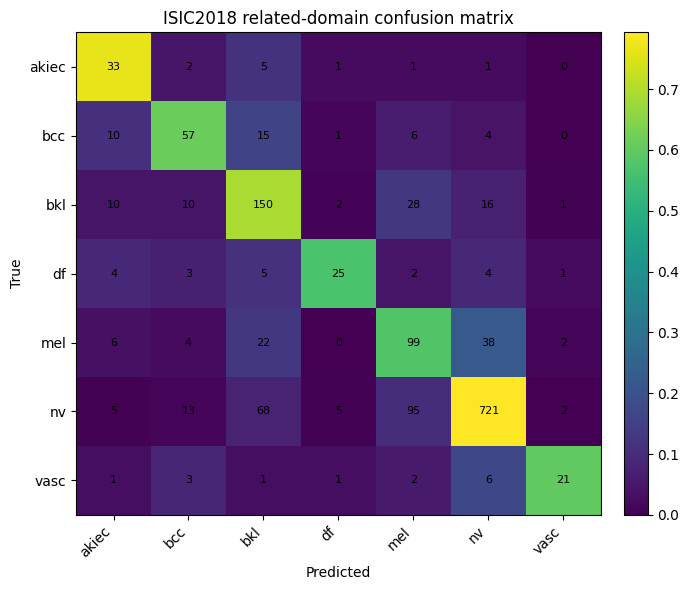

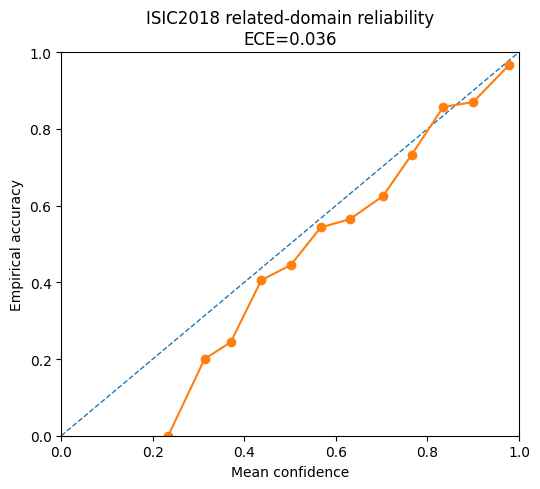

ISIC2018 result saved as related-domain robustness, not independent external validation.


In [43]:
# --- Evaluate related-domain ISIC2018 Task 3 if available ---

if model_eval is not None and external_isic2018_df is not None and len(external_isic2018_df) > 0:
    X_meta_ext = meta_pre.transform(external_isic2018_df)
    ext_ds = make_tf_dataset(
        external_isic2018_df, X_meta_ext,
        training=False, shuffle=False,
        use_metadata=model_uses_metadata(model_eval)
    )
    ext_logits, y_ext = collect_logits(model_eval, ext_ds)
    # Use temperature fitted on HAM10000 validation set, not external/related-domain labels.
    ext_probs = softmax_np(ext_logits, temperature=T if "T" in globals() else 1.0)
    ext_metrics = evaluate_probs(y_ext, ext_probs, prefix="isic2018_related_domain_")
    display(pd.DataFrame([ext_metrics]).T.rename(columns={0: "value"}))
    pd.DataFrame([ext_metrics]).to_csv(RESULT_DIR / "isic2018_related_domain_metrics.csv", index=False)
    plot_confusion(y_ext, ext_probs, FIG_DIR / "isic2018_related_domain_confusion_matrix.png", "ISIC2018 related-domain confusion matrix")
    plot_reliability(y_ext, ext_probs, FIG_DIR / "isic2018_related_domain_reliability.png", "ISIC2018 related-domain reliability", CONFIG["n_bins_ece"])
    print("ISIC2018 result saved as related-domain robustness, not independent external validation.")
else:
    print("Related-domain ISIC2018 evaluation skipped.")


## 17. Stress testing for clinic-readiness

Stress testing checks whether small acquisition or preprocessing changes destabilise predictions. This is not a replacement for real external validation, but it is a useful reliability screen.

In [44]:
# --- Stress-test dataset construction ---
# Uses the same CPU-only Keras Sequence/PIL backend as the main evaluation pipeline.

def stress_transform_numpy(img, mode):
    """Apply light stress transforms to a float32 RGB image in 0-255 scale."""
    img_uint8 = np.clip(img, 0, 255).astype("uint8")
    im = Image.fromarray(img_uint8, mode="RGB")

    if mode == "none":
        return img.astype("float32")
    if mode == "brightness_up":
        im = ImageEnhance.Brightness(im).enhance(1.15)
    elif mode == "brightness_down":
        im = ImageEnhance.Brightness(im).enhance(0.85)
    elif mode == "contrast_up":
        im = ImageEnhance.Contrast(im).enhance(1.25)
    elif mode == "contrast_down":
        im = ImageEnhance.Contrast(im).enhance(0.75)
    elif mode == "jpeg_quality_40":
        import io
        buffer = io.BytesIO()
        im.save(buffer, format="JPEG", quality=40)
        buffer.seek(0)
        im = Image.open(buffer).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    elif mode == "central_crop_90":
        w, h = im.size
        cw, ch = int(w * 0.90), int(h * 0.90)
        left, top = (w - cw) // 2, (h - ch) // 2
        im = im.crop((left, top, left + cw, top + ch)).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    else:
        raise ValueError(mode)

    return np.asarray(im, dtype="float32")


class StressSequence(HAM10000Sequence):
    def __init__(self, *args, stress_mode="none", **kwargs):
        super().__init__(*args, **kwargs)
        self.stress_mode = stress_mode

    def __getitem__(self, batch_idx):
        start = batch_idx * self.batch_size
        end = min((batch_idx + 1) * self.batch_size, len(self.paths))
        batch_indexes = self.indexes[start:end]

        images = np.empty((len(batch_indexes), IMG_SIZE, IMG_SIZE, 3), dtype="float32")
        for j, idx in enumerate(batch_indexes):
            arr = load_image_numpy(self.paths[idx], training=False)
            images[j] = stress_transform_numpy(arr, self.stress_mode)

        y = self.labels[batch_indexes].astype("int32")
        if self.use_metadata:
            x = {"image": images, "metadata": self.X_meta[batch_indexes].astype("float32")}
        else:
            x = {"image": images}
        return x, y


def make_stress_dataset(df, X_meta, mode="none", max_images=None, use_metadata=False):
    if max_images is not None and len(df) > max_images:
        df_use = df.sample(max_images, random_state=CONFIG["seed"]).reset_index(drop=True)
        X_use = meta_pre.transform(df_use)
    else:
        df_use = df.reset_index(drop=True)
        X_use = X_meta

    ds = StressSequence(
        df=df_use,
        X_meta=X_use,
        batch_size=BATCH_SIZE,
        training=False,
        shuffle=False,
        use_metadata=use_metadata,
        include_sample_weight=False,
        seed=int(CONFIG["seed"]),
        stress_mode=mode,
    )
    return ds, df_use


if model_eval is not None and CONFIG["run_stress_tests"]:
    stress_modes = ["none", "brightness_up", "brightness_down", "contrast_up", "contrast_down", "jpeg_quality_40", "central_crop_90"]
    stress_rows = []
    for mode in stress_modes:
        ds_stress, df_stress = make_stress_dataset(
            test_df, X_meta_test, mode=mode,
            max_images=CONFIG["stress_test_max_images"],
            use_metadata=model_uses_metadata(model_eval)
        )
        logits_s, y_s = collect_logits(model_eval, ds_stress)
        probs_s = softmax_np(logits_s, temperature=T if "T" in globals() else 1.0)
        m = evaluate_probs(y_s, probs_s, prefix="")
        m["stress_mode"] = mode
        m["n"] = len(y_s)
        stress_rows.append(m)
        print(mode, m["balanced_accuracy"], m["macro_f1"], m["ece"])
    stress_df = pd.DataFrame(stress_rows)
    display(stress_df)
    stress_df.to_csv(RESULT_DIR / "stress_test_metrics.csv", index=False)
else:
    print("Stress tests skipped.")


none 0.6735159996427313 0.6292015542220467 0.037284257546067234
brightness_up 0.6935215049976081 0.6228349955479116 0.04180691069364549
brightness_down 0.6229496379719857 0.6098614721193589 0.04214151754975317
contrast_up 0.6539282145295536 0.6161942505861919 0.07045570129156113
contrast_down 0.6534617318588436 0.6011894714032773 0.04637258318066598
jpeg_quality_40 0.6352491521501281 0.6265801510105662 0.0310315124988556
central_crop_90 0.6991589168594226 0.6512137466036013 0.0332348082959652


,accuracy,balanced_accuracy,macro_f1,weighted_f1,macro_recall,brier,nll,ece,mce,ece_n_bins,ovr_roc_auc_macro,stress_mode,n
0,0.734,0.673516,0.629202,0.749299,0.673516,0.345854,0.653472,0.037284,0.244537,15,0.943002,none,1000
1,0.729,0.693522,0.622835,0.746710,0.693522,0.358656,0.689212,0.041807,0.247927,15,0.939838,brightness_up,1000
2,0.727,0.622950,0.609861,0.741710,0.622950,0.354947,0.674909,0.042142,0.743518,15,0.940176,brightness_down,1000
3,0.728,0.653928,0.616194,0.747702,0.653928,0.369195,0.682149,0.070456,0.254663,15,0.941270,contrast_up,1000
4,0.726,0.653462,0.601189,0.736588,0.653462,0.393019,0.772122,0.046373,0.264412,15,0.932498,contrast_down,1000
5,0.773,0.635249,0.626580,0.766669,0.635249,0.324325,0.641118,0.031032,0.255078,15,0.937084,jpeg_quality_40,1000
6,0.753,0.699159,0.651214,0.764809,0.699159,0.337514,0.636002,0.033235,0.112431,15,0.943627,central_crop_90,1000


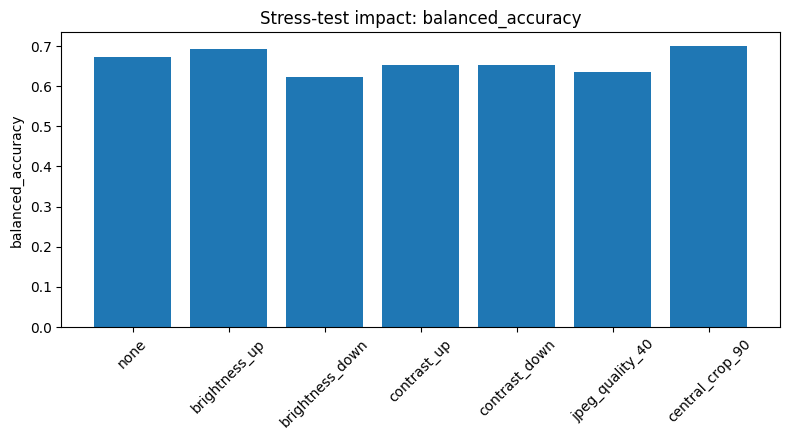

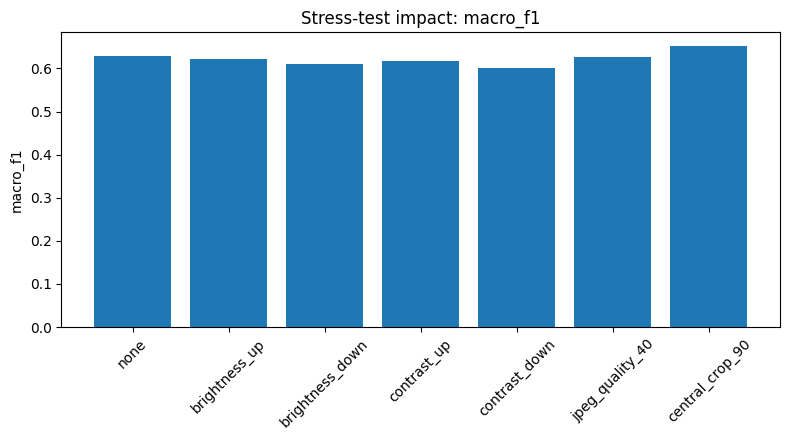

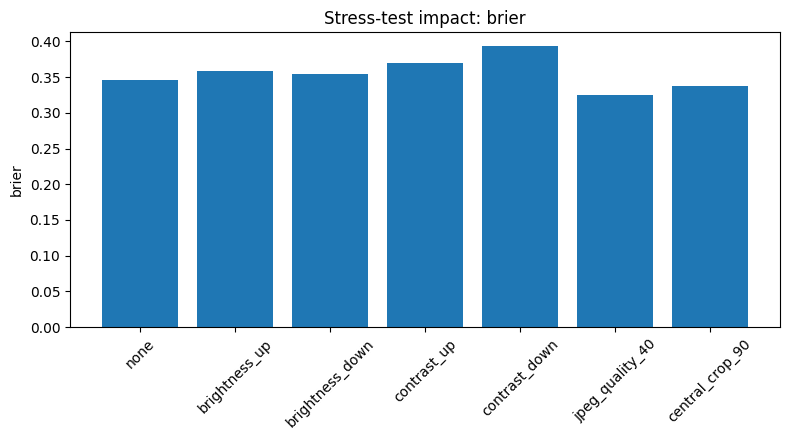

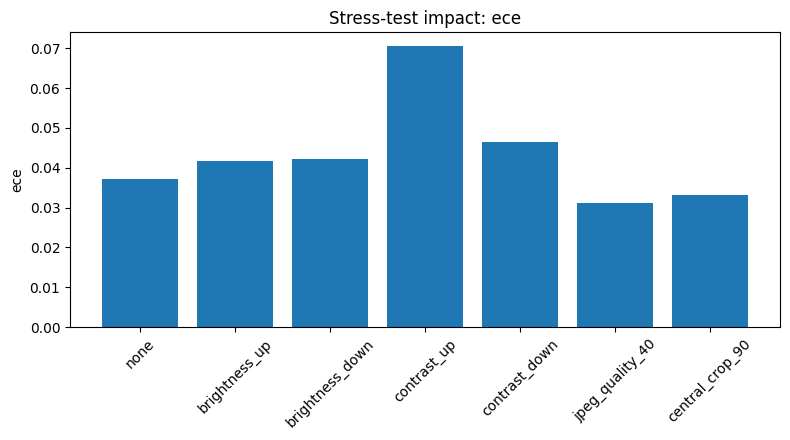

In [45]:
# --- Stress-test plot ---

if 'stress_df' in globals() and len(stress_df):
    metrics_to_plot = ["balanced_accuracy", "macro_f1", "brier", "ece"]
    for metric in metrics_to_plot:
        fig, ax = plt.subplots(figsize=(8, 4.5))
        ax.bar(stress_df["stress_mode"], stress_df[metric])
        ax.set_title(f"Stress-test impact: {metric}")
        ax.set_ylabel(metric)
        ax.tick_params(axis="x", rotation=45)
        fig.tight_layout()
        fig.savefig(FIG_DIR / f"stress_test_{metric}.png", dpi=200)
        plt.show()
else:
    print("No stress-test results to plot.")

## 18. Optional Grad-CAM for error and high-uncertainty review

Grad-CAM should be treated as a qualitative audit aid, not proof that the model has learned clinically causal features. Use it for selected true positives, false negatives, false positives, and high-uncertainty cases.

Grad-CAM layer: conv5_block3_3_conv
Case: ISIC_0031218 true: bkl pred: nv uncertainty: 0.7888644933700562


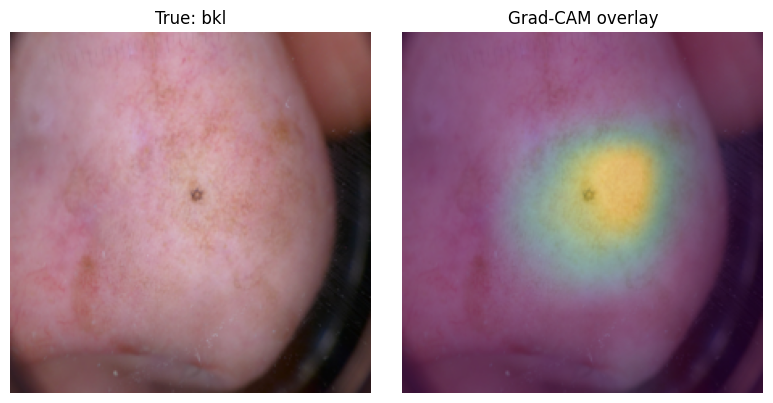

In [46]:
# --- Grad-CAM helper ---
# Qualitative only: use to audit selected high-uncertainty or misclassified cases.
# This cell is non-fatal. If the model architecture prevents Grad-CAM extraction, it records the issue and continues.

def find_last_conv_layer(model):
    last_name = None
    for layer in model.layers:
        if isinstance(layer, keras.Model):
            for sub in layer.layers:
                if isinstance(sub, layers.Conv2D):
                    last_name = sub.name
        elif isinstance(layer, layers.Conv2D):
            last_name = layer.name
    return last_name


def get_nested_layer(model, layer_name):
    for layer in model.layers:
        if layer.name == layer_name:
            return layer
        if isinstance(layer, keras.Model):
            try:
                return layer.get_layer(layer_name)
            except Exception:
                pass
    return None


def make_gradcam_heatmap(model, image_array, meta_array=None, class_index=None, conv_layer_name=None):
    if conv_layer_name is None:
        conv_layer_name = find_last_conv_layer(model)
    if conv_layer_name is None:
        raise ValueError("Could not find a Conv2D layer for Grad-CAM.")

    target_layer = get_nested_layer(model, conv_layer_name)
    if target_layer is None:
        raise ValueError(f"Layer {conv_layer_name} not found.")

    if model_uses_metadata(model):
        model_inputs = {"image": image_array, "metadata": meta_array}
    else:
        model_inputs = {"image": image_array}

    grad_model = keras.Model(model.inputs, [target_layer.output, model.output])
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(model_inputs)
        if class_index is None:
            class_index = tf.argmax(predictions[0])
        class_channel = predictions[:, class_index]

    grads = tape.gradient(class_channel, conv_outputs)
    if grads is None:
        raise RuntimeError("Gradients are None for the selected convolutional layer.")

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), conv_layer_name


def load_single_for_gradcam(row):
    img = load_image_numpy(row["image_path"], training=False)
    img_batch = np.expand_dims(img, axis=0).astype("float32")
    meta_vec = meta_pre.transform(pd.DataFrame([row]))
    return img_batch, meta_vec


RUN_GRADCAM_EXAMPLE = CONFIG["run_gradcam_example"]

if model_eval is not None and RUN_GRADCAM_EXAMPLE:
    try:
        pred_test = test_probs_temp.argmax(axis=1)
        uncertainty = 1 - test_probs_temp.max(axis=1)

        mis = np.where(pred_test != y_test)[0]
        if len(mis) > 0:
            candidate_idx = mis[np.argmax(uncertainty[mis])]
        else:
            candidate_idx = int(np.argmax(uncertainty))

        row = test_df.iloc[candidate_idx]
        img_batch, meta_vec = load_single_for_gradcam(row)
        heatmap, conv_name = make_gradcam_heatmap(model_eval, img_batch, meta_vec)
        print("Grad-CAM layer:", conv_name)
        print("Case:", row["image_id"], "true:", row["dx"], "pred:", CLASS_NAMES[pred_test[candidate_idx]], "uncertainty:", float(uncertainty[candidate_idx]))

        fig, ax = plt.subplots(1, 2, figsize=(8, 4))
        ax[0].imshow(img_batch[0].astype("uint8"))
        ax[0].set_title(f"True: {row['dx']}")
        ax[0].axis("off")

        heat = Image.fromarray(np.uint8(255 * heatmap)).resize((IMG_SIZE, IMG_SIZE))
        ax[1].imshow(img_batch[0].astype("uint8"))
        ax[1].imshow(heat, alpha=0.4)
        ax[1].set_title("Grad-CAM overlay")
        ax[1].axis("off")

        fig.tight_layout()
        fig.savefig(FIG_DIR / "gradcam_example.png", dpi=200)
        plt.show()

    except Exception as e:
        msg = f"Grad-CAM could not be generated for this architecture/session: {repr(e)}"
        print(msg)
        (RESULT_DIR / "gradcam_status.txt").write_text(msg)
else:
    print("Grad-CAM skipped. Set CONFIG['run_gradcam_example']=True for qualitative review.")


## 19. Optional TFLite export and deployment-cost reporting

Compression should only be done after choosing a final model. Report model size, inference latency, and any performance drop. Do not quantize every experimental model.

In [47]:
# --- Optional TFLite export: safer image-only wrapper ---

if model_eval is not None and CONFIG["run_tflite_export"]:
    try:
        if model_uses_metadata(model_eval):
            raise ValueError(
                "TFLite export wrapper currently supports image-only models. "
                "Skip export or implement a two-input signature for multimodal export."
            )

        export_dir = MODEL_DIR / "tflite_export"
        export_dir.mkdir(exist_ok=True, parents=True)

        image_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
        logits = model_eval({"image": image_input}, training=False)
        export_model = keras.Model(inputs=image_input, outputs=logits, name="image_only_tflite_export_wrapper")

        saved_model_dir = export_dir / "saved_model_image_only"
        if saved_model_dir.exists():
            shutil.rmtree(saved_model_dir)

        export_model.export(str(saved_model_dir))

        converter = tf.lite.TFLiteConverter.from_saved_model(str(saved_model_dir))
        converter.optimizations = [tf.lite.Optimize.DEFAULT]

        tflite_model = converter.convert()
        tflite_path = export_dir / "model_dynamic_range_quantized_image_only.tflite"
        tflite_path.write_bytes(tflite_model)

        deployment_row = {
            "tflite_path": str(tflite_path),
            "tflite_size_mb": round(tflite_path.stat().st_size / 1e6, 3),
            "selected_model_path": str(selected_model_path) if "selected_model_path" in globals() else "",
            "export_scope": "image_only_dynamic_range_quantization",
            "status": "success",
        }

        pd.DataFrame([deployment_row]).to_csv(
            RESULT_DIR / "deployment_export_summary.csv",
            index=False,
        )

        (RESULT_DIR / "tflite_export_status.txt").write_text(
            "success: image-only dynamic range quantized TFLite export completed\n"
            f"path: {tflite_path}\n"
            f"size_mb: {deployment_row['tflite_size_mb']}\n"
        )

        print("Saved TFLite model:", tflite_path)
        print("Size MB:", deployment_row["tflite_size_mb"])

    except Exception as e:
        msg = f"TFLite export failed non-fatally: {repr(e)}"
        print(msg)
        (RESULT_DIR / "tflite_export_status.txt").write_text(msg)
else:
    print("TFLite export skipped.")


Saved artifact at '/content/drive/MyDrive/ham10000_trustworthy_ai/models/tflite_export/saved_model_image_only'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 7), dtype=tf.float32, name=None)
Captures:
  134161002954832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134161002970576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134161002969808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134161002957520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134161002970000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134161002970384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134161002959056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134161002969424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134161002970192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134161002958864: 

In [48]:
# --- Methodological deployment verification ---
# This cell checks that the critical publication-safety fixes are active in the notebook run.

verification = {
    "dx_type_excluded_from_predictive_metadata": "dx_type" not in (META_CATEGORICAL_COLS + META_NUMERIC_COLS),
    "dx_type_available_for_subgroup_analysis": "dx_type" in SUBGROUP_VARIABLES,
    "primary_selection_image_only": CONFIG.get("main_model_selection_image_only", True),
    "multimodal_excluded_from_primary_selection": not CONFIG.get("include_multimodal_in_model_selection", False),
    "final_selected_seed_confirmation_enabled": CONFIG.get("run_final_selected_seed_confirmation", False),
    "isic2018_framed_as_related_domain": True,
    "tflite_export_image_only_wrapper": True,
    "deployment_feasibility_not_claimed_from_export_alone": True,
}

if "selective_summary" in globals() and isinstance(selective_summary, pd.DataFrame) and "auto_sensitivity_for_class" in selective_summary.columns:
    verification["selective_sensitivity_bounded_by_1"] = selective_summary["auto_sensitivity_for_class"].dropna().le(1.0 + 1e-9).all()
else:
    verification["selective_sensitivity_bounded_by_1"] = "not_yet_run"

if "mc_summary" in globals() and isinstance(mc_summary, pd.DataFrame) and "auto_sensitivity_for_class" in mc_summary.columns:
    verification["mc_selective_sensitivity_bounded_by_1"] = mc_summary["auto_sensitivity_for_class"].dropna().le(1.0 + 1e-9).all()
else:
    verification["mc_selective_sensitivity_bounded_by_1"] = "not_yet_run"

verification["validation_chosen_referral_threshold_exported"] = (RESULT_DIR / "selective_referral_threshold_policy.json").exists()
verification["cross_dataset_overlap_summary_exported"] = (RESULT_DIR / "reviewer_cross_dataset_overlap_summary.csv").exists()
verification["tflite_postquantization_performance_exported"] = (RESULT_DIR / "reviewer_tflite_postquantization_performance.csv").exists()

verification_df = pd.DataFrame([
    {"check": k, "status": v} for k, v in verification.items()
])

display(verification_df)
verification_df.to_csv(RESULT_DIR / "methodological_deployment_verification.csv", index=False)

assert verification["dx_type_excluded_from_predictive_metadata"] is True
assert verification["dx_type_available_for_subgroup_analysis"] is True
assert verification["primary_selection_image_only"] is True
assert verification["multimodal_excluded_from_primary_selection"] is True
assert verification["final_selected_seed_confirmation_enabled"] is True
assert verification["isic2018_framed_as_related_domain"] is True
assert verification["deployment_feasibility_not_claimed_from_export_alone"] is True

print("Methodological deployment verification passed.")


,check,status
0,dx_type_excluded_from_predictive_metadata,True
1,dx_type_available_for_subgroup_analysis,True
2,primary_selection_image_only,True
3,multimodal_excluded_from_primary_selection,True
4,final_selected_seed_confirmation_enabled,True
5,isic2018_framed_as_related_domain,True
6,tflite_export_image_only_wrapper,True
7,deployment_feasibility_not_claimed_from_export...,True
8,selective_sensitivity_bounded_by_1,True
9,mc_selective_sensitivity_bounded_by_1,True


Methodological deployment verification passed.


## 20. Generate a reproducibility manifest and paper-ready result index

This final cell collects the key tables and figures created by the notebook. It is useful for writing the journal manuscript and for checking that every claim in the paper maps to a file output.

In [49]:
# --- Manifest of outputs ---

manifest = {
    "created_at": datetime.now().isoformat(),
    "work_dir": str(WORK_DIR),
    "config": CONFIG,
    "data_files": {
        "clean_metadata": str(clean_metadata_path),
        "split_all": str(SPLIT_DIR / "ham10000_lesion_level_split_all.csv"),
    },
    "result_files": sorted([str(p) for p in RESULT_DIR.glob("*")]),
    "figure_files": sorted([str(p) for p in FIG_DIR.glob("*")]),
    "model_files": sorted([str(p) for p in MODEL_DIR.rglob("*") if p.is_file()])[:200],
}
with open(WORK_DIR / "manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print("Manifest saved:", WORK_DIR / "manifest.json")
print("Figures:")
for p in manifest["figure_files"]:
    print(" -", p)
print("Results:")
for p in manifest["result_files"]:
    print(" -", p)

Manifest saved: /content/drive/MyDrive/ham10000_trustworthy_ai/manifest.json
Figures:
 - /content/drive/MyDrive/ham10000_trustworthy_ai/figures/class_distribution.png
 - /content/drive/MyDrive/ham10000_trustworthy_ai/figures/confusion_matrix_raw.png
 - /content/drive/MyDrive/ham10000_trustworthy_ai/figures/dx_type_distribution.png
 - /content/drive/MyDrive/ham10000_trustworthy_ai/figures/gradcam_example.png
 - /content/drive/MyDrive/ham10000_trustworthy_ai/figures/isic2018_related_domain_confusion_matrix.png
 - /content/drive/MyDrive/ham10000_trustworthy_ai/figures/isic2018_related_domain_reliability.png
 - /content/drive/MyDrive/ham10000_trustworthy_ai/figures/localization_distribution.png
 - /content/drive/MyDrive/ham10000_trustworthy_ai/figures/per_class_recall_raw.png
 - /content/drive/MyDrive/ham10000_trustworthy_ai/figures/referral_vs_melanoma_sensitivity.png
 - /content/drive/MyDrive/ham10000_trustworthy_ai/figures/reliability_raw.png
 - /content/drive/MyDrive/ham10000_trustwort

## 21. Suggested manuscript claim-to-output map

| Manuscript claim | Notebook output |
|---|---|
| HAM10000 is long-tailed and unsuitable for accuracy-only reporting | `class_distribution.csv`, `class_distribution.png` |
| Splitting was lesion-level and leakage-controlled | `ham10000_lesion_level_split_all.csv`, `reviewer_split_protocol_summary.json`, `reviewer_split_class_distribution.csv`, `reviewer_split_internal_overlap_checks.csv` |
| Training and preprocessing are reproducible | `reviewer_training_reproducibility_details.json`, `reviewer_class_weight_values.csv`, model `runtime.json`, model `history_*.csv`, `environment_log.json` |
| The final model was selected without test leakage | `model_selection_validation_only.csv` |
| The model was evaluated beyond accuracy | `test_metrics_raw.csv`, `test_metrics_temperature_scaled.csv`, `internal_test_temperature_scaled_per_class_precision_recall_f1.csv`, `internal_test_temperature_scaled_confusion_matrix_counts.csv` |
| Calibration was assessed with ECE binning, MCE, class-wise calibration, and uncertainty intervals | `reviewer_temperature_scaling_and_ece_definition.json`, `reviewer_global_ece_mce_summary.csv`, `reviewer_internal_*calibration*.csv`, `reviewer_internal_calibration_global_bootstrap_ci.csv`, `reviewer_internal_calibration_classwise_bootstrap_ci.csv` |
| Selective referral includes a practical validation-chosen operating point | `selective_referral_threshold_policy.json`, `selective_referral_worked_example.md`, `selective_referral_operating_point_validation_chosen.csv`, `selective_referral_operating_point_test_results.csv`, `selective_referral_summary.csv`, `risk_coverage_curves.png` |
| Melanoma-specific selective-referral behavior was audited | `reviewer_melanoma_selective_referral_counts.csv`, `referral_vs_melanoma_sensitivity.png` |
| Late-fusion metadata ablation was reported rather than only described | `multimodal_cleanmeta_test_metrics_temperature_scaled.csv` |
| MC Dropout was reported rather than only described | `mc_dropout_metrics.csv`, `mc_dropout_selective_summary.csv`, `mc_dropout_selective_curves.csv` |
| ISIC2018 was evaluated as related-domain robustness and leakage-screened | `isic2018_related_domain_subset_manifest.json`, `isic2018_related_domain_status.json`, `isic2018_related_domain_metrics.csv`, `reviewer_cross_dataset_overlap_summary.csv` |
| Internal subgroup performance/calibration gaps were assessed with denominators and CIs | `internal_subgroup_metrics_temperature_scaled.csv`, `internal_subgroup_class_counts.csv`, `subgroup_bootstrap_ci_temperature_scaled.csv`, `subgroup_selective_referral_fixed_coverage.csv`, `subgroup_sex_calibration_discrimination_note.md` |
| Clinic-readiness stress tests were presented as a complete metric table | `stress_test_metrics.csv`, stress-test figures |
| TFLite export was not treated as sufficient deployment evidence | `deployment_export_summary.csv`, `reviewer_tflite_equivalence_latency_memory_profile.csv`, `reviewer_tflite_postquantization_performance.csv`, `methodological_deployment_verification.csv` |
| Code and result availability package can be deposited in a DOI repository | `manifest.json`, `reviewer_editor_compliance_matrix.csv`, split files, result tables, model summaries, training histories, and this notebook |

## Manuscript wording cautions to carry into the revision

- Use the title **Calibrated Selective Referral for Skin Lesion AI on HAM10000** consistently in the tracking system, manuscript file, and cover letter.
- Replace independent “external validation” wording with “ISIC2018 related-domain robustness analysis” unless a genuinely independent cohort is added.
- State that AUROC can be high while macro-F1 and melanoma F1 remain modest because AUROC evaluates rank discrimination across thresholds, whereas F1 depends on a single operating threshold and is sensitive to class imbalance and false positives.
- State explicitly that low melanoma precision means model-predicted melanoma labels are not reliable enough for autonomous action and require clinician review.
- State that scalar temperature scaling corrects only global logit scale and may leave class-wise and subgroup calibration heterogeneity.
- State that no universal clinical ECE threshold is assumed. Any ECE threshold is a local validation target, not deployment clearance.
- State that TFLite export alone does not establish deployment feasibility; target-device latency, memory, numerical equivalence, post-quantization performance, workflow integration, and prospective clinical validation are required.

## References to justify the workflow in the manuscript

Use the research report's literature table to write the final reference list. The most directly used methods are:

- Tschandl et al. 2018 for HAM10000.
- Cassidy et al. 2022 and Abhishek et al. 2025 for data quality, duplicate images, and split leakage.
- Guo et al. 2017 for temperature scaling and neural-network calibration.
- Gal & Ghahramani 2016 and Lakshminarayanan et al. 2017 for MC Dropout and deep ensembles.
- El-Yaniv & Wiener 2010 and Geifman & El-Yaniv 2019 for selective classification / reject option.
- Mobiny et al. 2019 for risk-aware skin-lesion referral using uncertainty.
- Groh et al. 2021 and Daneshjou et al. 2022 for skin-tone and external fairness concerns.
- Young et al. 2021 for clinic-readiness stress testing.
- Thomas et al. 2023 and Krakowski et al. 2024 for real-world deployment and human-AI workflow framing.


In [50]:
# --- Export manuscript revision notes and code availability checklist ---

revision_notes = f"""
# Reviewer and editor revision notes

## Revised title
Calibrated Selective Referral for Skin Lesion AI on HAM10000

## Code availability statement template
The full analysis code, exact train/validation/test split files, configuration file, model-selection table, training histories, runtime logs, result tables, and figure-generation scripts are available at: [insert DOI repository link, e.g. Zenodo DOI]. The repository should include this notebook and/or equivalent scripts, `splits/`, `results/`, `figures/`, `config.json`, `manifest.json`, `reviewer_editor_compliance_matrix.csv`, and environment details.

## Cautious interpretation language
This model is evaluated as a triage-support candidate, not as an autonomous diagnostic system. High multiclass AUROC should not be interpreted as adequate clinical safety because macro-F1 and melanoma-specific F1/precision remain much lower at the selected operating threshold. Low melanoma precision means that predicted melanoma cases require clinician review and the selective-referral mechanism should be interpreted as a safety-oriented abstention aid.

## Calibration language
ECE is computed as top-label ECE using {CONFIG['n_bins_ece']} equal-width bins over [0, 1]. MCE is the maximum non-empty-bin absolute calibration gap. A single temperature parameter is fitted on validation logits only. This scalar correction may not remove class-wise or subgroup calibration heterogeneity.

## Related-domain robustness language
The ISIC2018 Task 3 test analysis uses the official ISIC2018_Task3_Test_Input.zip images and ISIC2018_Task3_Test_GroundTruth.zip labels if available. Because of overlap in acquisition ecosystem and challenge provenance with HAM10000, it should be called related-domain robustness rather than independent external validation.

## Deployment language
TFLite export is reported only as a technical conversion step. Deployment feasibility is not claimed unless latency, approximate memory, numerical equivalence, and post-quantization performance are reported and then validated on intended target hardware and in a clinical workflow.
""".strip()

(RESULT_DIR / "reviewer_manuscript_revision_notes.md").write_text(revision_notes)
print("Saved:", RESULT_DIR / "reviewer_manuscript_revision_notes.md")


Saved: /content/drive/MyDrive/ham10000_trustworthy_ai/results/reviewer_manuscript_revision_notes.md


# Reviewer-requested final exports

Run the following cells after the main workflow has produced `y_test`, `test_probs_temp`, `test_df_eval`, and, when available, `external_isic2018_df`, `y_ext`, and `ext_probs`. These cells add reviewer-requested tables for confusion matrices, class-wise calibration, maximum calibration error, melanoma-specific referral counts, cross-dataset duplicate checks, and optional TFLite equivalence/latency profiling.

In [51]:

# --- Reviewer export 1: class-wise metrics and confusion matrices ---
from sklearn.metrics import confusion_matrix

def export_confusion_and_classwise(y_true, probs, prefix, out_dir=RESULT_DIR, fig_dir=FIG_DIR):
    """Export class-wise metrics and a count confusion matrix for reviewer reporting."""
    pred = np.asarray(probs).argmax(axis=1)
    cm = confusion_matrix(y_true, pred, labels=np.arange(N_CLASSES))
    cm_df = pd.DataFrame(cm, index=[f"true_{c}" for c in CLASS_NAMES], columns=[f"pred_{c}" for c in CLASS_NAMES])
    cm_df.to_csv(out_dir / f"{prefix}_confusion_matrix_counts.csv")
    pct = per_class_table(y_true, probs)
    pct.to_csv(out_dir / f"{prefix}_per_class_precision_recall_f1.csv", index=False)

    fig, ax = plt.subplots(figsize=(7, 6))
    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    im = ax.imshow(cm_norm, aspect="auto")
    ax.set_xticks(np.arange(N_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
    ax.set_yticks(np.arange(N_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(prefix.replace("_", " ") + " confusion matrix")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=8)
    fig.tight_layout()
    fig.savefig(fig_dir / f"{prefix}_confusion_matrix_counts.png", dpi=220)
    plt.close(fig)
    return cm_df, pct

if "y_test" in globals() and "test_probs_temp" in globals():
    internal_cm_df, internal_pct_df = export_confusion_and_classwise(
        y_test, test_probs_temp, "internal_test_temperature_scaled"
    )
    display(internal_pct_df)
    display(internal_cm_df)
else:
    print("Internal test variables not found; run the main evaluation cells first.")

if "y_ext" in globals() and "ext_probs" in globals():
    isic_cm_df, isic_pct_df = export_confusion_and_classwise(
        y_ext, ext_probs, "isic2018_task3_related_domain"
    )
    display(isic_pct_df)
    display(isic_cm_df)
else:
    print("ISIC2018 variables not found; run external related-domain evaluation first if available.")


,class,support,recall,precision,f1
0,akiec,68,0.617647,0.461538,0.528302
1,bcc,85,0.552941,0.522222,0.537143
2,bkl,226,0.752212,0.561056,0.642722
3,df,28,0.500000,0.583333,0.538462
4,mel,219,0.547945,0.379747,0.448598
5,nv,1336,0.794910,0.942325,0.862363
6,vasc,35,0.942857,0.717391,0.814815


,pred_akiec,pred_bcc,pred_bkl,pred_df,pred_mel,pred_nv,pred_vasc
true_akiec,42,8,11,3,4,0,0
true_bcc,10,47,10,0,2,9,7
true_bkl,15,10,170,0,21,10,0
true_df,4,2,2,14,0,6,0
true_mel,13,7,34,1,120,39,5
true_nv,7,15,76,6,169,1062,1
true_vasc,0,1,0,0,0,1,33


,class,support,recall,precision,f1
0,akiec,43,0.767442,0.478261,0.589286
1,bcc,93,0.612903,0.619565,0.616216
2,bkl,217,0.691244,0.563910,0.621118
3,df,44,0.568182,0.714286,0.632911
4,mel,171,0.578947,0.424893,0.490099
5,nv,909,0.793179,0.912658,0.848735
6,vasc,35,0.600000,0.777778,0.677419


,pred_akiec,pred_bcc,pred_bkl,pred_df,pred_mel,pred_nv,pred_vasc
true_akiec,33,2,5,1,1,1,0
true_bcc,10,57,15,1,6,4,0
true_bkl,10,10,150,2,28,16,1
true_df,4,3,5,25,2,4,1
true_mel,6,4,22,0,99,38,2
true_nv,5,13,68,5,95,721,2
true_vasc,1,3,1,1,2,6,21


In [52]:

# --- Reviewer export 2: ECE bins, MCE, class-wise calibration, and calibration CIs ---

def calibration_bin_table(y_true, probs, n_bins=15, prefix=""):
    """Top-label calibration using maximum predicted probability and equal-width bins over [0, 1]."""
    y_true = np.asarray(y_true)
    probs = np.asarray(probs)
    conf = probs.max(axis=1)
    pred = probs.argmax(axis=1)
    correct = (pred == y_true).astype(float)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    rows = []
    ece = 0.0
    mce = 0.0
    n = len(y_true)
    for b in range(n_bins):
        lo, hi = edges[b], edges[b + 1]
        if b == n_bins - 1:
            mask = (conf >= lo) & (conf <= hi)
        else:
            mask = (conf >= lo) & (conf < hi)
        count = int(mask.sum())
        if count:
            acc = float(correct[mask].mean())
            avg_conf = float(conf[mask].mean())
            gap = abs(acc - avg_conf)
        else:
            acc = np.nan; avg_conf = np.nan; gap = 0.0
        weight = count / max(n, 1)
        ece += weight * gap
        mce = max(mce, gap)
        rows.append({
            "prefix": prefix,
            "bin": b,
            "bin_low": lo,
            "bin_high": hi,
            "count": count,
            "weight": weight,
            "accuracy": acc,
            "mean_confidence": avg_conf,
            "abs_gap": gap,
        })
    return pd.DataFrame(rows), {"prefix": prefix, "ece": ece, "mce": mce, "n_bins": n_bins, "n": n}


def classwise_one_vs_rest_calibration(y_true, probs, n_bins=15, prefix=""):
    """One-vs-rest class-wise calibration; useful for identifying heterogeneous calibration."""
    y_true = np.asarray(y_true)
    probs = np.asarray(probs)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    summary_rows = []
    bin_rows = []
    n = len(y_true)
    for k, cls in enumerate(CLASS_NAMES):
        y_bin = (y_true == k).astype(float)
        p = probs[:, k]
        ece = 0.0; mce = 0.0
        for b in range(n_bins):
            lo, hi = edges[b], edges[b + 1]
            if b == n_bins - 1:
                mask = (p >= lo) & (p <= hi)
            else:
                mask = (p >= lo) & (p < hi)
            count = int(mask.sum())
            if count:
                emp = float(y_bin[mask].mean())
                avg_p = float(p[mask].mean())
                gap = abs(emp - avg_p)
            else:
                emp = np.nan; avg_p = np.nan; gap = 0.0
            weight = count / max(n, 1)
            ece += weight * gap
            mce = max(mce, gap)
            bin_rows.append({
                "prefix": prefix,
                "class": cls,
                "bin": b,
                "bin_low": lo,
                "bin_high": hi,
                "count": count,
                "empirical_frequency": emp,
                "mean_predicted_probability": avg_p,
                "abs_gap": gap,
            })
        summary_rows.append({
            "prefix": prefix,
            "class": cls,
            "support": int((y_true == k).sum()),
            "classwise_ece": ece,
            "classwise_mce": mce,
            "n_bins": n_bins,
        })
    return pd.DataFrame(summary_rows), pd.DataFrame(bin_rows)


def bootstrap_calibration_ci(y_true, probs, n_reps=1000, seed=42, prefix=""):
    """Bootstrap CIs for global ECE/MCE and class-wise ECE/MCE."""
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    probs = np.asarray(probs)
    n = len(y_true)
    global_rows = []
    class_rows = []
    for rep in range(int(n_reps)):
        idx = rng.integers(0, n, size=n)
        try:
            _, g = calibration_bin_table(y_true[idx], probs[idx], CONFIG["n_bins_ece"], prefix=prefix)
            g["rep"] = rep
            global_rows.append(g)
            cw, _ = classwise_one_vs_rest_calibration(y_true[idx], probs[idx], CONFIG["n_bins_ece"], prefix=prefix)
            cw["rep"] = rep
            class_rows.append(cw)
        except Exception:
            continue

    global_boot = pd.DataFrame(global_rows)
    class_boot = pd.concat(class_rows, ignore_index=True) if class_rows else pd.DataFrame()

    global_summary = []
    for metric in ["ece", "mce"]:
        vals = global_boot[metric].dropna().values if metric in global_boot else np.array([])
        if len(vals):
            global_summary.append({
                "prefix": prefix,
                "metric": metric,
                "mean_bootstrap": float(np.mean(vals)),
                "lower_95": float(np.percentile(vals, 2.5)),
                "upper_95": float(np.percentile(vals, 97.5)),
                "bootstrap_reps_successful": int(len(vals)),
            })

    class_summary = []
    if len(class_boot):
        for cls, gcls in class_boot.groupby("class"):
            for metric in ["classwise_ece", "classwise_mce"]:
                vals = gcls[metric].dropna().values
                if len(vals):
                    class_summary.append({
                        "prefix": prefix,
                        "class": cls,
                        "metric": metric,
                        "mean_bootstrap": float(np.mean(vals)),
                        "lower_95": float(np.percentile(vals, 2.5)),
                        "upper_95": float(np.percentile(vals, 97.5)),
                        "bootstrap_reps_successful": int(len(vals)),
                    })

    return pd.DataFrame(global_summary), pd.DataFrame(class_summary), global_boot, class_boot


calibration_exports = []
if "y_test" in globals() and "test_probs_raw" in globals():
    raw_bins, raw_summary = calibration_bin_table(y_test, test_probs_raw, CONFIG["n_bins_ece"], "internal_raw")
    raw_bins.to_csv(RESULT_DIR / "reviewer_internal_raw_calibration_bins.csv", index=False)
    calibration_exports.append(raw_summary)
if "y_test" in globals() and "test_probs_temp" in globals():
    temp_bins, temp_summary = calibration_bin_table(y_test, test_probs_temp, CONFIG["n_bins_ece"], "internal_temperature_scaled")
    temp_bins.to_csv(RESULT_DIR / "reviewer_internal_temperature_scaled_calibration_bins.csv", index=False)
    calibration_exports.append(temp_summary)
    cw_sum, cw_bins = classwise_one_vs_rest_calibration(y_test, test_probs_temp, CONFIG["n_bins_ece"], "internal_temperature_scaled")
    cw_sum.to_csv(RESULT_DIR / "reviewer_internal_classwise_calibration_summary.csv", index=False)
    cw_bins.to_csv(RESULT_DIR / "reviewer_internal_classwise_calibration_bins.csv", index=False)
    display(cw_sum)

    cal_ci_global, cal_ci_class, cal_boot_global, cal_boot_class = bootstrap_calibration_ci(
        y_test,
        test_probs_temp,
        n_reps=CONFIG.get("calibration_bootstrap_reps", CONFIG.get("bootstrap_reps", 1000)),
        seed=CONFIG["seed"],
        prefix="internal_temperature_scaled",
    )
    cal_ci_global.to_csv(RESULT_DIR / "reviewer_internal_calibration_global_bootstrap_ci.csv", index=False)
    cal_ci_class.to_csv(RESULT_DIR / "reviewer_internal_calibration_classwise_bootstrap_ci.csv", index=False)
    cal_boot_global.to_csv(RESULT_DIR / "reviewer_internal_calibration_global_bootstrap_raw.csv", index=False)
    cal_boot_class.to_csv(RESULT_DIR / "reviewer_internal_calibration_classwise_bootstrap_raw.csv", index=False)
    display(cal_ci_global)
if "y_ext" in globals() and "ext_probs" in globals():
    ext_bins, ext_summary = calibration_bin_table(y_ext, ext_probs, CONFIG["n_bins_ece"], "isic2018_task3_related_domain")
    ext_bins.to_csv(RESULT_DIR / "reviewer_isic2018_related_domain_calibration_bins.csv", index=False)
    calibration_exports.append(ext_summary)
    ext_cw_sum, ext_cw_bins = classwise_one_vs_rest_calibration(y_ext, ext_probs, CONFIG["n_bins_ece"], "isic2018_task3_related_domain")
    ext_cw_sum.to_csv(RESULT_DIR / "reviewer_isic2018_related_domain_classwise_calibration_summary.csv", index=False)
    ext_cw_bins.to_csv(RESULT_DIR / "reviewer_isic2018_related_domain_classwise_calibration_bins.csv", index=False)

    ext_cal_ci_global, ext_cal_ci_class, ext_cal_boot_global, ext_cal_boot_class = bootstrap_calibration_ci(
        y_ext,
        ext_probs,
        n_reps=CONFIG.get("calibration_bootstrap_reps", CONFIG.get("bootstrap_reps", 1000)),
        seed=CONFIG["seed"] + 2018,
        prefix="isic2018_task3_related_domain",
    )
    ext_cal_ci_global.to_csv(RESULT_DIR / "reviewer_isic2018_related_domain_calibration_global_bootstrap_ci.csv", index=False)
    ext_cal_ci_class.to_csv(RESULT_DIR / "reviewer_isic2018_related_domain_calibration_classwise_bootstrap_ci.csv", index=False)
    ext_cal_boot_global.to_csv(RESULT_DIR / "reviewer_isic2018_related_domain_calibration_global_bootstrap_raw.csv", index=False)
    ext_cal_boot_class.to_csv(RESULT_DIR / "reviewer_isic2018_related_domain_calibration_classwise_bootstrap_raw.csv", index=False)
    display(ext_cw_sum)

if calibration_exports:
    cal_summary_df = pd.DataFrame(calibration_exports)
    cal_summary_df.to_csv(RESULT_DIR / "reviewer_global_ece_mce_summary.csv", index=False)
    display(cal_summary_df)
else:
    print("No calibration variables found; run the main evaluation cells first.")


,prefix,class,support,classwise_ece,classwise_mce,n_bins
0,internal_temperature_scaled,akiec,68,0.015974,0.348526,15
1,internal_temperature_scaled,bcc,85,0.014033,0.385834,15
2,internal_temperature_scaled,bkl,226,0.050115,0.301177,15
3,internal_temperature_scaled,df,28,0.005711,0.443314,15
4,internal_temperature_scaled,mel,219,0.061405,0.420647,15
5,internal_temperature_scaled,nv,1336,0.137874,0.448723,15
6,internal_temperature_scaled,vasc,35,0.007154,0.778795,15


,prefix,metric,mean_bootstrap,lower_95,upper_95,bootstrap_reps_successful
0,internal_temperature_scaled,ece,0.040934,0.028900,0.055621,1000
1,internal_temperature_scaled,mce,0.250874,0.211135,0.322392,1000


,prefix,class,support,classwise_ece,classwise_mce,n_bins
0,isic2018_task3_related_domain,akiec,43,0.023686,0.429794,15
1,isic2018_task3_related_domain,bcc,93,0.018692,0.302885,15
2,isic2018_task3_related_domain,bkl,217,0.041594,0.280281,15
3,isic2018_task3_related_domain,df,44,0.006797,0.623629,15
4,isic2018_task3_related_domain,mel,171,0.059483,0.406847,15
5,isic2018_task3_related_domain,nv,909,0.111294,0.430039,15
6,isic2018_task3_related_domain,vasc,35,0.010230,0.484261,15


,prefix,ece,mce,n_bins,n
0,internal_raw,0.111334,0.312631,15,1997
1,internal_temperature_scaled,0.034378,0.248575,15,1997
2,isic2018_task3_related_domain,0.035691,0.233737,15,1512


In [53]:

# --- Reviewer export 3: melanoma-specific selective referral counts ---

def entropy_scores(probs):
    p = np.clip(np.asarray(probs), 1e-12, 1.0)
    return -np.sum(p * np.log(p), axis=1)


def negative_margin_scores(probs):
    p = np.asarray(probs)
    top2 = np.sort(p, axis=1)[:, -2:]
    return -(top2[:, 1] - top2[:, 0])


def melanoma_referral_counts(y_true, probs, score_values, score_name, target_coverages=(0.95, 0.90, 0.80, 0.70, 0.50)):
    y_true = np.asarray(y_true)
    probs = np.asarray(probs)
    pred = probs.argmax(axis=1)
    mel_idx = CLASS_NAMES.index("mel")
    order = np.argsort(score_values)  # lower uncertainty retained first
    rows = []
    n = len(y_true)
    for cov in target_coverages:
        k = int(round(cov * n))
        k = max(1, min(n, k))
        retained = np.zeros(n, dtype=bool)
        retained[order[:k]] = True
        uncertainty_threshold = float(np.asarray(score_values)[order[k - 1]])
        mel_mask = (y_true == mel_idx)
        mel_auto = mel_mask & retained
        mel_referred = mel_mask & (~retained)
        mel_correct = mel_auto & (pred == mel_idx)
        mel_wrong = mel_auto & (pred != mel_idx)
        auto_correct_all = retained & (pred == y_true)
        rows.append({
            "score": score_name,
            "target_coverage": cov,
            "uncertainty_threshold": uncertainty_threshold,
            "threshold_direction": "auto-classify if score <= uncertainty_threshold",
            "actual_coverage": retained.mean(),
            "referral_rate": 1 - retained.mean(),
            "n_total": n,
            "n_auto_classified": int(retained.sum()),
            "n_referred": int((~retained).sum()),
            "selective_risk": 1 - float(auto_correct_all.sum() / max(retained.sum(), 1)),
            "n_melanoma_total": int(mel_mask.sum()),
            "n_melanoma_auto_total": int(mel_auto.sum()),
            "n_melanoma_auto_correct": int(mel_correct.sum()),
            "n_melanoma_auto_wrong": int(mel_wrong.sum()),
            "n_melanoma_referred": int(mel_referred.sum()),
            "melanoma_auto_recall": float(mel_correct.sum() / max(mel_mask.sum(), 1)),
            "melanoma_coverage": float(mel_auto.sum() / max(mel_mask.sum(), 1)),
        })
    return pd.DataFrame(rows)

if "y_test" in globals() and "test_probs_temp" in globals():
    p = test_probs_temp
    score_dict = {
        "maxprob_uncertainty": 1 - p.max(axis=1),
        "entropy": entropy_scores(p),
        "negative_margin": negative_margin_scores(p),
    }
    mel_tables = []
    for name, vals in score_dict.items():
        mel_tables.append(melanoma_referral_counts(y_test, p, vals, name))
    melanoma_referral_df = pd.concat(mel_tables, ignore_index=True)
    melanoma_referral_df.to_csv(RESULT_DIR / "reviewer_melanoma_selective_referral_counts.csv", index=False)
    display(melanoma_referral_df)
else:
    print("Internal test probabilities not found; run temperature-scaled evaluation first.")


,score,target_coverage,uncertainty_threshold,threshold_direction,actual_coverage,referral_rate,n_total,n_auto_classified,n_referred,selective_risk,n_melanoma_total,n_melanoma_auto_total,n_melanoma_auto_correct,n_melanoma_auto_wrong,n_melanoma_referred,melanoma_auto_recall,melanoma_coverage
0,maxprob_uncertainty,0.95,0.574176,auto-classify if score <= uncertainty_threshold,0.949925,0.050075,1997,1897,100,0.231945,219,203,117,86,16,0.534247,0.926941
1,maxprob_uncertainty,0.90,0.527060,auto-classify if score <= uncertainty_threshold,0.899850,0.100150,1997,1797,200,0.218141,219,186,107,79,33,0.488584,0.849315
2,maxprob_uncertainty,0.80,0.442980,auto-classify if score <= uncertainty_threshold,0.800200,0.199800,1997,1598,399,0.174593,219,142,87,55,77,0.397260,0.648402
3,maxprob_uncertainty,0.70,0.364899,auto-classify if score <= uncertainty_threshold,0.700050,0.299950,1997,1398,599,0.135193,219,118,78,40,101,0.356164,0.538813
4,maxprob_uncertainty,0.50,0.173311,auto-classify if score <= uncertainty_threshold,0.499750,0.500250,1997,998,999,0.052104,219,49,42,7,170,0.191781,0.223744
5,entropy,0.95,1.350462,auto-classify if score <= uncertainty_threshold,0.949925,0.050075,1997,1897,100,0.236162,219,203,115,88,16,0.525114,0.926941
6,entropy,0.90,1.220270,auto-classify if score <= uncertainty_threshold,0.899850,0.100150,1997,1797,200,0.218141,219,185,109,76,34,0.497717,0.844749
7,entropy,0.80,1.044017,auto-classify if score <= uncertainty_threshold,0.800200,0.199800,1997,1598,399,0.179599,219,148,95,53,71,0.433790,0.675799
8,entropy,0.70,0.872988,auto-classify if score <= uncertainty_threshold,0.700050,0.299950,1997,1398,599,0.144492,219,113,78,35,106,0.356164,0.515982
9,entropy,0.50,0.579669,auto-classify if score <= uncertainty_threshold,0.499750,0.500250,1997,998,999,0.052104,219,51,44,7,168,0.200913,0.232877


In [54]:

# --- Reviewer export 4: exact and perceptual overlap checks between HAM10000 and ISIC2018 ---
# Conservative cross-dataset leakage screen.
# Reports image_id overlap, lesion_id overlap when genuine lesion IDs are available,
# exact SHA256 file-hash overlap, and simple 64-bit dHash candidate near-duplicates.
# dHash candidates are flags for manual review, not proof.
import hashlib


def sha256_file(path, block_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(block_size), b""):
            h.update(block)
    return h.hexdigest()


def dhash64(path, hash_size=8):
    im = Image.open(path).convert("L").resize((hash_size + 1, hash_size), Image.Resampling.LANCZOS)
    arr = np.asarray(im)
    diff = arr[:, 1:] > arr[:, :-1]
    value = 0
    for bit in diff.flatten():
        value = (value << 1) | int(bit)
    return int(value)


def hamming64(a, b):
    return int((int(a) ^ int(b)).bit_count())


def prepare_overlap_paths(df, source_name):
    out = df.copy()
    if "lesion_id" not in out.columns:
        out["lesion_id"] = np.nan
    required = ["image_id", "lesion_id", "image_path"]
    missing = [c for c in required if c not in out.columns]
    if missing:
        raise ValueError(f"{source_name} overlap dataframe is missing columns: {missing}")
    out = out[required].copy()
    out["image_id"] = out["image_id"].astype(str)
    out["image_path"] = out["image_path"].astype(str)
    out = out[out["image_path"].map(lambda p: bool(p) and Path(p).exists())].copy()
    return out.reset_index(drop=True)


ham_metadata_source = None
if "metadata_df" in globals():
    ham_metadata_source = metadata_df
elif "meta" in globals():
    ham_metadata_source = meta

if "external_isic2018_df" in globals() and external_isic2018_df is not None and ham_metadata_source is not None:
    ham_df_overlap = ham_metadata_source.copy()
    ext_df_overlap = external_isic2018_df.copy()

    ham_image_ids = set(ham_df_overlap["image_id"].astype(str))
    ext_image_ids = set(ext_df_overlap["image_id"].astype(str))
    id_overlap = sorted(ham_image_ids & ext_image_ids)

    lesion_id_source = getattr(external_isic2018_df, "attrs", {}).get("lesion_id_source", "unknown")
    ext_has_true_lesion_ids = (
        "lesion_id" in ext_df_overlap.columns
        and ext_df_overlap["lesion_id"].notna().any()
        and lesion_id_source != "not_available_in_groundtruth"
    )
    ham_has_lesion_ids = "lesion_id" in ham_df_overlap.columns and ham_df_overlap["lesion_id"].notna().any()
    lesion_overlap_assessable = bool(ham_has_lesion_ids and ext_has_true_lesion_ids)

    lesion_overlap = []
    if lesion_overlap_assessable:
        ham_lesion_ids = set(ham_df_overlap["lesion_id"].dropna().astype(str))
        ext_lesion_ids = set(ext_df_overlap["lesion_id"].dropna().astype(str))
        lesion_overlap = sorted(ham_lesion_ids & ext_lesion_ids)

    ham_paths = prepare_overlap_paths(ham_df_overlap, "HAM10000")
    ext_paths = prepare_overlap_paths(ext_df_overlap, "ISIC2018")

    ham_paths["sha256"] = [sha256_file(p) for p in ham_paths["image_path"]]
    ext_paths["sha256"] = [sha256_file(p) for p in ext_paths["image_path"]]
    exact_overlap = ham_paths.merge(ext_paths, on="sha256", suffixes=("_ham", "_isic"))

    # Simple dHash screen. Threshold <= CONFIG['near_duplicate_dhash_threshold'] is a candidate flag.
    dhash_threshold = int(CONFIG.get("near_duplicate_dhash_threshold", 5))
    ham_paths["dhash64"] = [dhash64(p) for p in ham_paths["image_path"]]
    ext_paths["dhash64"] = [dhash64(p) for p in ext_paths["image_path"]]
    ham_hashes = ham_paths[["image_id", "lesion_id", "image_path", "dhash64"]].to_dict("records")
    candidates = []
    for _, erow in ext_paths.iterrows():
        best = None
        for hrow in ham_hashes:
            dist = hamming64(erow["dhash64"], hrow["dhash64"])
            if best is None or dist < best["dhash_distance"]:
                best = {
                    "isic_image_id": erow["image_id"],
                    "isic_lesion_id": erow.get("lesion_id", ""),
                    "isic_image_path": erow["image_path"],
                    "ham_image_id": hrow["image_id"],
                    "ham_lesion_id": hrow.get("lesion_id", ""),
                    "ham_image_path": hrow["image_path"],
                    "dhash_distance": dist,
                }
        if best is not None and best["dhash_distance"] <= dhash_threshold:
            candidates.append(best)

    pd.DataFrame({"overlap_image_id": id_overlap}).to_csv(RESULT_DIR / "reviewer_cross_dataset_image_id_overlap.csv", index=False)
    pd.DataFrame({"overlap_lesion_id": lesion_overlap}).to_csv(RESULT_DIR / "reviewer_cross_dataset_lesion_id_overlap.csv", index=False)
    exact_overlap.to_csv(RESULT_DIR / "reviewer_cross_dataset_exact_sha256_overlap.csv", index=False)
    pd.DataFrame(candidates).to_csv(RESULT_DIR / f"reviewer_cross_dataset_candidate_near_duplicates_dhash_le{dhash_threshold}.csv", index=False)

    duplicate_summary = pd.DataFrame([{
        "checks_completed": True,
        "ham_n_images_hashed": int(len(ham_paths)),
        "isic2018_n_images_hashed": int(len(ext_paths)),
        "image_id_overlap_checked": True,
        "image_id_overlap_n": int(len(id_overlap)),
        "lesion_id_overlap_assessable": bool(lesion_overlap_assessable),
        "isic2018_lesion_id_source": lesion_id_source,
        "lesion_id_overlap_n": int(len(lesion_overlap)) if lesion_overlap_assessable else np.nan,
        "lesion_id_overlap_note": "Official/test ground truth must provide lesion_id for this to be a true lesion-level check; otherwise not assessable.",
        "exact_sha256_overlap_checked": True,
        "exact_sha256_overlap_n": int(len(exact_overlap)),
        "candidate_near_duplicate_screen": "64-bit dHash nearest HAM10000 image per ISIC2018 image",
        "candidate_near_duplicate_dhash_threshold": dhash_threshold,
        "candidate_near_duplicate_dhash_n": int(len(candidates)),
        "interpretation": "Candidate near-duplicates require manual visual review; this screen is not definitive proof of identity.",
    }])
    duplicate_summary.to_csv(RESULT_DIR / "reviewer_cross_dataset_overlap_summary.csv", index=False)
    display(duplicate_summary)
    if len(candidates):
        display(pd.DataFrame(candidates).head(20))
else:
    reason = []
    if not ("external_isic2018_df" in globals() and external_isic2018_df is not None):
        reason.append("ISIC2018 related-domain dataframe not available")
    if ham_metadata_source is None:
        reason.append("HAM10000 metadata dataframe not available")
    duplicate_summary = pd.DataFrame([{
        "checks_completed": False,
        "reason": "; ".join(reason) if reason else "unknown",
        "image_id_overlap_checked": False,
        "lesion_id_overlap_assessable": False,
        "exact_sha256_overlap_checked": False,
        "candidate_near_duplicate_screen": "not_run",
        "next_action": "Run the ISIC2018 builder/evaluation after downloading the official Task 3 test input and ground truth.",
    }])
    duplicate_summary.to_csv(RESULT_DIR / "reviewer_cross_dataset_overlap_summary.csv", index=False)
    display(duplicate_summary)


,checks_completed,ham_n_images_hashed,isic2018_n_images_hashed,image_id_overlap_checked,image_id_overlap_n,lesion_id_overlap_assessable,isic2018_lesion_id_source,lesion_id_overlap_n,lesion_id_overlap_note,exact_sha256_overlap_checked,exact_sha256_overlap_n,candidate_near_duplicate_screen,candidate_near_duplicate_dhash_threshold,candidate_near_duplicate_dhash_n,interpretation
0,True,10015,1512,True,0,True,provided_in_groundtruth,0,Official/test ground truth must provide lesion...,True,0,64-bit dHash nearest HAM10000 image per ISIC20...,5,279,Candidate near-duplicates require manual visua...


,isic_image_id,isic_lesion_id,isic_image_path,ham_image_id,ham_lesion_id,ham_image_path,dhash_distance
0,ISIC_0034525,HAMTEST_0000001,/content/ISIC2018/ISIC2018_Task3_Test_Input/IS...,ISIC_0032532,HAM_0004405,/content/drive/MyDrive/ham10000_trustworthy_ai...,3
1,ISIC_0034539,HAMTEST_0000015,/content/ISIC2018/ISIC2018_Task3_Test_Input/IS...,ISIC_0030378,HAM_0004128,/content/drive/MyDrive/ham10000_trustworthy_ai...,3
2,ISIC_0034541,HAMTEST_0000017,/content/ISIC2018/ISIC2018_Task3_Test_Input/IS...,ISIC_0032691,HAM_0007541,/content/drive/MyDrive/ham10000_trustworthy_ai...,4
3,ISIC_0034545,HAMTEST_0000021,/content/ISIC2018/ISIC2018_Task3_Test_Input/IS...,ISIC_0034262,HAM_0000097,/content/drive/MyDrive/ham10000_trustworthy_ai...,2
4,ISIC_0034548,HAMTEST_0000024,/content/ISIC2018/ISIC2018_Task3_Test_Input/IS...,ISIC_0032676,HAM_0002641,/content/drive/MyDrive/ham10000_trustworthy_ai...,5
5,ISIC_0034558,HAMTEST_0000033,/content/ISIC2018/ISIC2018_Task3_Test_Input/IS...,ISIC_0033835,HAM_0002325,/content/drive/MyDrive/ham10000_trustworthy_ai...,5
6,ISIC_0034561,HAMTEST_0000036,/content/ISIC2018/ISIC2018_Task3_Test_Input/IS...,ISIC_0029559,HAM_0000351,/content/drive/MyDrive/ham10000_trustworthy_ai...,0
7,ISIC_0034569,HAMTEST_0000044,/content/ISIC2018/ISIC2018_Task3_Test_Input/IS...,ISIC_0034061,HAM_0000553,/content/drive/MyDrive/ham10000_trustworthy_ai...,2
8,ISIC_0034572,HAMTEST_0000047,/content/ISIC2018/ISIC2018_Task3_Test_Input/IS...,ISIC_0032757,HAM_0000527,/content/drive/MyDrive/ham10000_trustworthy_ai...,2
9,ISIC_0034573,HAMTEST_0000048,/content/ISIC2018/ISIC2018_Task3_Test_Input/IS...,ISIC_0024725,HAM_0006720,/content/drive/MyDrive/ham10000_trustworthy_ai...,5


In [55]:

# --- Reviewer export 5: TFLite numerical equivalence, latency, memory, and post-quantization performance ---
# Run after TFLite export. This does not replace target-device validation.
import time
import resource


def find_latest_tflite_model():
    candidates = sorted(MODEL_DIR.glob("**/*.tflite"), key=lambda p: p.stat().st_mtime, reverse=True)
    return candidates[0] if candidates else None


def get_rss_mb():
    """Best-effort current process RSS in MB."""
    try:
        import psutil
        return psutil.Process(os.getpid()).memory_info().rss / 1e6
    except Exception:
        # ru_maxrss is kilobytes on Linux, bytes on macOS. Colab/Linux path is expected.
        val = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
        return val / 1024.0


def estimate_tflite_tensor_memory_mb(tflite_path, sample_shape):
    """Approximate allocated tensor bytes after resizing input to sample_shape."""
    interpreter = tf.lite.Interpreter(model_path=str(tflite_path))
    input_details = interpreter.get_input_details()
    input_idx = input_details[0]["index"]
    interpreter.resize_tensor_input(input_idx, sample_shape, strict=False)
    interpreter.allocate_tensors()
    total_bytes = 0
    for t in interpreter.get_tensor_details():
        shape = t.get("shape", [])
        if shape is None or len(shape) == 0 or np.any(np.asarray(shape) < 0):
            continue
        try:
            dtype = np.dtype(t.get("dtype", np.float32))
            total_bytes += int(np.prod(shape)) * dtype.itemsize
        except Exception:
            continue
    return total_bytes / 1e6


def tflite_predict_images(tflite_path, image_batch):
    rss_before = get_rss_mb()
    interpreter = tf.lite.Interpreter(model_path=str(tflite_path))
    interpreter.allocate_tensors()
    rss_after_allocate = get_rss_mb()
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()
    input_idx = input_details[0]["index"]
    output_idx = output_details[0]["index"]
    preds = []
    times = []
    for x in image_batch:
        x_in = np.expand_dims(x.astype(np.float32), axis=0)
        # Resize dynamic input if required.
        if tuple(input_details[0]["shape"]) != tuple(x_in.shape):
            interpreter.resize_tensor_input(input_idx, x_in.shape, strict=False)
            interpreter.allocate_tensors()
            input_details = interpreter.get_input_details()
            output_details = interpreter.get_output_details()
            input_idx = input_details[0]["index"]
            output_idx = output_details[0]["index"]
        t0 = time.perf_counter()
        interpreter.set_tensor(input_idx, x_in)
        interpreter.invoke()
        y = interpreter.get_tensor(output_idx)
        times.append(time.perf_counter() - t0)
        preds.append(y[0])
    return np.asarray(preds), np.asarray(times), {
        "rss_mb_before_interpreter": rss_before,
        "rss_mb_after_allocate": rss_after_allocate,
        "rss_mb_delta_allocate": rss_after_allocate - rss_before,
    }


if "model_eval" in globals() and ("test_df_eval" in globals() or "test_df" in globals()):
    tflite_path = find_latest_tflite_model()
    if tflite_path is None:
        print("No .tflite model found under MODEL_DIR. Run TFLite export first.")
    elif model_uses_metadata(model_eval):
        print("Selected model uses metadata; image-only TFLite wrapper does not apply. Implement a two-input TFLite export before profiling.")
    else:
        df_for_tflite = test_df_eval if "test_df_eval" in globals() else test_df
        perf_limit = CONFIG.get("tflite_performance_max_n", None)
        n_perf = len(df_for_tflite) if perf_limit is None else min(int(perf_limit), len(df_for_tflite))
        n_profile = min(int(CONFIG.get("tflite_profile_max_n", 200)), n_perf)

        perf_df = df_for_tflite.iloc[:n_perf].copy()
        profile_df = df_for_tflite.iloc[:n_profile].copy()

        # Load raw image arrays using the notebook loader.
        image_batch_perf = np.stack([load_image_numpy(p) for p in perf_df["image_path"]], axis=0)
        image_batch_profile = image_batch_perf[:n_profile]
        y_perf = perf_df["label"].astype(int).to_numpy()

        keras_logits_perf = model_eval.predict({"image": image_batch_perf}, batch_size=CONFIG["batch_size"], verbose=0)
        tflite_logits_perf, per_image_times, memory_profile = tflite_predict_images(tflite_path, image_batch_perf)

        keras_probs_perf = softmax_np(keras_logits_perf, temperature=T if "T" in globals() else 1.0)
        tflite_probs_perf = softmax_np(tflite_logits_perf, temperature=T if "T" in globals() else 1.0)

        max_abs_logit_diff = float(np.max(np.abs(keras_logits_perf - tflite_logits_perf)))
        mean_abs_logit_diff = float(np.mean(np.abs(keras_logits_perf - tflite_logits_perf)))
        max_abs_prob_diff = float(np.max(np.abs(keras_probs_perf - tflite_probs_perf)))
        mean_abs_prob_diff = float(np.mean(np.abs(keras_probs_perf - tflite_probs_perf)))
        top1_agreement = float((keras_probs_perf.argmax(axis=1) == tflite_probs_perf.argmax(axis=1)).mean())

        keras_metrics = evaluate_probs(y_perf, keras_probs_perf, prefix="keras_profile_")
        tflite_metrics = evaluate_probs(y_perf, tflite_probs_perf, prefix="tflite_postquant_")

        tensor_memory_mb = estimate_tflite_tensor_memory_mb(tflite_path, tuple(np.expand_dims(image_batch_profile[0], axis=0).shape))

        profile = pd.DataFrame([{
            "tflite_path": str(tflite_path),
            "n_performance_evaluated": int(n_perf),
            "n_latency_profiled": int(n_profile),
            "artifact_size_mb": tflite_path.stat().st_size / 1e6,
            "estimated_tflite_tensor_memory_mb": tensor_memory_mb,
            **memory_profile,
            "max_abs_logit_diff_vs_keras": max_abs_logit_diff,
            "mean_abs_logit_diff_vs_keras": mean_abs_logit_diff,
            "max_abs_probability_diff_vs_keras": max_abs_prob_diff,
            "mean_abs_probability_diff_vs_keras": mean_abs_prob_diff,
            "top1_agreement_vs_keras": top1_agreement,
            "latency_ms_mean_cpu": float(per_image_times[:n_profile].mean() * 1000),
            "latency_ms_median_cpu": float(np.median(per_image_times[:n_profile]) * 1000),
            "latency_ms_p95_cpu": float(np.percentile(per_image_times[:n_profile], 95) * 1000),
            "deployment_feasibility_claim": "not established by this notebook; target-device profiling, clinical workflow testing, and equivalence review are still required",
        }])

        perf_table = pd.DataFrame([{**keras_metrics, **tflite_metrics}])
        profile.to_csv(RESULT_DIR / "reviewer_tflite_equivalence_latency_memory_profile.csv", index=False)
        perf_table.to_csv(RESULT_DIR / "reviewer_tflite_postquantization_performance.csv", index=False)
        # Backward-compatible name for older result manifest references.
        profile.to_csv(RESULT_DIR / "reviewer_tflite_equivalence_latency_profile.csv", index=False)
        display(profile)
        display(perf_table.T.rename(columns={0: "value"}))
else:
    print("Model or test data not found; run the main evaluation and TFLite export first.")


,tflite_path,n_performance_evaluated,n_latency_profiled,artifact_size_mb,estimated_tflite_tensor_memory_mb,rss_mb_before_interpreter,rss_mb_after_allocate,rss_mb_delta_allocate,max_abs_logit_diff_vs_keras,mean_abs_logit_diff_vs_keras,max_abs_probability_diff_vs_keras,mean_abs_probability_diff_vs_keras,top1_agreement_vs_keras,latency_ms_mean_cpu,latency_ms_median_cpu,latency_ms_p95_cpu,deployment_feasibility_claim
0,/content/drive/MyDrive/ham10000_trustworthy_ai...,1997,200,24.454848,95.696716,15988.035584,16015.982592,27.947008,16.126268,1.849542,0.826046,0.094192,0.640961,12.854233,12.827157,12.882814,not established by this notebook; target-devic...


,value
keras_profile_accuracy,0.745118
keras_profile_balanced_accuracy,0.672645
keras_profile_macro_f1,0.624629
keras_profile_weighted_f1,0.761538
keras_profile_macro_recall,0.672645
keras_profile_brier,0.336583
keras_profile_nll,0.635689
keras_profile_ece,0.034378
keras_profile_mce,0.248575
keras_profile_ece_n_bins,15.000000


In [56]:
# --- Final reviewer/editor compliance matrix ---
# Run this after the full notebook completes. It records which reviewer-requested
# artifacts exist and flags the manual DOI repository step that cannot be completed inside Colab.

if CONFIG.get("generate_reviewer_compliance_matrix", True):
    def exists_any(patterns):
        for pat in patterns:
            if list(RESULT_DIR.glob(pat)) or list(SPLIT_DIR.glob(pat)) or list(MODEL_DIR.glob(pat)) or list(FIG_DIR.glob(pat)):
                return True
        return False

    compliance_items = [
        {
            "editor_or_reviewer_point": "Revised concise non-question title without punctuation",
            "notebook_artifact_or_action": "Notebook title and revision notes use 'Calibrated Selective Referral for Skin Lesion AI on HAM10000'",
            "status_after_full_run": "addressed_in_notebook_text",
            "remaining_manual_action": "Ensure identical title in manuscript file, tracking system, cover letter, and response letter.",
        },
        {
            "editor_or_reviewer_point": "Full lesion-level split protocol and class distributions",
            "notebook_artifact_or_action": "reviewer_split_protocol_summary.json; reviewer_split_class_distribution.csv; reviewer_split_internal_overlap_checks.csv",
            "status_after_full_run": "present" if exists_any(["reviewer_split_protocol_summary.json", "reviewer_split_class_distribution.csv"]) else "missing_until_split_cell_runs",
            "remaining_manual_action": "Copy exact counts/seeds/method from generated files into Methods.",
        },
        {
            "editor_or_reviewer_point": "Complete training reproducibility details",
            "notebook_artifact_or_action": "reviewer_training_reproducibility_details.json; reviewer_class_weight_values.csv; model runtime/history files; fine_tuned_layers_after_unfreeze.json",
            "status_after_full_run": "present" if exists_any(["reviewer_training_reproducibility_details.json", "reviewer_class_weight_values.csv"]) else "missing_until_training_detail_cell_runs",
            "remaining_manual_action": "Deposit notebook/scripts, splits, histories, and result tables in DOI repository.",
        },
        {
            "editor_or_reviewer_point": "ECE binning, MCE, class-wise calibration, and calibration CIs",
            "notebook_artifact_or_action": "reviewer_temperature_scaling_and_ece_definition.json; reviewer_global_ece_mce_summary.csv; reviewer_internal_*calibration*.csv",
            "status_after_full_run": "present" if exists_any(["reviewer_global_ece_mce_summary.csv", "reviewer_internal_calibration_global_bootstrap_ci.csv"]) else "missing_until_calibration_export_runs",
            "remaining_manual_action": "Report bin count, bin definition, and no-universal-ECE-threshold caveat in manuscript.",
        },
        {
            "editor_or_reviewer_point": "Practical selective-referral operating point and worked example",
            "notebook_artifact_or_action": "selective_referral_threshold_policy.json; selective_referral_worked_example.md; operating-point CSVs",
            "status_after_full_run": "present" if exists_any(["selective_referral_threshold_policy.json", "selective_referral_worked_example.md"]) else "missing_until_operating_point_cell_runs",
            "remaining_manual_action": "Use the validation-chosen threshold as an example, not a deployment recommendation.",
        },
        {
            "editor_or_reviewer_point": "Melanoma-specific precision/recall/F1, confusion matrices, and referral counts",
            "notebook_artifact_or_action": "internal_test_temperature_scaled_per_class_precision_recall_f1.csv; confusion matrices; reviewer_melanoma_selective_referral_counts.csv",
            "status_after_full_run": "present" if exists_any(["internal_test_temperature_scaled_per_class_precision_recall_f1.csv", "reviewer_melanoma_selective_referral_counts.csv"]) else "missing_until_reviewer_metric_exports_run",
            "remaining_manual_action": "Discuss low melanoma precision cautiously and avoid autonomous-diagnosis claims.",
        },
        {
            "editor_or_reviewer_point": "Late-fusion metadata ablation and MC Dropout reported or removed",
            "notebook_artifact_or_action": "multimodal_cleanmeta_test_metrics_temperature_scaled.csv; mc_dropout_metrics.csv; mc_dropout_selective_summary.csv",
            "status_after_full_run": "present" if exists_any(["multimodal_cleanmeta_test_metrics_temperature_scaled.csv", "mc_dropout_metrics.csv"]) else "missing_until_optional_ablation_cells_run",
            "remaining_manual_action": "If skipped in final run, remove these analyses from Methods or label as not performed.",
        },
        {
            "editor_or_reviewer_point": "ISIC2018 subset, label mapping, and cross-dataset overlap checks",
            "notebook_artifact_or_action": "isic2018_related_domain_subset_manifest.json/status.json; reviewer_cross_dataset_overlap_summary.csv",
            "status_after_full_run": "present_or_status_written" if exists_any(["isic2018_related_domain_subset_manifest.json", "isic2018_related_domain_status.json", "reviewer_cross_dataset_overlap_summary.csv"]) else "missing_until_isic_cells_run",
            "remaining_manual_action": "Download official ISIC2018 Task 3 test files if retaining related-domain robustness analysis.",
        },
        {
            "editor_or_reviewer_point": "Subgroup sizes, class distributions, melanoma counts, and uncertainty intervals",
            "notebook_artifact_or_action": "internal_subgroup_class_counts.csv; subgroup_bootstrap_ci_temperature_scaled.csv; subgroup_sex_calibration_discrimination_note.md",
            "status_after_full_run": "present" if exists_any(["internal_subgroup_class_counts.csv", "subgroup_bootstrap_ci_temperature_scaled.csv"]) else "missing_until_subgroup_bootstrap_runs",
            "remaining_manual_action": "State subgroup analyses are descriptive and underpowered for causal fairness claims.",
        },
        {
            "editor_or_reviewer_point": "Complete stress-test metric table",
            "notebook_artifact_or_action": "stress_test_metrics.csv",
            "status_after_full_run": "present" if exists_any(["stress_test_metrics.csv"]) else "missing_until_stress_test_cell_runs",
            "remaining_manual_action": "Tone down clinic-readiness claims if stress-test drops are substantial.",
        },
        {
            "editor_or_reviewer_point": "TFLite numerical equivalence, latency, memory, and post-quantization performance",
            "notebook_artifact_or_action": "reviewer_tflite_equivalence_latency_memory_profile.csv; reviewer_tflite_postquantization_performance.csv",
            "status_after_full_run": "present" if exists_any(["reviewer_tflite_equivalence_latency_memory_profile.csv", "reviewer_tflite_postquantization_performance.csv"]) else "missing_until_tflite_reviewer_export_runs_or_not_applicable_for_metadata_model",
            "remaining_manual_action": "Do not claim deployment feasibility without target-device/workflow/prospective validation.",
        },
        {
            "editor_or_reviewer_point": "Code availability in recognised DOI-assigning repository",
            "notebook_artifact_or_action": "reviewer_manuscript_revision_notes.md includes template; manifest files list outputs",
            "status_after_full_run": "manual_external_step_required",
            "remaining_manual_action": "Upload code, split files, result tables, figures, config, and environment logs to Zenodo/OSF/Figshare and insert DOI.",
        },
    ]

    compliance_df = pd.DataFrame(compliance_items)
    compliance_df.to_csv(RESULT_DIR / "reviewer_editor_compliance_matrix.csv", index=False)
    display(compliance_df)

    remaining = [r for r in compliance_items if "required" in r["status_after_full_run"] or "missing" in r["status_after_full_run"]]
    remaining_lines = ["# Remaining reviewer/editor actions", ""]
    for r in compliance_items:
        remaining_lines.append(f"- **{r['editor_or_reviewer_point']}**: {r['status_after_full_run']}. {r['remaining_manual_action']}")
    (RESULT_DIR / "reviewer_editor_remaining_actions.md").write_text("\n".join(remaining_lines))
    print("Saved:", RESULT_DIR / "reviewer_editor_compliance_matrix.csv")
    print("Saved:", RESULT_DIR / "reviewer_editor_remaining_actions.md")
else:
    print("Reviewer/editor compliance matrix disabled by CONFIG.")


,editor_or_reviewer_point,notebook_artifact_or_action,status_after_full_run,remaining_manual_action
0,Revised concise non-question title without pun...,Notebook title and revision notes use 'Calibra...,addressed_in_notebook_text,"Ensure identical title in manuscript file, tra..."
1,Full lesion-level split protocol and class dis...,reviewer_split_protocol_summary.json; reviewer...,present,Copy exact counts/seeds/method from generated ...
2,Complete training reproducibility details,reviewer_training_reproducibility_details.json...,present,"Deposit notebook/scripts, splits, histories, a..."
3,"ECE binning, MCE, class-wise calibration, and ...",reviewer_temperature_scaling_and_ece_definitio...,present,"Report bin count, bin definition, and no-unive..."
4,Practical selective-referral operating point a...,selective_referral_threshold_policy.json; sele...,present,Use the validation-chosen threshold as an exam...
5,"Melanoma-specific precision/recall/F1, confusi...",internal_test_temperature_scaled_per_class_pre...,present,Discuss low melanoma precision cautiously and ...
6,Late-fusion metadata ablation and MC Dropout r...,multimodal_cleanmeta_test_metrics_temperature_...,present,"If skipped in final run, remove these analyses..."
7,"ISIC2018 subset, label mapping, and cross-data...",isic2018_related_domain_subset_manifest.json/s...,present_or_status_written,Download official ISIC2018 Task 3 test files i...
8,"Subgroup sizes, class distributions, melanoma ...",internal_subgroup_class_counts.csv; subgroup_b...,present,State subgroup analyses are descriptive and un...
9,Complete stress-test metric table,stress_test_metrics.csv,present,Tone down clinic-readiness claims if stress-te...


Saved: /content/drive/MyDrive/ham10000_trustworthy_ai/results/reviewer_editor_compliance_matrix.csv
Saved: /content/drive/MyDrive/ham10000_trustworthy_ai/results/reviewer_editor_remaining_actions.md
